In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("❌ GPU not detected")

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [2]:
!pip install -q ultralytics==8.4.167

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 3.6 MB/s eta 0:00:00


In [3]:
import ultralytics

print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.167


In [4]:
import os

print("Kaggle input files:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files[:10]:
        print(f"{indent}  {file}")

Kaggle input files:

input/


In [ ]:
import os
import glob
import xml.etree.ElementTree as ET

VOC_ROOT = "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"

ANNOTATIONS = os.path.join(VOC_ROOT, "Annotations")
IMAGES = os.path.join(VOC_ROOT, "JPEGImages")
IMAGESETS = os.path.join(VOC_ROOT, "ImageSets")

xml_files = glob.glob(os.path.join(ANNOTATIONS, "*.xml"))
jpg_files = glob.glob(os.path.join(IMAGES, "*.jpg"))
jpeg_files = glob.glob(os.path.join(IMAGES, "*.jpeg"))
png_files = glob.glob(os.path.join(IMAGES, "*.png"))

all_images = jpg_files + jpeg_files + png_files

print("========== SHWD DATASET CHECK ==========")
print("VOC root exists:", os.path.exists(VOC_ROOT))
print("Annotations:", len(xml_files))
print("Images:", len(all_images))

print("\nRequired folders:")
print("Annotations:", os.path.isdir(ANNOTATIONS))
print("JPEGImages:", os.path.isdir(IMAGES))
print("ImageSets:", os.path.isdir(IMAGESETS))

# Count objects
hat_count = 0
person_count = 0
other_count = 0
bad_xml = 0

for xml_file in xml_files:
    try:
        root = ET.parse(xml_file).getroot()

        for obj in root.findall("object"):
            name = obj.findtext("name", "").strip().lower()

            if name == "hat":
                hat_count += 1
            elif name == "person":
                person_count += 1
            else:
                other_count += 1

    except Exception:
        bad_xml += 1

print("\n========== ANNOTATION CHECK ==========")
print("Hat boxes:", hat_count)
print("Person boxes:", person_count)
print("Other boxes:", other_count)
print("Bad XML files:", bad_xml)

# Check split files
print("\n========== SPLITS ==========")

for split in ["train", "val", "test"]:
    split_file = os.path.join(IMAGESETS, "Main", f"{split}.txt")

    if os.path.exists(split_file):
        with open(split_file, "r") as f:
            entries = [x.strip() for x in f if x.strip()]
        print(f"{split}: {len(entries)}")
    else:
        print(f"{split}: ❌ file not found")

print("\n========================================")

In [5]:
import os

print("Kaggle input contents:")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}  {file}")

Kaggle input contents:
input/
  datasets/
    srijathodenga/
      shwd-official-helmet-dataset/
        VOC2028/
          Annotations/
            PartA_01913.xml
            PartA_00829.xml
            PartA_00115.xml
            PartB_00876.xml
            000802.xml
            PartA_01647.xml
            PartA_00324.xml
            PartB_01494.xml
            part2_000086.xml
            001545.xml
            PartA_00650.xml
            part2_002340.xml
            PartB_01720.xml
            001615.xml
            001539.xml
            000440.xml
            PartB_01033.xml
            PartA_01486.xml
            001309.xml
            001140.xml
            PartA_00118.xml
            000772.xml
            PartB_00738.xml
            PartA_01334.xml
            PartB_00385.xml
            PartA_01718.xml
            part2_001481.xml
            001295.xml
            PartB_00619.xml
            PartB_00191.xml
            000195.xml
            000473.xml
            PartB_0

In [6]:
import os
import glob
import xml.etree.ElementTree as ET

VOC_ROOT = "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"

ANNOTATIONS = os.path.join(VOC_ROOT, "Annotations")
IMAGES = os.path.join(VOC_ROOT, "JPEGImages")
IMAGESETS = os.path.join(VOC_ROOT, "ImageSets")

xml_files = glob.glob(os.path.join(ANNOTATIONS, "*.xml"))
jpg_files = glob.glob(os.path.join(IMAGES, "*.jpg"))
jpeg_files = glob.glob(os.path.join(IMAGES, "*.jpeg"))
png_files = glob.glob(os.path.join(IMAGES, "*.png"))

all_images = jpg_files + jpeg_files + png_files

print("========== SHWD DATASET CHECK ==========")
print("VOC root exists:", os.path.exists(VOC_ROOT))
print("Annotations:", len(xml_files))
print("Images:", len(all_images))

print("\nRequired folders:")
print("Annotations:", os.path.isdir(ANNOTATIONS))
print("JPEGImages:", os.path.isdir(IMAGES))
print("ImageSets:", os.path.isdir(IMAGESETS))

# Count objects
hat_count = 0
person_count = 0
other_count = 0
bad_xml = 0

for xml_file in xml_files:
    try:
        root = ET.parse(xml_file).getroot()

        for obj in root.findall("object"):
            name = obj.findtext("name", "").strip().lower()

            if name == "hat":
                hat_count += 1
            elif name == "person":
                person_count += 1
            else:
                other_count += 1

    except Exception:
        bad_xml += 1

print("\n========== ANNOTATION CHECK ==========")
print("Hat boxes:", hat_count)
print("Person boxes:", person_count)
print("Other boxes:", other_count)
print("Bad XML files:", bad_xml)

# Check split files
print("\n========== SPLITS ==========")

for split in ["train", "val", "test"]:
    split_file = os.path.join(IMAGESETS, "Main", f"{split}.txt")

    if os.path.exists(split_file):
        with open(split_file, "r") as f:
            entries = [x.strip() for x in f if x.strip()]
        print(f"{split}: {len(entries)}")
    else:
        print(f"{split}: ❌ file not found")

print("\n========================================")

========== SHWD DATASET CHECK ==========
VOC root exists: True
Annotations: 7581
Images: 7571

Required folders:
Annotations: True
JPEGImages: True
ImageSets: True

========== ANNOTATION CHECK ==========
Hat boxes: 9044
Person boxes: 111514
Other boxes: 3
Bad XML files: 0

========== SPLITS ==========
train: 5457
val: 607
test: 1517



In [7]:
import os
import glob

VOC_ROOT = "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"

ANNOTATIONS = os.path.join(VOC_ROOT, "Annotations")
IMAGES = os.path.join(VOC_ROOT, "JPEGImages")

xml_basenames = {
    os.path.splitext(os.path.basename(f))[0].lower()
    for f in glob.glob(os.path.join(ANNOTATIONS, "*.xml"))
}

image_basenames = {
    os.path.splitext(os.path.basename(f))[0].lower()
    for f in glob.glob(os.path.join(IMAGES, "*"))
    if os.path.isfile(f)
}

missing_images = sorted(xml_basenames - image_basenames)
extra_images = sorted(image_basenames - xml_basenames)

print("XML files:", len(xml_basenames))
print("Image files:", len(image_basenames))

print("\nMissing images for annotations:", len(missing_images))
for x in missing_images:
    print("  ", x)

print("\nImages without annotations:", len(extra_images))
for x in extra_images:
    print("  ", x)

XML files: 7581
Image files: 7581

Missing images for annotations: 0

Images without annotations: 0


In [8]:
import os
import shutil
import glob
import xml.etree.ElementTree as ET
from PIL import Image

# ============================================================
# SHWD VOC -> YOLO CONVERSION
# ============================================================

VOC_ROOT = "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"

OUTPUT_ROOT = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL"

ANNOTATIONS_DIR = os.path.join(VOC_ROOT, "Annotations")
IMAGES_DIR = os.path.join(VOC_ROOT, "JPEGImages")
IMAGESETS_DIR = os.path.join(VOC_ROOT, "ImageSets", "Main")

# Fresh output
if os.path.exists(OUTPUT_ROOT):
    shutil.rmtree(OUTPUT_ROOT)

for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(OUTPUT_ROOT, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_ROOT, "labels", split), exist_ok=True)

# ------------------------------------------------------------
# Class mapping
# ------------------------------------------------------------
CLASS_MAP = {
    "hat": 0,
    "person": 1
}

# ------------------------------------------------------------
# Build image lookup using basename, case-insensitive
# ------------------------------------------------------------
image_lookup = {}

for image_path in glob.glob(os.path.join(IMAGES_DIR, "*")):
    if os.path.isfile(image_path):
        basename = os.path.splitext(os.path.basename(image_path))[0].lower()
        image_lookup[basename] = image_path

print("Images indexed:", len(image_lookup))

# ------------------------------------------------------------
# Conversion function
# ------------------------------------------------------------
total_images = 0
total_boxes = 0
hat_boxes = 0
person_boxes = 0
ignored_boxes = 0
conversion_errors = []

for split in ["train", "val", "test"]:

    split_file = os.path.join(IMAGESETS_DIR, f"{split}.txt")

    with open(split_file, "r") as f:
        image_ids = [x.strip() for x in f if x.strip()]

    print(f"\nConverting {split}: {len(image_ids)} images")

    for image_id in image_ids:

        # Remove possible extension if present
        image_id_clean = os.path.splitext(image_id)[0]

        xml_path = os.path.join(
            ANNOTATIONS_DIR,
            image_id_clean + ".xml"
        )

        if not os.path.exists(xml_path):
            # Case-insensitive fallback
            xml_candidates = glob.glob(
                os.path.join(
                    ANNOTATIONS_DIR,
                    image_id_clean + ".*"
                )
            )

            xml_path = None

            for candidate in xml_candidates:
                if candidate.lower().endswith(".xml"):
                    xml_path = candidate
                    break

        if xml_path is None:
            conversion_errors.append(
                f"Missing XML: {image_id_clean}"
            )
            continue

        image_path = image_lookup.get(image_id_clean.lower())

        if image_path is None:
            conversion_errors.append(
                f"Missing image: {image_id_clean}"
            )
            continue

        try:
            root = ET.parse(xml_path).getroot()

            # Get image dimensions
            size = root.find("size")

            width = int(size.findtext("width"))
            height = int(size.findtext("height"))

            yolo_lines = []

            for obj in root.findall("object"):

                class_name = obj.findtext(
                    "name", ""
                ).strip().lower()

                # Ignore unknown classes such as dog
                if class_name not in CLASS_MAP:
                    ignored_boxes += 1
                    continue

                bbox = obj.find("bndbox")

                xmin = float(bbox.findtext("xmin"))
                ymin = float(bbox.findtext("ymin"))
                xmax = float(bbox.findtext("xmax"))
                ymax = float(bbox.findtext("ymax"))

                # Clamp coordinates
                xmin = max(0.0, min(xmin, width))
                xmax = max(0.0, min(xmax, width))
                ymin = max(0.0, min(ymin, height))
                ymax = max(0.0, min(ymax, height))

                # Ignore invalid boxes
                if xmax <= xmin or ymax <= ymin:
                    continue

                # VOC -> YOLO
                x_center = ((xmin + xmax) / 2.0) / width
                y_center = ((ymin + ymax) / 2.0) / height

                box_width = (xmax - xmin) / width
                box_height = (ymax - ymin) / height

                class_id = CLASS_MAP[class_name]

                yolo_lines.append(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{box_width:.6f} "
                    f"{box_height:.6f}"
                )

                total_boxes += 1

                if class_name == "hat":
                    hat_boxes += 1
                elif class_name == "person":
                    person_boxes += 1

            # Destination paths
            image_dest = os.path.join(
                OUTPUT_ROOT,
                "images",
                split,
                os.path.basename(image_path)
            )

            label_dest = os.path.join(
                OUTPUT_ROOT,
                "labels",
                split,
                image_id_clean + ".txt"
            )

            # Copy image
            shutil.copy2(image_path, image_dest)

            # Write YOLO label
            with open(label_dest, "w") as f:
                f.write("\n".join(yolo_lines))

            total_images += 1

        except Exception as e:
            conversion_errors.append(
                f"{image_id_clean}: {str(e)}"
            )

# ------------------------------------------------------------
# Create data.yaml
# ------------------------------------------------------------
yaml_path = os.path.join(
    OUTPUT_ROOT,
    "data.yaml"
)

with open(yaml_path, "w") as f:
    f.write(
        f"""path: {OUTPUT_ROOT}
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: hat
  1: person
"""
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("YOLO CONVERSION COMPLETE")
print("=" * 60)

print("Total images converted:", total_images)
print("Total boxes:", total_boxes)
print("Hat boxes:", hat_boxes)
print("Person boxes:", person_boxes)
print("Ignored boxes:", ignored_boxes)
print("Conversion errors:", len(conversion_errors))

print("\nOutput:")
print(OUTPUT_ROOT)

print("\ndata.yaml:")
print(yaml_path)

if conversion_errors:
    print("\nFirst errors:")
    for error in conversion_errors[:20]:
        print(" -", error)
else:
    print("\n✅ No conversion errors")

Images indexed: 7581

Converting train: 5457 images

Converting val: 607 images

Converting test: 1517 images

YOLO CONVERSION COMPLETE
Total images converted: 7581
Total boxes: 120558
Hat boxes: 9044
Person boxes: 111514
Ignored boxes: 3
Conversion errors: 0

Output:
/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL

data.yaml:
/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml

✅ No conversion errors


In [9]:
import os
import glob

DATASET = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL"

expected = {
    "train": 5457,
    "val": 607,
    "test": 1517
}

total_images = 0
total_labels = 0
total_boxes = 0
total_hat = 0
total_person = 0
empty_labels = 0
invalid_labels = 0
missing_labels = 0
extra_labels = 0

print("=" * 65)
print("STRICT YOLO DATASET VERIFICATION")
print("=" * 65)

for split in ["train", "val", "test"]:

    image_dir = os.path.join(DATASET, "images", split)
    label_dir = os.path.join(DATASET, "labels", split)

    images = [
        f for f in glob.glob(os.path.join(image_dir, "*"))
        if os.path.isfile(f)
    ]

    labels = [
        f for f in glob.glob(os.path.join(label_dir, "*.txt"))
        if os.path.isfile(f)
    ]

    image_basenames = {
        os.path.splitext(os.path.basename(f))[0].lower()
        for f in images
    }

    label_basenames = {
        os.path.splitext(os.path.basename(f))[0].lower()
        for f in labels
    }

    missing = image_basenames - label_basenames
    extra = label_basenames - image_basenames

    missing_labels += len(missing)
    extra_labels += len(extra)

    split_boxes = 0
    split_hat = 0
    split_person = 0
    split_empty = 0
    split_invalid = 0

    for label_file in labels:

        with open(label_file, "r") as f:
            lines = [x.strip() for x in f if x.strip()]

        if len(lines) == 0:
            split_empty += 1
            continue

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                split_invalid += 1
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                # Class validation
                if class_id not in [0, 1]:
                    split_invalid += 1
                    continue

                # Coordinate validation
                if not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1
                ):
                    split_invalid += 1
                    continue

                # Box must remain within image
                if (
                    x - w / 2 < 0 or
                    x + w / 2 > 1 or
                    y - h / 2 < 0 or
                    y + h / 2 > 1
                ):
                    split_invalid += 1
                    continue

                split_boxes += 1

                if class_id == 0:
                    split_hat += 1
                else:
                    split_person += 1

            except Exception:
                split_invalid += 1

    total_images += len(images)
    total_labels += len(labels)
    total_boxes += split_boxes
    total_hat += split_hat
    total_person += split_person
    empty_labels += split_empty
    invalid_labels += split_invalid

    print(f"\n{split.upper()}")
    print("-" * 65)
    print("Images:", len(images), f"(expected {expected[split]})")
    print("Labels:", len(labels))
    print("Boxes:", split_boxes)
    print("Hat:", split_hat)
    print("Person:", split_person)
    print("Empty labels:", split_empty)
    print("Invalid boxes/labels:", split_invalid)
    print("Missing labels:", len(missing))
    print("Extra labels:", len(extra))

print("\n" + "=" * 65)
print("TOTALS")
print("=" * 65)

print("Images:", total_images)
print("Labels:", total_labels)
print("Boxes:", total_boxes)
print("Hat:", total_hat)
print("Person:", total_person)
print("Empty labels:", empty_labels)
print("Invalid labels:", invalid_labels)
print("Missing labels:", missing_labels)
print("Extra labels:", extra_labels)

print("\n" + "=" * 65)

if (
    total_images == 7581 and
    total_labels == 7581 and
    total_boxes == 120558 and
    total_hat == 9044 and
    total_person == 111514 and
    empty_labels == 0 and
    invalid_labels == 0 and
    missing_labels == 0 and
    extra_labels == 0
):
    print("✅ DATASET VERIFICATION PASSED")
else:
    print("❌ DATASET VERIFICATION FAILED")

print("=" * 65)

STRICT YOLO DATASET VERIFICATION

TRAIN
-----------------------------------------------------------------
Images: 5457 (expected 5457)
Labels: 5457
Boxes: 86048
Hat: 6388
Person: 79660
Empty labels: 0
Invalid boxes/labels: 149
Missing labels: 0
Extra labels: 0

VAL
-----------------------------------------------------------------
Images: 607 (expected 607)
Labels: 607
Boxes: 9902
Hat: 742
Person: 9160
Empty labels: 0
Invalid boxes/labels: 23
Missing labels: 0
Extra labels: 0

TEST
-----------------------------------------------------------------
Images: 1517 (expected 1517)
Labels: 1517
Boxes: 24390
Hat: 1869
Person: 22521
Empty labels: 0
Invalid boxes/labels: 46
Missing labels: 0
Extra labels: 0

TOTALS
Images: 7581
Labels: 7581
Boxes: 120340
Hat: 8999
Person: 111341
Empty labels: 0
Invalid labels: 218
Missing labels: 0
Extra labels: 0

❌ DATASET VERIFICATION FAILED


In [10]:
import os
import glob

DATASET = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL"

invalid_examples = []
invalid_by_class = {0: 0, 1: 0}
invalid_by_split = {"train": 0, "val": 0, "test": 0}

for split in ["train", "val", "test"]:

    label_dir = os.path.join(DATASET, "labels", split)

    for label_file in glob.glob(os.path.join(label_dir, "*.txt")):

        with open(label_file, "r") as f:
            lines = [x.strip() for x in f if x.strip()]

        for line_number, line in enumerate(lines, start=1):

            parts = line.split()

            if len(parts) != 5:
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                invalid = not (
                    class_id in [0, 1] and
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1 and
                    x - w / 2 >= 0 and
                    x + w / 2 <= 1 and
                    y - h / 2 >= 0 and
                    y + h / 2 <= 1
                )

                if invalid:

                    invalid_by_split[split] += 1

                    if class_id in invalid_by_class:
                        invalid_by_class[class_id] += 1

                    if len(invalid_examples) < 30:
                        invalid_examples.append({
                            "split": split,
                            "file": os.path.basename(label_file),
                            "line": line_number,
                            "class": class_id,
                            "x": x,
                            "y": y,
                            "w": w,
                            "h": h,
                            "left": x - w/2,
                            "right": x + w/2,
                            "top": y - h/2,
                            "bottom": y + h/2
                        })

            except Exception:
                pass

print("=" * 75)
print("INVALID YOLO BOX INVESTIGATION")
print("=" * 75)

print("\nInvalid boxes by split:")
for split, count in invalid_by_split.items():
    print(f"{split}: {count}")

print("\nInvalid boxes by class:")
print("hat (0):", invalid_by_class[0])
print("person (1):", invalid_by_class[1])

print("\nFirst 30 invalid boxes:")
print("-" * 75)

for item in invalid_examples:
    print(
        f"{item['split']:5s} | "
        f"{item['file']:15s} | "
        f"class={item['class']} | "
        f"x={item['x']:.6f}, y={item['y']:.6f}, "
        f"w={item['w']:.6f}, h={item['h']:.6f} | "
        f"bounds=({item['left']:.6f}, {item['top']:.6f}, "
        f"{item['right']:.6f}, {item['bottom']:.6f})"
    )

INVALID YOLO BOX INVESTIGATION

Invalid boxes by split:
train: 149
val: 23
test: 46

Invalid boxes by class:
hat (0): 45
person (1): 173

First 30 invalid boxes:
---------------------------------------------------------------------------
train | part2_001282.txt | class=0 | x=0.949167, y=0.382500, w=0.101667, h=0.415000 | bounds=(0.898334, 0.175000, 1.000001, 0.590000)
train | PartB_01685.txt | class=1 | x=0.966364, y=0.456044, w=0.067273, h=0.159341 | bounds=(0.932728, 0.376374, 1.000001, 0.535714)
train | PartB_00004.txt | class=1 | x=0.947917, y=0.310625, w=0.104167, h=0.346250 | bounds=(0.895834, 0.137500, 1.000001, 0.483750)
train | PartB_00976.txt | class=1 | x=0.974124, y=0.488750, w=0.051753, h=0.072500 | bounds=(0.948248, 0.452500, 1.000001, 0.525000)
train | PartB_01274.txt | class=1 | x=0.926667, y=0.234375, w=0.146667, h=0.453750 | bounds=(0.853333, 0.007500, 1.000001, 0.461250)
train | PartB_00944.txt | class=1 | x=0.986047, y=0.406000, w=0.027907, h=0.060000 | bounds=(0.9

In [11]:
import os
import shutil
import glob
import xml.etree.ElementTree as ET

# ============================================================
# CORRECTED SHWD VOC -> YOLO CONVERSION
# ============================================================

VOC_ROOT = "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"

OUTPUT_ROOT = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL"

ANNOTATIONS_DIR = os.path.join(VOC_ROOT, "Annotations")
IMAGES_DIR = os.path.join(VOC_ROOT, "JPEGImages")
IMAGESETS_DIR = os.path.join(VOC_ROOT, "ImageSets", "Main")

# ------------------------------------------------------------
# Recreate output from scratch
# ------------------------------------------------------------
if os.path.exists(OUTPUT_ROOT):
    shutil.rmtree(OUTPUT_ROOT)

for split in ["train", "val", "test"]:
    os.makedirs(
        os.path.join(OUTPUT_ROOT, "images", split),
        exist_ok=True
    )
    os.makedirs(
        os.path.join(OUTPUT_ROOT, "labels", split),
        exist_ok=True
    )

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------
CLASS_MAP = {
    "hat": 0,
    "person": 1
}

# ------------------------------------------------------------
# Image lookup
# ------------------------------------------------------------
image_lookup = {}

for image_path in glob.glob(os.path.join(IMAGES_DIR, "*")):
    if os.path.isfile(image_path):
        basename = os.path.splitext(
            os.path.basename(image_path)
        )[0].lower()

        image_lookup[basename] = image_path

print("Images indexed:", len(image_lookup))

# ------------------------------------------------------------
# Counters
# ------------------------------------------------------------
total_images = 0
total_boxes = 0
hat_boxes = 0
person_boxes = 0
ignored_boxes = 0
invalid_original_boxes = 0
conversion_errors = []

# ------------------------------------------------------------
# Convert
# ------------------------------------------------------------
for split in ["train", "val", "test"]:

    split_file = os.path.join(
        IMAGESETS_DIR,
        f"{split}.txt"
    )

    with open(split_file, "r") as f:
        image_ids = [x.strip() for x in f if x.strip()]

    print(f"\nConverting {split}: {len(image_ids)} images")

    for image_id in image_ids:

        image_id_clean = os.path.splitext(image_id)[0]

        # --------------------------------------------
        # XML
        # --------------------------------------------
        xml_path = os.path.join(
            ANNOTATIONS_DIR,
            image_id_clean + ".xml"
        )

        if not os.path.exists(xml_path):
            conversion_errors.append(
                f"Missing XML: {image_id_clean}"
            )
            continue

        # --------------------------------------------
        # Image
        # --------------------------------------------
        image_path = image_lookup.get(
            image_id_clean.lower()
        )

        if image_path is None:
            conversion_errors.append(
                f"Missing image: {image_id_clean}"
            )
            continue

        try:

            root = ET.parse(xml_path).getroot()

            size = root.find("size")

            width = float(
                size.findtext("width")
            )

            height = float(
                size.findtext("height")
            )

            yolo_lines = []

            # ----------------------------------------
            # Objects
            # ----------------------------------------
            for obj in root.findall("object"):

                class_name = obj.findtext(
                    "name",
                    ""
                ).strip().lower()

                # Ignore unknown objects
                if class_name not in CLASS_MAP:
                    ignored_boxes += 1
                    continue

                bbox = obj.find("bndbox")

                xmin = float(
                    bbox.findtext("xmin")
                )
                ymin = float(
                    bbox.findtext("ymin")
                )
                xmax = float(
                    bbox.findtext("xmax")
                )
                ymax = float(
                    bbox.findtext("ymax")
                )

                # ------------------------------------
                # Clip original VOC coordinates
                # ------------------------------------
                xmin = max(0.0, min(xmin, width))
                ymin = max(0.0, min(ymin, height))
                xmax = max(0.0, min(xmax, width))
                ymax = max(0.0, min(ymax, height))

                # ------------------------------------
                # Invalid original box
                # ------------------------------------
                if xmax <= xmin or ymax <= ymin:
                    invalid_original_boxes += 1
                    continue

                # ------------------------------------
                # Convert to YOLO
                # ------------------------------------
                x_center = ((xmin + xmax) / 2.0) / width
                y_center = ((ymin + ymax) / 2.0) / height

                box_width = (xmax - xmin) / width
                box_height = (ymax - ymin) / height

                # ------------------------------------
                # Explicitly clamp normalized values
                # ------------------------------------
                x_center = max(
                    0.0,
                    min(x_center, 1.0)
                )

                y_center = max(
                    0.0,
                    min(y_center, 1.0)
                )

                box_width = max(
                    0.0,
                    min(box_width, 1.0)
                )

                box_height = max(
                    0.0,
                    min(box_height, 1.0)
                )

                class_id = CLASS_MAP[class_name]

                yolo_lines.append(
                    f"{class_id} "
                    f"{x_center:.8f} "
                    f"{y_center:.8f} "
                    f"{box_width:.8f} "
                    f"{box_height:.8f}"
                )

                total_boxes += 1

                if class_name == "hat":
                    hat_boxes += 1
                elif class_name == "person":
                    person_boxes += 1

            # ----------------------------------------
            # Destination
            # ----------------------------------------
            image_dest = os.path.join(
                OUTPUT_ROOT,
                "images",
                split,
                os.path.basename(image_path)
            )

            label_dest = os.path.join(
                OUTPUT_ROOT,
                "labels",
                split,
                image_id_clean + ".txt"
            )

            # Copy image
            shutil.copy2(
                image_path,
                image_dest
            )

            # Write labels
            with open(label_dest, "w") as f:
                f.write(
                    "\n".join(yolo_lines)
                )

            total_images += 1

        except Exception as e:

            conversion_errors.append(
                f"{image_id_clean}: {str(e)}"
            )

# ------------------------------------------------------------
# data.yaml
# ------------------------------------------------------------
yaml_path = os.path.join(
    OUTPUT_ROOT,
    "data.yaml"
)

with open(yaml_path, "w") as f:
    f.write(
        f"""path: {OUTPUT_ROOT}
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: hat
  1: person
"""
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("CORRECTED YOLO CONVERSION COMPLETE")
print("=" * 65)

print("Total images:", total_images)
print("Total boxes:", total_boxes)
print("Hat boxes:", hat_boxes)
print("Person boxes:", person_boxes)
print("Ignored boxes:", ignored_boxes)
print("Invalid original boxes:", invalid_original_boxes)
print("Conversion errors:", len(conversion_errors))

print("\nOutput:")
print(OUTPUT_ROOT)

if conversion_errors:
    print("\nFirst errors:")
    for error in conversion_errors[:20]:
        print(" -", error)
else:
    print("\n✅ No conversion errors")

Images indexed: 7581

Converting train: 5457 images

Converting val: 607 images

Converting test: 1517 images

CORRECTED YOLO CONVERSION COMPLETE
Total images: 7581
Total boxes: 120558
Hat boxes: 9044
Person boxes: 111514
Ignored boxes: 3
Invalid original boxes: 0
Conversion errors: 0

Output:
/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL

✅ No conversion errors


In [12]:
import os
import glob

DATASET = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL"

expected = {
    "train": 5457,
    "val": 607,
    "test": 1517
}

EPS = 1e-6

total_images = 0
total_labels = 0
total_boxes = 0
total_hat = 0
total_person = 0
empty_labels = 0
invalid_labels = 0
missing_labels = 0
extra_labels = 0

print("=" * 70)
print("FINAL SHWD YOLO DATASET VERIFICATION")
print("=" * 70)

for split in ["train", "val", "test"]:

    image_dir = os.path.join(DATASET, "images", split)
    label_dir = os.path.join(DATASET, "labels", split)

    images = [
        f for f in glob.glob(os.path.join(image_dir, "*"))
        if os.path.isfile(f)
    ]

    labels = [
        f for f in glob.glob(os.path.join(label_dir, "*.txt"))
        if os.path.isfile(f)
    ]

    image_names = {
        os.path.splitext(os.path.basename(f))[0].lower()
        for f in images
    }

    label_names = {
        os.path.splitext(os.path.basename(f))[0].lower()
        for f in labels
    }

    missing = image_names - label_names
    extra = label_names - image_names

    missing_labels += len(missing)
    extra_labels += len(extra)

    split_boxes = 0
    split_hat = 0
    split_person = 0
    split_empty = 0
    split_invalid = 0

    for label_file in labels:

        with open(label_file, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        if not lines:
            split_empty += 1
            continue

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                split_invalid += 1
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                # Class check
                if class_id not in [0, 1]:
                    split_invalid += 1
                    continue

                # YOLO normalized coordinate check
                if not (
                    -EPS <= x <= 1 + EPS and
                    -EPS <= y <= 1 + EPS and
                    -EPS <= w <= 1 + EPS and
                    -EPS <= h <= 1 + EPS
                ):
                    split_invalid += 1
                    continue

                # Positive width/height
                if w <= EPS or h <= EPS:
                    split_invalid += 1
                    continue

                # Bounding-box boundary check with tolerance
                left = x - w / 2
                right = x + w / 2
                top = y - h / 2
                bottom = y + h / 2

                if (
                    left < -EPS or
                    right > 1 + EPS or
                    top < -EPS or
                    bottom > 1 + EPS
                ):
                    split_invalid += 1
                    continue

                split_boxes += 1

                if class_id == 0:
                    split_hat += 1
                else:
                    split_person += 1

            except Exception:
                split_invalid += 1

    total_images += len(images)
    total_labels += len(labels)
    total_boxes += split_boxes
    total_hat += split_hat
    total_person += split_person
    empty_labels += split_empty
    invalid_labels += split_invalid

    print(f"\n{split.upper()}")
    print("-" * 70)
    print("Images:", len(images), f"(expected {expected[split]})")
    print("Labels:", len(labels))
    print("Boxes:", split_boxes)
    print("Hat:", split_hat)
    print("Person:", split_person)
    print("Empty labels:", split_empty)
    print("Invalid labels/boxes:", split_invalid)
    print("Missing labels:", len(missing))
    print("Extra labels:", len(extra))

print("\n" + "=" * 70)
print("TOTALS")
print("=" * 70)

print("Images:", total_images)
print("Labels:", total_labels)
print("Boxes:", total_boxes)
print("Hat:", total_hat)
print("Person:", total_person)
print("Empty labels:", empty_labels)
print("Invalid labels:", invalid_labels)
print("Missing labels:", missing_labels)
print("Extra labels:", extra_labels)

print("\n" + "=" * 70)

if (
    total_images == 7581 and
    total_labels == 7581 and
    total_boxes == 120558 and
    total_hat == 9044 and
    total_person == 111514 and
    empty_labels == 0 and
    invalid_labels == 0 and
    missing_labels == 0 and
    extra_labels == 0
):
    print("✅ FINAL DATASET VERIFICATION PASSED")
else:
    print("❌ FINAL DATASET VERIFICATION FAILED")

print("=" * 70)

FINAL SHWD YOLO DATASET VERIFICATION

TRAIN
----------------------------------------------------------------------
Images: 5457 (expected 5457)
Labels: 5457
Boxes: 86197
Hat: 6419
Person: 79778
Empty labels: 0
Invalid labels/boxes: 0
Missing labels: 0
Extra labels: 0

VAL
----------------------------------------------------------------------
Images: 607 (expected 607)
Labels: 607
Boxes: 9925
Hat: 747
Person: 9178
Empty labels: 0
Invalid labels/boxes: 0
Missing labels: 0
Extra labels: 0

TEST
----------------------------------------------------------------------
Images: 1517 (expected 1517)
Labels: 1517
Boxes: 24436
Hat: 1878
Person: 22558
Empty labels: 0
Invalid labels/boxes: 0
Missing labels: 0
Extra labels: 0

TOTALS
Images: 7581
Labels: 7581
Boxes: 120558
Hat: 9044
Person: 111514
Empty labels: 0
Invalid labels: 0
Missing labels: 0
Extra labels: 0

✅ FINAL DATASET VERIFICATION PASSED


In [13]:
import os

CODE_DIR = "/kaggle/working/Helmet_Project/code"
os.makedirs(CODE_DIR, exist_ok=True)

custom_code = r'''
import torch
import torch.nn as nn

from ultralytics.nn.modules import Conv, Bottleneck


# ============================================================
# LConv
# ============================================================

class LConv(nn.Module):
    def __init__(self, c1, c2, kernel_size=3, stride=1):
        super().__init__()

        self.proj_in = nn.Conv2d(
            c1,
            2 * c2,
            1,
            1,
            0,
            bias=False
        )

        self.lconv = nn.Conv2d(
            c2,
            c2,
            kernel_size,
            stride,
            kernel_size // 2,
            groups=c2,
            bias=False
        )

        self.proj_out = nn.Conv2d(
            c2,
            c2,
            1,
            1,
            0,
            bias=False
        )

    def forward(self, x):

        x = self.proj_in(x)

        x, gate = x.chunk(2, dim=1)

        x = x * torch.sigmoid(gate)

        x = self.lconv(x)

        x = self.proj_out(x)

        return x


# ============================================================
# LC_CBS
# ============================================================

class LC_CBS(nn.Module):
    def __init__(
        self,
        c1,
        c2,
        kernel_size=3,
        stride=1
    ):
        super().__init__()

        self.lconv = LConv(
            c1,
            c2,
            kernel_size,
            stride
        )

        self.bn = nn.BatchNorm2d(c2)

        self.act = nn.SiLU()

    def forward(self, x):

        return self.act(
            self.bn(
                self.lconv(x)
            )
        )


# ============================================================
# Squeeze-and-Excitation block
# ============================================================

class SEBlock(nn.Module):
    def __init__(
        self,
        channels,
        reduction=16
    ):
        super().__init__()

        hidden = max(
            channels // reduction,
            1
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(
                channels,
                hidden,
                bias=False
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                hidden,
                channels,
                bias=False
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        b, c, _, _ = x.shape

        y = self.pool(x).view(b, c)

        y = self.fc(y).view(
            b,
            c,
            1,
            1
        )

        return x * y


# ============================================================
# SE_C2f
# ============================================================

class SE_C2f(nn.Module):
    def __init__(
        self,
        c1,
        c2,
        n=1,
        shortcut=False,
        g=1,
        e=0.5,
        reduction=16
    ):
        super().__init__()

        self.c = int(c2 * e)

        self.cv1 = Conv(
            c1,
            2 * self.c,
            1,
            1
        )

        self.m = nn.ModuleList(
            Bottleneck(
                self.c,
                self.c,
                shortcut,
                g,
                e=1.0
            )
            for _ in range(n)
        )

        self.cv2 = Conv(
            (2 + n) * self.c,
            c2,
            1,
            1
        )

        self.se = SEBlock(
            c2,
            reduction
        )

    def forward(self, x):

        y = list(
            self.cv1(x).chunk(2, 1)
        )

        y.extend(
            m(y[-1])
            for m in self.m
        )

        y = self.cv2(
            torch.cat(y, 1)
        )

        return self.se(y)
'''

MODULE_FILE = os.path.join(
    CODE_DIR,
    "custom_modules.py"
)

with open(MODULE_FILE, "w") as f:
    f.write(custom_code)

print("✅ Custom module code saved:")
print(MODULE_FILE)

print("\nFile size:", os.path.getsize(MODULE_FILE), "bytes")

✅ Custom module code saved:
/kaggle/working/Helmet_Project/code/custom_modules.py

File size: 3749 bytes


In [14]:
import os

CODE_DIR = "/kaggle/working/Helmet_Project/code"

MODEL_YAML = os.path.join(
    CODE_DIR,
    "helmet_net.yaml"
)

helmet_net_yaml = """
nc: 2

scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, LC_CBS, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, LC_CBS, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, LC_CBS, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, SE_C2f, [1024]]

  - [[15, 18, 21], 1, Detect, [nc]]
"""

with open(MODEL_YAML, "w") as f:
    f.write(helmet_net_yaml.strip())

print("✅ Helmet Net YAML saved:")
print(MODEL_YAML)

print("\nYAML contents:\n")
print(helmet_net_yaml)

✅ Helmet Net YAML saved:
/kaggle/working/Helmet_Project/code/helmet_net.yaml

YAML contents:


nc: 2

scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, LC_CBS, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, LC_CBS, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, LC_CBS, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, SE_C2f, [1024]]

  - [[15, 18, 21], 1, Detect, [nc]]



In [16]:
import os
import inspect
import ultralytics.nn.tasks as tasks

CODE_DIR = "/kaggle/working/Helmet_Project/code"

# ------------------------------------------------------------
# Get current parse_model source
# ------------------------------------------------------------
source = inspect.getsource(tasks.parse_model)

# ------------------------------------------------------------
# Patch base_modules
# ------------------------------------------------------------
old_base = """        base_modules = frozenset({
            Classify, Conv, ConvTranspose, GhostConv, Bottleneck, GhostBottleneck, SPP, SPPF,
            C2fPSA, C2PSA, DWConv, Focus, BottleneckCSP, C1, C2, C2f, C3k2, RepNCSPELAN4,
            ELAN1, ADown, AConv, SPPELAN, C2fAttn, C3, C3TR, C3Ghost, torch.nn.ConvTranspose2d,
            DWConvTranspose2d, C3x, RepC3, PSA, SCDown, C2fCIB, A2C2f,
        })"""

new_base = """        base_modules = frozenset({
            Classify, Conv, ConvTranspose, GhostConv, Bottleneck, GhostBottleneck, SPP, SPPF,
            C2fPSA, C2PSA, DWConv, Focus, BottleneckCSP, C1, C2, C2f, C3k2, RepNCSPELAN4,
            ELAN1, ADown, AConv, SPPELAN, C2fAttn, C3, C3TR, C3Ghost, torch.nn.ConvTranspose2d,
            DWConvTranspose2d, C3x, RepC3, PSA, SCDown, C2fCIB, A2C2f,
            LC_CBS, SE_C2f,
        })"""

if old_base not in source:
    raise RuntimeError(
        "❌ Expected base_modules block was not found."
    )

source = source.replace(
    old_base,
    new_base,
    1
)

# ------------------------------------------------------------
# Patch repeat_modules
# ------------------------------------------------------------
old_repeat = """        repeat_modules = frozenset({
            BottleneckCSP, C1, C2f, C3k2, C2fAttn, C3, C3TR, C3Ghost, C3x, RepC3,
            C2fPSA, C2fCIB, C2PSA, A2C2f,
        })"""

new_repeat = """        repeat_modules = frozenset({
            BottleneckCSP, C1, C2f, C3k2, C2fAttn, C3, C3TR, C3Ghost, C3x, RepC3,
            C2fPSA, C2fCIB, C2PSA, A2C2f, SE_C2f,
        })"""

if old_repeat not in source:
    raise RuntimeError(
        "❌ Expected repeat_modules block was not found."
    )

source = source.replace(
    old_repeat,
    new_repeat,
    1
)

# ------------------------------------------------------------
# Make custom modules visible inside parse_model()
# ------------------------------------------------------------
# The function resolves names using its global namespace.
# Add our classes to the tasks module globals.
tasks.LC_CBS = tasks.LC_CBS
tasks.SE_C2f = tasks.SE_C2f

# ------------------------------------------------------------
# Compile patched function
# ------------------------------------------------------------
namespace = vars(tasks)

exec(
    compile(
        source,
        filename="<patched_parse_model>",
        mode="exec"
    ),
    namespace
)

# Replace parse_model with patched version
tasks.parse_model = namespace["parse_model"]

# ------------------------------------------------------------
# Save reproducible patch script
# ------------------------------------------------------------
patch_file = os.path.join(
    CODE_DIR,
    "parser_patch.py"
)

patch_code = r'''
import inspect
import ultralytics.nn.tasks as tasks

source = inspect.getsource(tasks.parse_model)

old_base = """        base_modules = frozenset({
            Classify, Conv, ConvTranspose, GhostConv, Bottleneck, GhostBottleneck, SPP, SPPF,
            C2fPSA, C2PSA, DWConv, Focus, BottleneckCSP, C1, C2, C2f, C3k2, RepNCSPELAN4,
            ELAN1, ADown, AConv, SPPELAN, C2fAttn, C3, C3TR, C3Ghost, torch.nn.ConvTranspose2d,
            DWConvTranspose2d, C3x, RepC3, PSA, SCDown, C2fCIB, A2C2f,
        })"""

new_base = """        base_modules = frozenset({
            Classify, Conv, ConvTranspose, GhostConv, Bottleneck, GhostBottleneck, SPP, SPPF,
            C2fPSA, C2PSA, DWConv, Focus, BottleneckCSP, C1, C2, C2f, C3k2, RepNCSPELAN4,
            ELAN1, ADown, AConv, SPPELAN, C2fAttn, C3, C3TR, C3Ghost, torch.nn.ConvTranspose2d,
            DWConvTranspose2d, C3x, RepC3, PSA, SCDown, C2fCIB, A2C2f,
            LC_CBS, SE_C2f,
        })"""

source = source.replace(old_base, new_base, 1)

old_repeat = """        repeat_modules = frozenset({
            BottleneckCSP, C1, C2f, C3k2, C2fAttn, C3, C3TR, C3Ghost, C3x, RepC3,
            C2fPSA, C2fCIB, C2PSA, A2C2f,
        })"""

new_repeat = """        repeat_modules = frozenset({
            BottleneckCSP, C1, C2f, C3k2, C2fAttn, C3, C3TR, C3Ghost, C3x, RepC3,
            C2fPSA, C2fCIB, C2PSA, A2C2f, SE_C2f,
        })"""

source = source.replace(old_repeat, new_repeat, 1)

namespace = vars(tasks)

exec(
    compile(
        source,
        filename="<patched_parse_model>",
        mode="exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]
'''

with open(patch_file, "w") as f:
    f.write(patch_code)

print("✅ parse_model patched successfully")
print("✅ Reproducible patch saved:")
print(patch_file)

RuntimeError: ❌ Expected base_modules block was not found.

In [15]:
import sys
import os

CODE_DIR = "/kaggle/working/Helmet_Project/code"

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from custom_modules import LC_CBS, SE_C2f

import ultralytics.nn.tasks as tasks

# Register custom modules
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("✅ Custom modules imported")
print("LC_CBS:", LC_CBS)
print("SE_C2f:", SE_C2f)

print("\nRegistered with Ultralytics:")
print("tasks.LC_CBS:", tasks.LC_CBS)
print("tasks.SE_C2f:", tasks.SE_C2f)

✅ Custom modules imported
LC_CBS: <class 'custom_modules.LC_CBS'>
SE_C2f: <class 'custom_modules.SE_C2f'>

Registered with Ultralytics:
tasks.LC_CBS: <class 'custom_modules.LC_CBS'>
tasks.SE_C2f: <class 'custom_modules.SE_C2f'>


In [17]:
import inspect
import ultralytics.nn.tasks as tasks

source = inspect.getsource(tasks.parse_model)

print("========== base_modules section ==========")

start = source.find("base_modules")
end = source.find("repeat_modules")

print(source[start:end])

print("\n========== repeat_modules section ==========")

start2 = source.find("repeat_modules")
end2 = source.find("if m in base_modules")

print(source[start2:end2])

========== base_modules section ==========
base_modules = frozenset(
        {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            torch.nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
            A2C2f,
        }
    )
    

========== repeat_modules section ==========
repeat_modules = frozenset(  # modules with 'repeat' arguments
        {
            BottleneckCSP,
            C1,
            C2,
           

In [18]:
import os
import inspect
import ultralytics.nn.tasks as tasks

CODE_DIR = "/kaggle/working/Helmet_Project/code"

source = inspect.getsource(tasks.parse_model)

# ============================================================
# PATCH base_modules
# ============================================================

old_base = """base_modules = frozenset(
        {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            torch.nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
            A2C2f,
        }
    )"""

new_base = """base_modules = frozenset(
        {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            torch.nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if old_base not in source:
    raise RuntimeError("❌ Actual base_modules block was not found.")

source = source.replace(
    old_base,
    new_base,
    1
)

# ============================================================
# PATCH repeat_modules
# ============================================================

old_repeat = """repeat_modules = frozenset(  # modules with 'repeat' arguments
        {
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            C3x,
            RepC3,
            C2fPSA,
            C2fCIB,
            C2PSA,
            A2C2f,
        }
    )"""

new_repeat = """repeat_modules = frozenset(  # modules with 'repeat' arguments
        {
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            C3x,
            RepC3,
            C2fPSA,
            C2fCIB,
            C2PSA,
            A2C2f,
            SE_C2f,
        }
    )"""

if old_repeat not in source:
    raise RuntimeError("❌ Actual repeat_modules block was not found.")

source = source.replace(
    old_repeat,
    new_repeat,
    1
)

# ============================================================
# Compile patched parse_model
# ============================================================

namespace = vars(tasks)

exec(
    compile(
        source,
        filename="<patched_parse_model>",
        mode="exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]

print("✅ parse_model patched successfully")

# ============================================================
# Save reproducible patch source
# ============================================================

patch_file = os.path.join(
    CODE_DIR,
    "parser_patch.py"
)

with open(patch_file, "w") as f:
    f.write("""
import inspect
import ultralytics.nn.tasks as tasks

source = inspect.getsource(tasks.parse_model)

old_base = '''base_modules = frozenset(
        {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            torch.nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
            A2C2f,
        }
    )'''

new_base = '''base_modules = frozenset(
        {
            Classify,
            Conv,
            ConvTranspose,
            GhostConv,
            Bottleneck,
            GhostBottleneck,
            SPP,
            SPPF,
            C2fPSA,
            C2PSA,
            DWConv,
            Focus,
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            RepNCSPELAN4,
            ELAN1,
            ADown,
            AConv,
            SPPELAN,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            torch.nn.ConvTranspose2d,
            DWConvTranspose2d,
            C3x,
            RepC3,
            PSA,
            SCDown,
            C2fCIB,
            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )'''

source = source.replace(old_base, new_base, 1)

old_repeat = '''repeat_modules = frozenset(  # modules with 'repeat' arguments
        {
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            C3x,
            RepC3,
            C2fPSA,
            C2fCIB,
            C2PSA,
            A2C2f,
        }
    )'''

new_repeat = '''repeat_modules = frozenset(  # modules with 'repeat' arguments
        {
            BottleneckCSP,
            C1,
            C2,
            C2f,
            C3k2,
            C2fAttn,
            C3,
            C3TR,
            C3Ghost,
            C3x,
            RepC3,
            C2fPSA,
            C2fCIB,
            C2PSA,
            A2C2f,
            SE_C2f,
        }
    )'''

source = source.replace(old_repeat, new_repeat, 1)

namespace = vars(tasks)

exec(
    compile(
        source,
        filename="<patched_parse_model>",
        mode="exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]
""")

print("✅ Reproducible parser patch saved:")
print(patch_file)

✅ parse_model patched successfully
✅ Reproducible parser patch saved:
/kaggle/working/Helmet_Project/code/parser_patch.py


In [19]:
import sys
import os
import torch

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
CODE_DIR = "/kaggle/working/Helmet_Project/code"
MODEL_YAML = os.path.join(CODE_DIR, "helmet_net.yaml")

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

# ------------------------------------------------------------
# Custom modules
# ------------------------------------------------------------
from custom_modules import LC_CBS, SE_C2f

# ------------------------------------------------------------
# Ultralytics
# ------------------------------------------------------------
import ultralytics.nn.tasks as tasks

# Re-register explicitly
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ------------------------------------------------------------
# Build model
# ------------------------------------------------------------
from ultralytics import YOLO

model = YOLO(MODEL_YAML)

print("\n" + "=" * 65)
print("HELMET NET BUILD TEST")
print("=" * 65)

print("Model created successfully")
print("Parameters:", sum(
    p.numel()
    for p in model.model.parameters()
))

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

model.model.to(device)

dummy = torch.randn(
    1,
    3,
    640,
    640,
    device=device
)

with torch.no_grad():
    output = model.model(dummy)

print("\nDevice:", device)
print("Input shape:", tuple(dummy.shape))
print("Output type:", type(output).__name__)

if isinstance(output, dict):
    print("Output keys:", list(output.keys()))

print("\n" + "=" * 65)
print("✅ HELMET NET BUILD + FORWARD TEST PASSED")
print("=" * 65)

WARNING ⚠️ no model scale passed. Assuming scale='n'.

HELMET NET BUILD TEST
Model created successfully
Parameters: 2808422

Device: cuda
Input shape: (1, 3, 640, 640)
Output type: dict
Output keys: ['boxes', 'scores', 'feats']

✅ HELMET NET BUILD + FORWARD TEST PASSED


In [21]:
import os

CODE_DIR = "/kaggle/working/Helmet_Project/code"

wiou_patch_file = os.path.join(
    CODE_DIR,
    "wiou_patch.py"
)

wiou_code = r'''
import inspect
import torch

import ultralytics.utils.loss as loss_module


# ============================================================
# WIoU LOSS
# ============================================================

def wiou_loss(pred_boxes, target_boxes, eps=1e-7):

    px1, py1, px2, py2 = pred_boxes.unbind(-1)
    tx1, ty1, tx2, ty2 = target_boxes.unbind(-1)

    # Intersection
    ix1 = torch.maximum(px1, tx1)
    iy1 = torch.maximum(py1, ty1)
    ix2 = torch.minimum(px2, tx2)
    iy2 = torch.minimum(py2, ty2)

    iw = (ix2 - ix1).clamp(min=0)
    ih = (iy2 - iy1).clamp(min=0)

    inter = iw * ih

    # Areas
    p_area = (
        (px2 - px1).clamp(min=0)
        *
        (py2 - py1).clamp(min=0)
    )

    t_area = (
        (tx2 - tx1).clamp(min=0)
        *
        (ty2 - ty1).clamp(min=0)
    )

    union = p_area + t_area - inter + eps

    iou = inter / union

    # Center distance
    pcx = (px1 + px2) / 2
    pcy = (py1 + py2) / 2

    tcx = (tx1 + tx2) / 2
    tcy = (ty1 + ty2) / 2

    center_dist = (
        (pcx - tcx) ** 2
        +
        (pcy - tcy) ** 2
    )

    # Convex diagonal
    cx1 = torch.minimum(px1, tx1)
    cy1 = torch.minimum(py1, ty1)

    cx2 = torch.maximum(px2, tx2)
    cy2 = torch.maximum(py2, ty2)

    convex_diag = (
        (cx2 - cx1) ** 2
        +
        (cy2 - cy1) ** 2
        +
        eps
    )

    ratio = center_dist / convex_diag

    # WIoU distance weighting
    weight = torch.exp(ratio)

    loss = (1.0 - iou) * weight

    return loss


# ============================================================
# Register WIoU
# ============================================================

loss_module.wiou_loss = wiou_loss


# ============================================================
# Patch BboxLoss
# ============================================================

source = inspect.getsource(
    loss_module.BboxLoss.forward
)

old_block = """        iou = bbox_iou(pred_bboxes[fg_mask], target_bboxes[fg_mask], xywh=False, CIoU=True)
        loss_iou = ((1.0 - iou) * weight).sum() / target_scores_sum"""

new_block = """        pred_box_fg = pred_bboxes[fg_mask]
        target_box_fg = target_bboxes[fg_mask]
        loss_wiou = wiou_loss(pred_box_fg, target_box_fg)
        loss_iou = (loss_wiou * weight).sum() / target_scores_sum"""

if old_block not in source:
    raise RuntimeError(
        "Expected BboxLoss CIoU block was not found."
    )

source = source.replace(
    old_block,
    new_block,
    1
)


# ============================================================
# Rebuild BboxLoss.forward
# ============================================================

namespace = vars(loss_module)

exec(
    compile(
        "def forward" + source.split("def forward", 1)[1],
        filename="<patched_BboxLoss_forward>",
        mode="exec"
    ),
    namespace
)

loss_module.BboxLoss.forward = namespace["forward"]


print("✅ WIoU function registered")
print("✅ BboxLoss patched to use WIoU")
'''

with open(wiou_patch_file, "w") as f:
    f.write(wiou_code)

print("✅ WIoU patch file created:")
print(wiou_patch_file)

print("\nFile size:", os.path.getsize(wiou_patch_file), "bytes")

✅ WIoU patch file created:
/kaggle/working/Helmet_Project/code/wiou_patch.py

File size: 2987 bytes


In [22]:
import sys
import os
import inspect
import torch

CODE_DIR = "/kaggle/working/Helmet_Project/code"

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

# Import the saved patch.
# This executes the WIoU registration + BboxLoss patch.
import wiou_patch

import ultralytics.utils.loss as loss_module

print("=" * 65)
print("WIoU PATCH VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. WIoU function exists
# ------------------------------------------------------------
print(
    "WIoU function exists:",
    hasattr(loss_module, "wiou_loss")
)

# ------------------------------------------------------------
# 2. BboxLoss exists
# ------------------------------------------------------------
print(
    "BboxLoss exists:",
    hasattr(loss_module, "BboxLoss")
)

# ------------------------------------------------------------
# 3. Check whether BboxLoss.forward references WIoU
# ------------------------------------------------------------
forward_code = loss_module.BboxLoss.forward.__code__

wiou_active = (
    "wiou_loss" in forward_code.co_names
    or "wiou_loss" in forward_code.co_varnames
)

print(
    "WIoU referenced by BboxLoss:",
    wiou_active
)

# ------------------------------------------------------------
# 4. Print code names for additional confirmation
# ------------------------------------------------------------
print("\nBboxLoss.forward code names:")
print(forward_code.co_names)

# ------------------------------------------------------------
# 5. Direct WIoU gradient test
# ------------------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

pred_boxes = torch.tensor(
    [
        [10.0, 10.0, 100.0, 100.0],
        [20.0, 20.0, 120.0, 130.0],
        [50.0, 50.0, 150.0, 160.0],
    ],
    device=device,
    requires_grad=True
)

target_boxes = torch.tensor(
    [
        [15.0, 15.0, 95.0, 95.0],
        [25.0, 25.0, 115.0, 125.0],
        [55.0, 55.0, 145.0, 155.0],
    ],
    device=device
)

loss = loss_module.wiou_loss(
    pred_boxes,
    target_boxes
).mean()

loss.backward()

print("\nWIoU gradient test:")
print("Device:", device)
print("Loss:", loss.item())
print("Gradient finite:", torch.isfinite(
    pred_boxes.grad
).all().item())

# ------------------------------------------------------------
# Final decision
# ------------------------------------------------------------
print("\n" + "=" * 65)

if (
    hasattr(loss_module, "wiou_loss")
    and hasattr(loss_module, "BboxLoss")
    and wiou_active
    and torch.isfinite(loss)
    and torch.isfinite(pred_boxes.grad).all()
):
    print("✅ WIoU IS ACTIVE AND VERIFIED")
else:
    print("❌ WIoU VERIFICATION FAILED")

print("=" * 65)

✅ WIoU function registered
✅ BboxLoss patched to use WIoU
WIoU PATCH VERIFICATION
WIoU function exists: True
BboxLoss exists: True
WIoU referenced by BboxLoss: True

BboxLoss.forward code names:
('nonzero', 'sum', 'wiou_loss', 'dfl_loss', 'bbox2dist', 'reg_max', 'view', 'F', 'l1_loss', 'mean')

WIoU gradient test:
Device: cuda
Loss: 0.19117097556591034
Gradient finite: True

✅ WIoU IS ACTIVE AND VERIFIED


In [23]:
import os
import torch

from ultralytics import YOLO

CODE_DIR = "/kaggle/working/Helmet_Project/code"
DATA_YAML = "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml"
MODEL_YAML = os.path.join(CODE_DIR, "helmet_net.yaml")

# ------------------------------------------------------------
# Re-register custom modules
# ------------------------------------------------------------
import sys

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from custom_modules import LC_CBS, SE_C2f

import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ------------------------------------------------------------
# Build model
# ------------------------------------------------------------
model = YOLO(MODEL_YAML)

# ------------------------------------------------------------
# Tiny real-data training sanity check
# ------------------------------------------------------------
print("=" * 65)
print("REAL-DATA TRAINING SANITY CHECK")
print("=" * 65)

print("Dataset:", DATA_YAML)
print("Model:", MODEL_YAML)
print("GPU:", torch.cuda.get_device_name(0))

sanity_project = "/kaggle/working/Helmet_Project/runs"

results = model.train(
    data=DATA_YAML,
    epochs=1,
    imgsz=320,
    batch=2,
    fraction=0.01,
    device=0,
    workers=2,
    optimizer="AdamW",
    lr0=0.001,
    seed=42,
    deterministic=True,
    project=sanity_project,
    name="sanity_wiou",
    exist_ok=True,
    pretrained=False,
    verbose=True,
    plots=False,
    save=True,
    save_period=1,
)

print("\n" + "=" * 65)
print("SANITY TRAINING COMPLETED")
print("=" * 65)

WARNING ⚠️ no model scale passed. Assuming scale='n'.
REAL-DATA TRAINING SANITY CHECK
Dataset: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Model: /kaggle/working/Helmet_Project/code/helmet_net.yaml
GPU: Tesla T4
New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exis

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


helmet_net summary (fused): 89 layers, 2,803,670 parameters, 0 gradients, 8.2 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 25.8it/s 5.9s0.0s
                   all        607       9925   0.000139     0.0087   2.12e-06    6.6e-07
                   hat        282        747   0.000277     0.0174   4.24e-06   1.32e-06
                person        369       9178          0          0          0          0
Speed: 0.1ms preprocess, 5.0ms inference, 0.0ms loss, 1.4ms postprocess per image

SANITY TRAINING COMPLETED


In [24]:
import os
import shutil

PROJECT_DIR = "/kaggle/working/Helmet_Project"
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Final experiment directory
FINAL_RUN_DIR = os.path.join(
    RUNS_DIR,
    "helmet_net_wiou_final"
)

# Backup directory inside the project
BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "backup",
    "helmet_net_wiou_final"
)

os.makedirs(FINAL_RUN_DIR, exist_ok=True)
os.makedirs(BACKUP_DIR, exist_ok=True)

print("=" * 65)
print("FINAL RUN DIRECTORIES")
print("=" * 65)

print("Run directory:")
print(FINAL_RUN_DIR)

print("\nBackup directory:")
print(BACKUP_DIR)

print("\n✅ Directories ready")

FINAL RUN DIRECTORIES
Run directory:
/kaggle/working/Helmet_Project/runs/helmet_net_wiou_final

Backup directory:
/kaggle/working/Helmet_Project/backup/helmet_net_wiou_final

✅ Directories ready


In [25]:
import os
import sys
import torch

from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"
CODE_DIR = os.path.join(PROJECT_DIR, "code")

DATA_YAML = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL",
    "data.yaml"
)

MODEL_YAML = os.path.join(
    CODE_DIR,
    "helmet_net.yaml"
)

FINAL_RUN_DIR = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_wiou_final"
)

# ============================================================
# REGISTER CUSTOM MODULES
# ============================================================

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from custom_modules import LC_CBS, SE_C2f

import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ============================================================
# VERIFY WIoU IS STILL ACTIVE
# ============================================================

import ultralytics.utils.loss as loss_module

assert hasattr(loss_module, "wiou_loss"), \
    "WIoU function is not registered."

assert "wiou_loss" in loss_module.BboxLoss.forward.__code__.co_names, \
    "BboxLoss is not using WIoU."

print("=" * 70)
print("FINAL HELMET NET + WIoU TRAINING")
print("=" * 70)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)
print("Model:", MODEL_YAML)
print("WIoU: ACTIVE")
print("Epochs: 100 maximum")
print("Early stopping patience: 20")
print("Image size: 640")
print("Batch size: 16")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Seed: 42")

# ============================================================
# BUILD MODEL
# ============================================================

model = YOLO(MODEL_YAML)

print("\nModel parameters:",
      sum(p.numel() for p in model.model.parameters()))

# ============================================================
# FINAL TRAINING
# ============================================================

results = model.train(
    data=DATA_YAML,

    # Training length
    epochs=100,
    patience=20,

    # Image / batch
    imgsz=640,
    batch=16,

    # GPU
    device=0,
    workers=2,

    # Optimizer
    optimizer="AdamW",
    lr0=0.001,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Training from scratch
    pretrained=False,

    # Output
    project=os.path.join(PROJECT_DIR, "runs"),
    name="helmet_net_wiou_final",
    exist_ok=True,

    # Checkpoints
    save=True,
    save_period=1,

    # Validation
    val=True,

    # Plots/logging
    plots=True,
    verbose=True,
)

print("\n" + "=" * 70)
print("FINAL TRAINING PROCESS FINISHED")
print("=" * 70)

print("\nRun directory:")
print(FINAL_RUN_DIR)

print("\nBest weights:")
print(os.path.join(FINAL_RUN_DIR, "weights", "best.pt"))

print("\nLast weights:")
print(os.path.join(FINAL_RUN_DIR, "weights", "last.pt"))+

FINAL HELMET NET + WIoU TRAINING
GPU: Tesla T4
Dataset: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Model: /kaggle/working/Helmet_Project/code/helmet_net.yaml
WIoU: ACTIVE
Epochs: 100 maximum
Early stopping patience: 20
Image size: 640
Batch size: 16
Optimizer: AdamW
Learning rate: 0.001
Seed: 42
WARNING ⚠️ no model scale passed. Assuming scale='n'.

Model parameters: 2808422
New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml, degrees=0.0, determini

In [26]:
import os
import sys
import torch

from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"
CODE_DIR = os.path.join(PROJECT_DIR, "code")

DATA_YAML = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL",
    "data.yaml"
)

BEST_MODEL = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_wiou_final",
    "weights",
    "best.pt"
)

TEST_PROJECT = os.path.join(
    PROJECT_DIR,
    "runs",
    "test_evaluation"
)

# ============================================================
# CHECK FILES
# ============================================================

print("=" * 70)
print("HELMET NET + WIoU — OFFICIAL TEST EVALUATION")
print("=" * 70)

print("Best model exists:", os.path.exists(BEST_MODEL))
print("Dataset exists:", os.path.exists(DATA_YAML))

assert os.path.exists(BEST_MODEL), "best.pt not found!"
assert os.path.exists(DATA_YAML), "data.yaml not found!"

# ============================================================
# LOAD TRAINED MODEL
# ============================================================

model = YOLO(BEST_MODEL)

print("\nModel loaded successfully")
print("Model:", BEST_MODEL)
print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# TEST SET EVALUATION
# ============================================================

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project=TEST_PROJECT,
    name="helmet_net_wiou_test",
    exist_ok=True,
    plots=True,
    verbose=True,
)

# ============================================================
# PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("OFFICIAL TEST RESULTS")
print("=" * 70)

print("\nOverall:")
print("Precision :", round(metrics.box.mp, 4))
print("Recall    :", round(metrics.box.mr, 4))
print("mAP50     :", round(metrics.box.map50, 4))
print("mAP50-95  :", round(metrics.box.map, 4))

print("\nPer-class results:")

for i, name in enumerate(model.names.values()):
    print(
        f"{name:10s} | "
        f"P={metrics.box.p[i]:.4f} | "
        f"R={metrics.box.r[i]:.4f} | "
        f"mAP50={metrics.box.ap50[i]:.4f} | "
        f"mAP50-95={metrics.box.ap[i]:.4f}"
    )

print("\n" + "=" * 70)
print("✅ OFFICIAL TEST EVALUATION COMPLETED")
print("=" * 70)

HELMET NET + WIoU — OFFICIAL TEST EVALUATION
Best model exists: True
Dataset exists: True

Model loaded successfully
Model: /kaggle/working/Helmet_Project/runs/helmet_net_wiou_final/weights/best.pt
GPU: Tesla T4
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
helmet_net summary (fused): 89 layers, 2,803,670 parameters, 0 gradients, 8.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2589.9±1517.9 MB/s, size: 253.8 KB)
val: Scanning /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/labels/test... 1517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1517/1517 1.1Kit/s 1.3s0.1s
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000002.jpg: corrupt JPEG restored and saved
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000106.jpg: corrupt JPEG restored and saved
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000168.jpg: corrupt JPEG restored and saved
val: /kaggle/working/Helmet_

In [27]:
import os
import pandas as pd

RESULTS_FILE = (
    "/kaggle/working/Helmet_Project/"
    "runs/helmet_net_wiou_final/results.csv"
)

print("=" * 70)
print("FINAL TRAINING HISTORY ANALYSIS")
print("=" * 70)

print("File exists:", os.path.exists(RESULTS_FILE))

assert os.path.exists(RESULTS_FILE), "results.csv not found!"

df = pd.read_csv(RESULTS_FILE)

# Remove accidental whitespace from column names
df.columns = df.columns.str.strip()

print("\nNumber of recorded epochs:", len(df))

print("\nColumns:")
for col in df.columns:
    print(" -", col)

print("\n" + "=" * 70)
print("LAST 10 EPOCHS")
print("=" * 70)

display(df.tail(10))

# ------------------------------------------------------------
# Find best validation mAP50-95
# ------------------------------------------------------------

map_col = "metrics/mAP50-95(B)"

if map_col in df.columns:

    best_idx = df[map_col].idxmax()
    best_row = df.loc[best_idx]

    print("\n" + "=" * 70)
    print("BEST VALIDATION mAP50-95")
    print("=" * 70)

    print("Epoch:", int(best_row["epoch"]) + 1)
    print("mAP50-95:", round(best_row[map_col], 4))

    if "metrics/mAP50(B)" in df.columns:
        print("mAP50:", round(best_row["metrics/mAP50(B)"], 4))

    if "metrics/precision(B)" in df.columns:
        print("Precision:", round(best_row["metrics/precision(B)"], 4))

    if "metrics/recall(B)" in df.columns:
        print("Recall:", round(best_row["metrics/recall(B)"], 4))

# ------------------------------------------------------------
# Final epoch
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL RECORDED EPOCH")
print("=" * 70)

final_row = df.iloc[-1]

print("Epoch:", int(final_row["epoch"]) + 1)

for col in [
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
]:
    if col in df.columns:
        print(
            f"{col}:",
            round(float(final_row[col]), 5)
        )

FINAL TRAINING HISTORY ANALYSIS
File exists: True

Number of recorded epochs: 100

Columns:
 - epoch
 - time
 - train/box_loss
 - train/cls_loss
 - train/dfl_loss
 - metrics/precision(B)
 - metrics/recall(B)
 - metrics/mAP50(B)
 - metrics/mAP50-95(B)
 - val/box_loss
 - val/cls_loss
 - val/dfl_loss
 - lr/pg0
 - lr/pg1
 - lr/pg2

LAST 10 EPOCHS


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
90,91,5819.08,2907.36,0.72000,1.44467,0.91367,0.82342,0.89176,0.54936,6234.04,0.66956,1.46837,0.000109,0.000109,0.000109
91,92,5879.29,2885.40,0.71193,1.44326,0.89819,0.82833,0.89005,0.54886,6236.84,0.66822,1.46913,0.000099,0.000099,0.000099
92,93,5939.52,2859.43,0.70502,1.43596,0.90434,0.82876,0.89229,0.54952,6242.89,0.66750,1.47036,0.000089,0.000089,0.000089
93,94,6001.80,2873.11,0.69715,1.45157,0.91232,0.82732,0.89350,0.54981,6243.20,0.66297,1.46790,0.000079,0.000079,0.000079
94,95,6061.02,2863.76,0.70021,1.44059,0.91469,0.82759,0.89270,0.55105,6239.80,0.66238,1.46964,0.000069,0.000069,0.000069
95,96,6121.49,2864.25,0.69466,1.44759,0.91302,0.82640,0.89264,0.55001,6237.71,0.66214,1.46967,0.000060,0.000060,0.000060
96,97,6182.54,2855.13,0.69353,1.44709,0.90789,0.83037,0.89249,0.55094,6243.80,0.66136,1.47090,0.000050,0.000050,0.000050
97,98,6243.45,2874.78,0.69413,1.45163,0.91350,0.82906,0.89367,0.55209,6236.31,0.65953,1.47029,0.000040,0.000040,0.000040
98,99,6303.45,2861.62,0.68914,1.44422,0.91581,0.82729,0.89378,0.55270,6235.36,0.65833,1.46975,0.000030,0.000030,0.000030
99,100,6363.62,2858.34,0.68693,1.44062,0.91633,0.82763,0.89413,0.55266,6226.10,0.65792,1.46852,0.000020,0.000020,0.000020



BEST VALIDATION mAP50-95
Epoch: 91
mAP50-95: 0.5544
mAP50: 0.8956
Precision: 0.9153
Recall: 0.8294

FINAL RECORDED EPOCH
Epoch: 101
train/box_loss: 2858.34
train/cls_loss: 0.68693
train/dfl_loss: 1.44062
metrics/precision(B): 0.91633
metrics/recall(B): 0.82763
metrics/mAP50(B): 0.89413
metrics/mAP50-95(B): 0.55266


In [28]:
import torch
import ultralytics.utils.loss as loss_module
from ultralytics.utils.metrics import bbox_iou

print("=" * 70)
print("WIoU NUMERICAL SCALE ANALYSIS")
print("=" * 70)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ------------------------------------------------------------
# Create representative box pairs
# ------------------------------------------------------------

pred_boxes = torch.tensor([
    [10, 10, 100, 100],      # good overlap
    [20, 20, 120, 120],      # moderate overlap
    [50, 50, 150, 150],      # moderate/poor
    [100, 100, 200, 200],     # poor
    [200, 200, 300, 300],     # far away
], dtype=torch.float32, device=device)

target_boxes = torch.tensor([
    [12, 12, 98, 98],
    [30, 30, 120, 120],
    [70, 70, 160, 160],
    [150, 150, 250, 250],
    [500, 500, 600, 600],
], dtype=torch.float32, device=device)

# ------------------------------------------------------------
# WIoU
# ------------------------------------------------------------

wiou_values = loss_module.wiou_loss(
    pred_boxes,
    target_boxes
)

# ------------------------------------------------------------
# Standard CIoU loss
# ------------------------------------------------------------

ciou = bbox_iou(
    pred_boxes,
    target_boxes,
    xywh=False,
    CIoU=True
)

ciou_loss = 1.0 - ciou

# ------------------------------------------------------------
# IoU only
# ------------------------------------------------------------

iou = bbox_iou(
    pred_boxes,
    target_boxes,
    xywh=False,
    CIoU=False
)

# ------------------------------------------------------------
# Print comparison
# ------------------------------------------------------------

print("\nDevice:", device)

print("\nPer-box comparison:")
print("-" * 70)

for i in range(len(pred_boxes)):
    print(
        f"Box {i+1}: "
        f"IoU={iou[i].item():.6f} | "
        f"CIoU-loss={ciou_loss[i].item():.6f} | "
        f"WIoU-loss={wiou_values[i].item():.6f}"
    )

print("\n" + "-" * 70)

print("WIoU mean :", wiou_values.mean().item())
print("WIoU max  :", wiou_values.max().item())

print("CIoU mean :", ciou_loss.mean().item())
print("CIoU max  :", ciou_loss.max().item())

# ------------------------------------------------------------
# Check numerical stability
# ------------------------------------------------------------

print("\nNumerical checks:")
print("WIoU finite:", torch.isfinite(wiou_values).all().item())
print("CIoU finite:", torch.isfinite(ciou_loss).all().item())

print("\n" + "=" * 70)
print("✅ WIoU SCALE ANALYSIS COMPLETED")
print("=" * 70)

WIoU NUMERICAL SCALE ANALYSIS

Device: cuda

Per-box comparison:
----------------------------------------------------------------------
Box 1: IoU=0.913086 | CIoU-loss=0.086914 | WIoU-loss=0.086914
Box 2: IoU=0.810000 | CIoU-loss=0.192500 | WIoU-loss=0.190476
Box 3: IoU=0.547009 | CIoU-loss=0.471586 | WIoU-loss=0.461494
Box 4: IoU=0.142857 | CIoU-loss=0.968254 | WIoU-loss=0.957873
Box 5: IoU=0.000000 | CIoU-loss=1.562500 | WIoU-loss=1.755055

----------------------------------------------------------------------
WIoU mean : 0.6903621554374695
WIoU max  : 1.7550547122955322
CIoU mean : 0.6563507914543152
CIoU max  : 1.5625

Numerical checks:
WIoU finite: True
CIoU finite: True

✅ WIoU SCALE ANALYSIS COMPLETED


In [29]:
import os
import shutil
import zipfile

PROJECT_DIR = "/kaggle/working/Helmet_Project"

FINAL_RUN = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_wiou_final"
)

TEST_RUN = os.path.join(
    PROJECT_DIR,
    "runs",
    "test_evaluation",
    "helmet_net_wiou_test"
)

CODE_DIR = os.path.join(
    PROJECT_DIR,
    "code"
)

BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "backup",
    "helmet_net_wiou_final"
)

ARCHIVE = os.path.join(
    PROJECT_DIR,
    "backup",
    "helmet_net_wiou_final_complete.zip"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

# ============================================================
# COPY FINAL TRAINING RESULTS
# ============================================================

if os.path.exists(FINAL_RUN):
    shutil.copytree(
        FINAL_RUN,
        os.path.join(BACKUP_DIR, "training"),
        dirs_exist_ok=True
    )

# ============================================================
# COPY TEST RESULTS
# ============================================================

if os.path.exists(TEST_RUN):
    shutil.copytree(
        TEST_RUN,
        os.path.join(BACKUP_DIR, "test_evaluation"),
        dirs_exist_ok=True
    )

# ============================================================
# COPY CODE
# ============================================================

if os.path.exists(CODE_DIR):
    shutil.copytree(
        CODE_DIR,
        os.path.join(BACKUP_DIR, "code"),
        dirs_exist_ok=True
    )

# ============================================================
# COPY DATA YAML
# ============================================================

DATA_YAML = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL",
    "data.yaml"
)

if os.path.exists(DATA_YAML):
    shutil.copy2(
        DATA_YAML,
        os.path.join(BACKUP_DIR, "data.yaml")
    )

# ============================================================
# CREATE ZIP
# ============================================================

if os.path.exists(ARCHIVE):
    os.remove(ARCHIVE)

with zipfile.ZipFile(
    ARCHIVE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(BACKUP_DIR):

        for file in files:

            full_path = os.path.join(root, file)

            # Don't put the zip inside itself
            if full_path == ARCHIVE:
                continue

            arcname = os.path.relpath(
                full_path,
                BACKUP_DIR
            )

            z.write(
                full_path,
                arcname
            )

# ============================================================
# VERIFY IMPORTANT FILES
# ============================================================

required_files = [
    os.path.join(
        BACKUP_DIR,
        "training",
        "weights",
        "best.pt"
    ),
    os.path.join(
        BACKUP_DIR,
        "training",
        "weights",
        "last.pt"
    ),
    os.path.join(
        BACKUP_DIR,
        "training",
        "results.csv"
    ),
    os.path.join(
        BACKUP_DIR,
        "code",
        "custom_modules.py"
    ),
    os.path.join(
        BACKUP_DIR,
        "code",
        "helmet_net.yaml"
    ),
    os.path.join(
        BACKUP_DIR,
        "code",
        "parser_patch.py"
    ),
    os.path.join(
        BACKUP_DIR,
        "code",
        "wiou_patch.py"
    ),
    os.path.join(
        BACKUP_DIR,
        "data.yaml"
    )
]

print("=" * 70)
print("FINAL EXPERIMENT BACKUP")
print("=" * 70)

all_present = True

for path in required_files:

    exists = os.path.exists(path)

    print(
        "✅" if exists else "❌",
        os.path.relpath(path, BACKUP_DIR)
    )

    if not exists:
        all_present = False

print("\nArchive:")
print(ARCHIVE)

print(
    "Archive size:",
    round(os.path.getsize(ARCHIVE) / (1024 ** 2), 2),
    "MB"
)

print("\n" + "=" * 70)

if all_present:
    print("✅ ALL CRITICAL EXPERIMENT FILES BACKED UP")
else:
    print("❌ SOME FILES ARE MISSING")

print("=" * 70)

FINAL EXPERIMENT BACKUP
✅ training/weights/best.pt
✅ training/weights/last.pt
✅ training/results.csv
✅ code/custom_modules.py
✅ code/helmet_net.yaml
✅ code/parser_patch.py
✅ code/wiou_patch.py
✅ data.yaml

Archive:
/kaggle/working/Helmet_Project/backup/helmet_net_wiou_final_complete.zip
Archive size: 1933.84 MB

✅ ALL CRITICAL EXPERIMENT FILES BACKED UP


In [30]:
import os
import sys
import torch

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"
CODE_DIR = os.path.join(PROJECT_DIR, "code")

DATA_YAML = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL",
    "data.yaml"
)

ABLATION_RUN = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_ciou_ablation"
)

# ============================================================
# CUSTOM MODULES
# ============================================================

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from custom_modules import LC_CBS, SE_C2f

import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ============================================================
# CHANGE ONLY THE LOSS USED BY THE ALREADY-PATCHED BboxLoss
# ============================================================

import ultralytics.utils.loss as loss_module
from ultralytics.utils.metrics import bbox_iou

def ciou_loss_for_ablation(pred_boxes, target_boxes):
    """
    Standard CIoU loss used by the original Ultralytics BboxLoss:
        loss = 1 - CIoU
    """
    ciou = bbox_iou(
        pred_boxes,
        target_boxes,
        xywh=False,
        CIoU=True
    )

    return 1.0 - ciou


# The patched BboxLoss calls loss_module.wiou_loss.
# For THIS ablation only, make that function return standard CIoU loss.
loss_module.wiou_loss = ciou_loss_for_ablation

# ============================================================
# VERIFY
# ============================================================

test_pred = torch.tensor(
    [[10., 10., 100., 100.]],
    device="cuda"
)

test_target = torch.tensor(
    [[15., 15., 95., 95.]],
    device="cuda"
)

test_ciou_loss = loss_module.wiou_loss(
    test_pred,
    test_target
)

expected_ciou_loss = 1.0 - bbox_iou(
    test_pred,
    test_target,
    xywh=False,
    CIoU=True
)

print("=" * 70)
print("HELMET NET — CIoU ABLATION SETUP")
print("=" * 70)

print("WIoU replaced for this process:", True)
print("Using standard CIoU loss:", True)

print("\nTest CIoU loss:",
      test_ciou_loss.item())

print("Expected CIoU loss:",
      expected_ciou_loss.item())

print(
    "Values match:",
    torch.allclose(
        test_ciou_loss,
        expected_ciou_loss
    ).item()
)

print("\nAblation output directory:")
print(ABLATION_RUN)

print("\n" + "=" * 70)
print("✅ CIoU ABLATION LOSS VERIFIED")
print("=" * 70)

HELMET NET — CIoU ABLATION SETUP
WIoU replaced for this process: True
Using standard CIoU loss: True

Test CIoU loss: 0.20987653732299805
Expected CIoU loss: 0.20987653732299805


AttributeError: 'bool' object has no attribute 'item'

In [32]:
import torch

print("=" * 70)
print("CIoU ABLATION VERIFICATION")
print("=" * 70)

print("Test CIoU loss:", test_ciou_loss.item())
print("Expected CIoU loss:", expected_ciou_loss.item())

print(
    "Values match:",
    torch.allclose(
        test_ciou_loss,
        expected_ciou_loss
    )
)

print("\n" + "=" * 70)
print("✅ CIoU ABLATION LOSS VERIFIED")
print("=" * 70)

CIoU ABLATION VERIFICATION
Test CIoU loss: 0.20987653732299805
Expected CIoU loss: 0.20987653732299805
Values match: True

✅ CIoU ABLATION LOSS VERIFIED


In [ ]:
import os
import sys
import torch

from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"
CODE_DIR = os.path.join(PROJECT_DIR, "code")

DATA_YAML = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL",
    "data.yaml"
)

ABLATION_RUN = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_ciou_ablation"
)

MODEL_YAML = os.path.join(
    CODE_DIR,
    "helmet_net.yaml"
)

# ============================================================
# REGISTER CUSTOM MODULES
# ============================================================

if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)

from custom_modules import LC_CBS, SE_C2f

import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ============================================================
# VERIFY CIoU ABLATION IS ACTIVE
# ============================================================

import ultralytics.utils.loss as loss_module
from ultralytics.utils.metrics import bbox_iou

assert hasattr(loss_module, "wiou_loss"), \
    "Loss function is missing."

test_pred = torch.tensor(
    [[10., 10., 100., 100.]],
    device="cuda"
)

test_target = torch.tensor(
    [[15., 15., 95., 95.]],
    device="cuda"
)

actual_loss = loss_module.wiou_loss(
    test_pred,
    test_target
)

expected_loss = 1.0 - bbox_iou(
    test_pred,
    test_target,
    xywh=False,
    CIoU=True
)

assert torch.allclose(
    actual_loss,
    expected_loss
), "CIoU ablation is not active."

print("=" * 70)
print("HELMET NET + CIoU ABLATION TRAINING")
print("=" * 70)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)
print("Model:", MODEL_YAML)
print("Loss: Standard CIoU")
print("Epochs: 100 maximum")
print("Patience: 20")
print("Image size: 640")
print("Batch size: 16")
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Seed: 42")

# ============================================================
# BUILD MODEL
# ============================================================

model = YOLO(MODEL_YAML)

print(
    "\nModel parameters:",
    sum(
        p.numel()
        for p in model.model.parameters()
    )
)

# ============================================================
# TRAIN
# ============================================================

results = model.train(
    data=DATA_YAML,

    epochs=100,
    patience=20,

    imgsz=640,
    batch=16,

    device=0,
    workers=2,

    optimizer="AdamW",
    lr0=0.001,

    seed=42,
    deterministic=True,

    pretrained=False,

    project=os.path.join(
        PROJECT_DIR,
        "runs"
    ),

    name="helmet_net_ciou_ablation",
    exist_ok=True,

    save=True,
    save_period=1,

    val=True,
    plots=True,
    verbose=True,
)

print("\n" + "=" * 70)
print("CIoU ABLATION TRAINING FINISHED")
print("=" * 70)

print("\nRun directory:")
print(ABLATION_RUN)

print("\nBest weights:")
print(
    os.path.join(
        ABLATION_RUN,
        "weights",
        "best.pt"
    )
)

print("\nLast weights:")
print(
    os.path.join(
        ABLATION_RUN,
        "weights",
        "last.pt"
    )
)



HELMET NET + CIoU ABLATION TRAINING
GPU: Tesla T4
Dataset: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Model: /kaggle/working/Helmet_Project/code/helmet_net.yaml
Loss: Standard CIoU
Epochs: 100 maximum
Patience: 20
Image size: 640
Batch size: 16
Optimizer: AdamW
Learning rate: 0.001
Seed: 42
WARNING ⚠️ no model scale passed. Assuming scale='n'.

Model parameters: 2808422
New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml, degrees=0.0, deterministic=

In [1]:
import os
import glob

PROJECT_DIR = "/kaggle/working/Helmet_Project"

ABLATION_DIR = os.path.join(
    PROJECT_DIR,
    "runs",
    "helmet_net_ciou_ablation"
)

print("=" * 70)
print("CHECKING CIoU ABLATION CHECKPOINT")
print("=" * 70)

print("Ablation directory exists:",
      os.path.exists(ABLATION_DIR))

if os.path.exists(ABLATION_DIR):

    print("\nFiles found:")

    for root, dirs, files in os.walk(ABLATION_DIR):

        for file in files:

            path = os.path.join(root, file)

            print(
                os.path.relpath(
                    path,
                    ABLATION_DIR
                )
            )

    last_pt = os.path.join(
        ABLATION_DIR,
        "weights",
        "last.pt"
    )

    best_pt = os.path.join(
        ABLATION_DIR,
        "weights",
        "best.pt"
    )

    print("\n" + "-" * 70)

    print(
        "last.pt exists:",
        os.path.exists(last_pt)
    )

    print(
        "best.pt exists:",
        os.path.exists(best_pt)
    )

    if os.path.exists(last_pt):
        print(
            "last.pt size:",
            round(os.path.getsize(last_pt) / (1024**2), 2),
            "MB"
        )

    if os.path.exists(best_pt):
        print(
            "best.pt size:",
            round(os.path.getsize(best_pt) / (1024**2), 2),
            "MB"
        )

else:
    print("\n❌ CIoU ablation directory does not exist.")

print("\n" + "=" * 70)


CHECKING CIoU ABLATION CHECKPOINT
Ablation directory exists: False

❌ CIoU ablation directory does not exist.



In [2]:
import os

print("=" * 70)
print("CHECKING KAGGLE WORKING FILES AFTER SESSION RESET")
print("=" * 70)

paths = {
    "Project directory":
        "/kaggle/working/Helmet_Project",

    "YOLO dataset":
        "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL",

    "Custom modules":
        "/kaggle/working/Helmet_Project/code/custom_modules.py",

    "Helmet Net YAML":
        "/kaggle/working/Helmet_Project/code/helmet_net.yaml",

    "Parser patch":
        "/kaggle/working/Helmet_Project/code/parser_patch.py",

    "WIoU patch":
        "/kaggle/working/Helmet_Project/code/wiou_patch.py",
}

for name, path in paths.items():
    print(
        f"{'✅' if os.path.exists(path) else '❌'} "
        f"{name}: {os.path.exists(path)}"
    )

print("\nAttached Kaggle datasets:")
print(os.listdir("/kaggle/input"))

print("\n" + "=" * 70)

CHECKING KAGGLE WORKING FILES AFTER SESSION RESET
❌ Project directory: False
❌ YOLO dataset: False
❌ Custom modules: False
❌ Helmet Net YAML: False
❌ Parser patch: False
❌ WIoU patch: False

Attached Kaggle datasets:
['datasets']



In [3]:
import os

print("=" * 70)
print("LOCATING SHWD DATASET")
print("=" * 70)

INPUT_DIR = "/kaggle/input"

for root, dirs, files in os.walk(INPUT_DIR):
    depth = root.replace(INPUT_DIR, "").count(os.sep)

    if depth <= 5:
        print(root)

        # Show important files/folders
        for d in dirs:
            if d.lower() in [
                "voc2028",
                "annotations",
                "jpegimages",
                "imagesets"
            ]:
                print("   📁", d)

print("\n" + "=" * 70)

LOCATING SHWD DATASET
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/srijathodenga
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset
   📁 VOC2028
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028
   📁 Annotations
   📁 ImageSets
   📁 JPEGImages
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/ImageSets
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages



In [4]:
import os
import torch
import ultralytics

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data"
)

CODE_DIR = os.path.join(
    PROJECT_DIR,
    "code"
)

RUNS_DIR = os.path.join(
    PROJECT_DIR,
    "runs"
)

BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "backup"
)

# Original attached SHWD dataset — READ ONLY
SHWD_VOC = (
    "/kaggle/input/datasets/srijathodenga/"
    "shwd-official-helmet-dataset/VOC2028"
)

# ============================================================
# CREATE DIRECTORIES
# ============================================================

for path in [
    PROJECT_DIR,
    DATA_DIR,
    CODE_DIR,
    RUNS_DIR,
    BACKUP_DIR,
]:
    os.makedirs(path, exist_ok=True)

# ============================================================
# VERIFY ORIGINAL DATASET
# ============================================================

annotations_dir = os.path.join(
    SHWD_VOC,
    "Annotations"
)

images_dir = os.path.join(
    SHWD_VOC,
    "JPEGImages"
)

imagesets_dir = os.path.join(
    SHWD_VOC,
    "ImageSets"
)

print("=" * 70)
print("REBUILDING HELMET PROJECT")
print("=" * 70)

print("\nUltralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nProject directory:")
print(PROJECT_DIR)

print("\nOriginal SHWD dataset:")
print(SHWD_VOC)

print("\nDataset folders:")

for name, path in [
    ("Annotations", annotations_dir),
    ("JPEGImages", images_dir),
    ("ImageSets", imagesets_dir),
]:
    print(
        f"{'✅' if os.path.exists(path) else '❌'} {name}"
    )

# Count original files
xml_count = len([
    f for f in os.listdir(annotations_dir)
    if f.lower().endswith(".xml")
])

image_count = len([
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("\nOriginal annotation files:", xml_count)
print("Original image files:", image_count)

print("\n" + "=" * 70)

assert os.path.exists(annotations_dir)
assert os.path.exists(images_dir)
assert os.path.exists(imagesets_dir)

assert xml_count == 7581, \
    f"Expected 7581 XML files, found {xml_count}"

assert image_count == 7581, \
    f"Expected 7581 images, found {image_count}"

print("✅ PROJECT STRUCTURE RECREATED")
print("✅ ORIGINAL SHWD DATASET VERIFIED")
print("=" * 70)

ModuleNotFoundError: No module named 'ultralytics'

In [5]:
!pip install -q ultralytics==8.4.167

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 6.3 MB/s eta 0:00:00


In [6]:
import ultralytics
import torch

print("=" * 70)
print("ENVIRONMENT CHECK")
print("=" * 70)

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 70)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ENVIRONMENT CHECK
Ultralytics: 8.4.167
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [7]:
import os

PROJECT_DIR = "/kaggle/working/Helmet_Project"

for folder in [
    "data",
    "code",
    "runs",
    "backup"
]:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

SHWD_VOC = (
    "/kaggle/input/datasets/srijathodenga/"
    "shwd-official-helmet-dataset/VOC2028"
)

annotations = os.path.join(SHWD_VOC, "Annotations")
images = os.path.join(SHWD_VOC, "JPEGImages")
imagesets = os.path.join(SHWD_VOC, "ImageSets")

print("=" * 70)
print("PROJECT REBUILD CHECK")
print("=" * 70)

print("Project:", PROJECT_DIR)
print("SHWD:", SHWD_VOC)

print("\nDataset:")
print("Annotations:", os.path.exists(annotations))
print("JPEGImages:", os.path.exists(images))
print("ImageSets:", os.path.exists(imagesets))

xml_count = sum(
    f.lower().endswith(".xml")
    for f in os.listdir(annotations)
)

image_count = sum(
    f.lower().endswith((".jpg", ".jpeg", ".png"))
    for f in os.listdir(images)
)

print("\nAnnotations:", xml_count)
print("Images:", image_count)

assert xml_count == 7581
assert image_count == 7581

print("\n✅ PROJECT FOLDERS READY")
print("✅ SHWD DATASET VERIFIED")
print("=" * 70)

PROJECT REBUILD CHECK
Project: /kaggle/working/Helmet_Project
SHWD: /kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028

Dataset:
Annotations: True
JPEGImages: True
ImageSets: True

Annotations: 7581
Images: 7581

✅ PROJECT FOLDERS READY
✅ SHWD DATASET VERIFIED


In [8]:
import os
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = "/kaggle/working/Helmet_Project"

VOC_DIR = (
    "/kaggle/input/datasets/srijathodenga/"
    "shwd-official-helmet-dataset/VOC2028"
)

OUT_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "SHWD_YOLO_FINAL"
)

ANNOTATIONS_DIR = os.path.join(
    VOC_DIR,
    "Annotations"
)

IMAGES_DIR = os.path.join(
    VOC_DIR,
    "JPEGImages"
)

IMAGESETS_DIR = os.path.join(
    VOC_DIR,
    "ImageSets"
)

# ============================================================
# CLASSES
# ============================================================

CLASS_MAP = {
    "hat": 0,
    "person": 1
}

# ============================================================
# CLEAN OUTPUT DIRECTORY
# ============================================================

if os.path.exists(OUT_DIR):
    shutil.rmtree(OUT_DIR)

for split in ["train", "val", "test"]:
    os.makedirs(
        os.path.join(OUT_DIR, "images", split),
        exist_ok=True
    )
    os.makedirs(
        os.path.join(OUT_DIR, "labels", split),
        exist_ok=True
    )

# ============================================================
# READ OFFICIAL SPLITS
# ============================================================

def read_split(filename):
    path = os.path.join(
        IMAGESETS_DIR,
        "Main",
        filename
    )

    with open(path, "r") as f:
        return [
            line.strip()
            for line in f
            if line.strip()
        ]


train_ids = read_split("train.txt")
val_ids = read_split("val.txt")
test_ids = read_split("test.txt")

splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

print("=" * 70)
print("REBUILDING SHWD → YOLO")
print("=" * 70)

print("Train:", len(train_ids))
print("Val  :", len(val_ids))
print("Test :", len(test_ids))

# ============================================================
# CONVERSION
# ============================================================

total_boxes = 0
hat_boxes = 0
person_boxes = 0
ignored_boxes = 0
invalid_boxes = 0
conversion_errors = 0

EPS = 1e-6

for split, image_ids in splits.items():

    print(f"\nProcessing {split}...")

    for idx, image_id in enumerate(image_ids):

        xml_path = os.path.join(
            ANNOTATIONS_DIR,
            image_id + ".xml"
        )

        # Find actual image by basename, case-insensitive
        image_path = None

        for ext in [".jpg", ".JPG", ".jpeg", ".JPEG", ".png", ".PNG"]:
            candidate = os.path.join(
                IMAGES_DIR,
                image_id + ext
            )

            if os.path.exists(candidate):
                image_path = candidate
                break

        if image_path is None:
            conversion_errors += 1
            continue

        try:
            tree = ET.parse(xml_path)
            root = tree.getroot()

            size = root.find("size")

            img_w = float(size.find("width").text)
            img_h = float(size.find("height").text)

            yolo_lines = []

            for obj in root.findall("object"):

                class_name = obj.find("name").text.strip().lower()

                # Ignore non-target classes
                if class_name not in CLASS_MAP:
                    ignored_boxes += 1
                    continue

                bbox = obj.find("bndbox")

                xmin = float(bbox.find("xmin").text)
                ymin = float(bbox.find("ymin").text)
                xmax = float(bbox.find("xmax").text)
                ymax = float(bbox.find("ymax").text)

                # Check original box
                if xmax <= xmin or ymax <= ymin:
                    invalid_boxes += 1
                    continue

                # Convert VOC → YOLO
                x_center = ((xmin + xmax) / 2.0) / img_w
                y_center = ((ymin + ymax) / 2.0) / img_h

                width = (xmax - xmin) / img_w
                height = (ymax - ymin) / img_h

                # Clamp only normalized floating-point boundaries
                x_center = min(max(x_center, 0.0), 1.0)
                y_center = min(max(y_center, 0.0), 1.0)
                width = min(max(width, 0.0), 1.0)
                height = min(max(height, 0.0), 1.0)

                yolo_lines.append(
                    f"{CLASS_MAP[class_name]} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}"
                )

                total_boxes += 1

                if class_name == "hat":
                    hat_boxes += 1
                elif class_name == "person":
                    person_boxes += 1

            # Copy image
            out_image = os.path.join(
                OUT_DIR,
                "images",
                split,
                os.path.basename(image_path)
            )

            shutil.copy2(
                image_path,
                out_image
            )

            # Write label
            label_path = os.path.join(
                OUT_DIR,
                "labels",
                split,
                Path(image_path).stem + ".txt"
            )

            with open(label_path, "w") as f:
                f.write(
                    "\n".join(yolo_lines)
                )

        except Exception:
            conversion_errors += 1

        if (idx + 1) % 1000 == 0:
            print(
                f"  {idx + 1}/{len(image_ids)}"
            )

# ============================================================
# DATA YAML
# ============================================================

yaml_path = os.path.join(
    OUT_DIR,
    "data.yaml"
)

with open(yaml_path, "w") as f:
    f.write(
"""path: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: hat
  1: person
"""
    )

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("YOLO DATASET REBUILD COMPLETE")
print("=" * 70)

print("Total images:", sum(len(v) for v in splits.values()))
print("Total boxes:", total_boxes)
print("Hat boxes:", hat_boxes)
print("Person boxes:", person_boxes)
print("Ignored boxes:", ignored_boxes)
print("Invalid original boxes:", invalid_boxes)
print("Conversion errors:", conversion_errors)

print("\nOutput:")
print(OUT_DIR)

print("\n" + "=" * 70)

assert total_boxes == 120558
assert hat_boxes == 9044
assert person_boxes == 111514
assert ignored_boxes == 3
assert invalid_boxes == 0
assert conversion_errors == 0

print("✅ YOLO DATASET REBUILT EXACTLY")
print("=" * 70)

REBUILDING SHWD → YOLO
Train: 5457
Val  : 607
Test : 1517

Processing train...
  1000/5457
  2000/5457
  3000/5457
  4000/5457
  5000/5457

Processing val...

Processing test...
  1000/1517

YOLO DATASET REBUILD COMPLETE
Total images: 7581
Total boxes: 120558
Hat boxes: 9044
Person boxes: 111514
Ignored boxes: 3
Invalid original boxes: 0
Conversion errors: 0

Output:
/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL

✅ YOLO DATASET REBUILT EXACTLY


In [9]:
from pathlib import Path
import yaml

ROOT = Path("/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL")

print("=" * 70)
print("FINAL YOLO DATASET VERIFICATION")
print("=" * 70)

expected = {
    "train": 5457,
    "val": 607,
    "test": 1517
}

total_images = 0
total_labels = 0
total_boxes = 0
class_counts = {0: 0, 1: 0}
missing_labels = []
extra_labels = []
invalid_labels = []

for split, expected_count in expected.items():
    img_dir = ROOT / "images" / split
    lbl_dir = ROOT / "labels" / split

    images = {p.stem for p in img_dir.iterdir()
              if p.suffix.lower() in [".jpg", ".jpeg", ".png"]}

    labels = {p.stem for p in lbl_dir.glob("*.txt")}

    missing = images - labels
    extra = labels - images

    missing_labels.extend([(split, x) for x in missing])
    extra_labels.extend([(split, x) for x in extra])

    print(f"\n{split.upper()}")
    print(f"Images : {len(images)}")
    print(f"Labels : {len(labels)}")
    print(f"Expected: {expected_count}")

    assert len(images) == expected_count
    assert len(labels) == expected_count

    for label_file in lbl_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line_no, line in enumerate(f, 1):
                parts = line.strip().split()

                if not parts:
                    continue

                if len(parts) != 5:
                    invalid_labels.append(
                        (split, label_file.name, line_no, "wrong field count")
                    )
                    continue

                try:
                    cls = int(parts[0])
                    x, y, w, h = map(float, parts[1:])

                    if cls not in [0, 1]:
                        invalid_labels.append(
                            (split, label_file.name, line_no, "invalid class")
                        )
                        continue

                    # Allow tiny floating-point tolerance
                    eps = 1e-6

                    if not (
                        -eps <= x <= 1 + eps and
                        -eps <= y <= 1 + eps and
                        -eps <= w <= 1 + eps and
                        -eps <= h <= 1 + eps
                    ):
                        invalid_labels.append(
                            (split, label_file.name, line_no, "out of range")
                        )
                        continue

                    if w <= 0 or h <= 0:
                        invalid_labels.append(
                            (split, label_file.name, line_no, "non-positive size")
                        )
                        continue

                    class_counts[cls] += 1
                    total_boxes += 1

                except Exception:
                    invalid_labels.append(
                        (split, label_file.name, line_no, "parse error")
                    )

    total_images += len(images)
    total_labels += len(labels)

print("\n" + "=" * 70)
print("VERIFICATION SUMMARY")
print("=" * 70)

print(f"Total images : {total_images}")
print(f"Total labels : {total_labels}")
print(f"Total boxes  : {total_boxes}")
print(f"Hat boxes    : {class_counts[0]}")
print(f"Person boxes : {class_counts[1]}")
print(f"Missing labels: {len(missing_labels)}")
print(f"Extra labels  : {len(extra_labels)}")
print(f"Invalid labels: {len(invalid_labels)}")

# Verify exact expected values
assert total_images == 7581
assert total_labels == 7581
assert total_boxes == 120558
assert class_counts[0] == 9044
assert class_counts[1] == 111514
assert len(missing_labels) == 0
assert len(extra_labels) == 0
assert len(invalid_labels) == 0

# Verify YAML
yaml_path = ROOT / "data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print("\nDATA.YAML")
print(data)

assert data["nc"] == 2
assert data["names"][0] == "hat"
assert data["names"][1] == "person"

print("\n" + "=" * 70)
print("✅ DATASET VERIFICATION PASSED")
print("✅ 7,581 images")
print("✅ 7,581 labels")
print("✅ 120,558 bounding boxes")
print("✅ 9,044 hat boxes")
print("✅ 111,514 person boxes")
print("✅ No missing labels")
print("✅ No extra labels")
print("✅ No invalid YOLO labels")
print("✅ data.yaml verified")
print("=" * 70)

FINAL YOLO DATASET VERIFICATION

TRAIN
Images : 5457
Labels : 5457
Expected: 5457

VAL
Images : 607
Labels : 607
Expected: 607

TEST
Images : 1517
Labels : 1517
Expected: 1517

VERIFICATION SUMMARY
Total images : 7581
Total labels : 7581
Total boxes  : 120558
Hat boxes    : 9044
Person boxes : 111514
Missing labels: 0
Extra labels  : 0
Invalid labels: 0

DATA.YAML
{'path': '/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 2, 'names': {0: 'hat', 1: 'person'}}

✅ DATASET VERIFICATION PASSED
✅ 7,581 images
✅ 7,581 labels
✅ 120,558 bounding boxes
✅ 9,044 hat boxes
✅ 111,514 person boxes
✅ No missing labels
✅ No extra labels
✅ No invalid YOLO labels
✅ data.yaml verified


In [10]:
from pathlib import Path

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")
CODE_DIR.mkdir(parents=True, exist_ok=True)

custom_code = r'''
import torch
import torch.nn as nn

from ultralytics.nn.modules import Conv, Bottleneck


# ============================================================
# LConv
# ============================================================

class LConv(nn.Module):
    def __init__(self, c1, c2, kernel_size=3, stride=1):
        super().__init__()

        self.proj_in = nn.Conv2d(
            c1, 2 * c2,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=False
        )

        self.lconv = nn.Conv2d(
            c2, c2,
            kernel_size=kernel_size,
            stride=stride,
            padding=kernel_size // 2,
            groups=c2,
            bias=False
        )

        self.proj_out = nn.Conv2d(
            c2, c2,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=False
        )

    def forward(self, x):
        x = self.proj_in(x)

        x, gate = x.chunk(2, dim=1)

        x = x * torch.sigmoid(gate)

        x = self.lconv(x)

        x = self.proj_out(x)

        return x


# ============================================================
# LC_CBS
# ============================================================

class LC_CBS(nn.Module):
    def __init__(self, c1, c2, kernel_size=3, stride=1):
        super().__init__()

        self.lconv = LConv(
            c1,
            c2,
            kernel_size,
            stride
        )

        self.bn = nn.BatchNorm2d(c2)

        self.act = nn.SiLU()

    def forward(self, x):
        return self.act(
            self.bn(
                self.lconv(x)
            )
        )


# ============================================================
# SE Block
# ============================================================

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(
                channels,
                hidden,
                bias=False
            ),
            nn.ReLU(inplace=True),

            nn.Linear(
                hidden,
                channels,
                bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape

        y = self.pool(x).view(b, c)

        y = self.fc(y).view(b, c, 1, 1)

        return x * y


# ============================================================
# SE_C2f
# ============================================================

class SE_C2f(nn.Module):
    def __init__(
        self,
        c1,
        c2,
        n=1,
        shortcut=False,
        g=1,
        e=0.5,
        reduction=16
    ):
        super().__init__()

        self.c = int(c2 * e)

        self.cv1 = Conv(
            c1,
            2 * self.c,
            1,
            1
        )

        self.m = nn.ModuleList(
            Bottleneck(
                self.c,
                self.c,
                shortcut,
                g,
                e=1.0
            )
            for _ in range(n)
        )

        self.cv2 = Conv(
            (2 + n) * self.c,
            c2,
            1,
            1
        )

        self.se = SEBlock(
            c2,
            reduction
        )

    def forward(self, x):

        y = list(
            self.cv1(x).chunk(2, 1)
        )

        y.extend(
            m(y[-1])
            for m in self.m
        )

        y = self.cv2(
            torch.cat(y, 1)
        )

        return self.se(y)
'''

custom_file = CODE_DIR / "custom_modules.py"
custom_file.write_text(custom_code)

print("=" * 70)
print("CUSTOM MODULES CREATED")
print("=" * 70)
print(f"File: {custom_file}")
print()

# Import test
import sys

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from custom_modules import (
    LConv,
    LC_CBS,
    SEBlock,
    SE_C2f
)

print("LConv    :", LConv)
print("LC_CBS   :", LC_CBS)
print("SEBlock  :", SEBlock)
print("SE_C2f   :", SE_C2f)

print()
print("✅ All custom modules imported successfully")

CUSTOM MODULES CREATED
File: /kaggle/working/Helmet_Project/code/custom_modules.py

LConv    : <class 'custom_modules.LConv'>
LC_CBS   : <class 'custom_modules.LC_CBS'>
SEBlock  : <class 'custom_modules.SEBlock'>
SE_C2f   : <class 'custom_modules.SE_C2f'>

✅ All custom modules imported successfully


In [12]:
from pathlib import Path
import sys
import importlib
import ultralytics.nn.tasks as tasks

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from custom_modules import LC_CBS, SE_C2f

# Register custom classes in the tasks module namespace
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("REGISTERING CUSTOM MODULES")
print("=" * 70)

print("tasks.LC_CBS :", tasks.LC_CBS)
print("tasks.SE_C2f :", tasks.SE_C2f)

# ------------------------------------------------------------
# Get current parse_model source
# ------------------------------------------------------------
source = importlib.getsource(tasks.parse_model)

# ------------------------------------------------------------
# Add custom modules to base_modules
# ------------------------------------------------------------
base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    if base_old not in source:
        raise RuntimeError(
            "Could not find the expected base_modules block."
        )

    source = source.replace(
        base_old,
        base_new,
        1
    )

# ------------------------------------------------------------
# Add SE_C2f to repeat_modules
# ------------------------------------------------------------
repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

# Find second occurrence specifically after repeat_modules
repeat_start = source.find(
    "repeat_modules = frozenset"
)

if repeat_start == -1:
    raise RuntimeError(
        "Could not find repeat_modules block."
    )

repeat_part = source[repeat_start:]

if "            SE_C2f," not in repeat_part:
    if repeat_old not in repeat_part:
        raise RuntimeError(
            "Could not find expected repeat_modules block."
        )

    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

    source = source[:repeat_start] + repeat_part

# ------------------------------------------------------------
# Compile patched parse_model
# ------------------------------------------------------------
namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]

# ------------------------------------------------------------
# Save reproducible patch
# ------------------------------------------------------------
patch_path = CODE_DIR / "parser_patch.py"

patch_code = r'''
import importlib
import ultralytics.nn.tasks as tasks

from custom_modules import LC_CBS, SE_C2f

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

source = importlib.getsource(tasks.parse_model)

base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    source = source.replace(base_old, base_new, 1)

repeat_start = source.find("repeat_modules = frozenset")

repeat_part = source[repeat_start:]

repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

if "            SE_C2f," not in repeat_part:
    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

source = source[:repeat_start] + repeat_part

namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]
'''

patch_path.write_text(patch_code)

print()
print("=" * 70)
print("PARSER PATCH STATUS")
print("=" * 70)

print("LC_CBS registered :", tasks.LC_CBS is LC_CBS)
print("SE_C2f registered :", tasks.SE_C2f is SE_C2f)
print("parse_model patched:", tasks.parse_model is namespace["parse_model"])

print()
print(f"Patch saved to: {patch_path}")
print()
print("✅ PARSER PATCH APPLIED SUCCESSFULLY")

REGISTERING CUSTOM MODULES
tasks.LC_CBS : <class 'custom_modules.LC_CBS'>
tasks.SE_C2f : <class 'custom_modules.SE_C2f'>


AttributeError: module 'importlib' has no attribute 'getsource'

In [11]:
from pathlib import Path

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")

yaml_content = """\
nc: 2

scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, LC_CBS, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, LC_CBS, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, LC_CBS, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 1, SE_C2f, [1024]]

  - [[15, 18, 21], 1, Detect, [nc]]
"""

yaml_path = CODE_DIR / "helmet_net.yaml"
yaml_path.write_text(yaml_content)

print("=" * 70)
print("HELMET NET YAML CREATED")
print("=" * 70)
print(f"File: {yaml_path}")
print()

print(yaml_path.read_text())

print("=" * 70)
print("✅ YAML FILE CREATED")
print("=" * 70)

HELMET NET YAML CREATED
File: /kaggle/working/Helmet_Project/code/helmet_net.yaml

nc: 2

scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, LC_CBS, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, LC_CBS, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, LC_CBS, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, nn.Upsample, [None, 2, nearest]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]

  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]

  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 1, SE_C2f, [1024]]

  - [[15, 18, 21], 1, Detect, [nc]]

✅ YAML FILE CREATED


In [13]:
from pathlib import Path
import sys
import importlib
import ultralytics.nn.tasks as tasks

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from custom_modules import LC_CBS, SE_C2f

# Register custom classes in the tasks module namespace
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("REGISTERING CUSTOM MODULES")
print("=" * 70)

print("tasks.LC_CBS :", tasks.LC_CBS)
print("tasks.SE_C2f :", tasks.SE_C2f)

# ------------------------------------------------------------
# Get current parse_model source
# ------------------------------------------------------------
source = importlib.getsource(tasks.parse_model)

# ------------------------------------------------------------
# Add custom modules to base_modules
# ------------------------------------------------------------
base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    if base_old not in source:
        raise RuntimeError(
            "Could not find the expected base_modules block."
        )

    source = source.replace(
        base_old,
        base_new,
        1
    )

# ------------------------------------------------------------
# Add SE_C2f to repeat_modules
# ------------------------------------------------------------
repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

# Find second occurrence specifically after repeat_modules
repeat_start = source.find(
    "repeat_modules = frozenset"
)

if repeat_start == -1:
    raise RuntimeError(
        "Could not find repeat_modules block."
    )

repeat_part = source[repeat_start:]

if "            SE_C2f," not in repeat_part:
    if repeat_old not in repeat_part:
        raise RuntimeError(
            "Could not find expected repeat_modules block."
        )

    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

    source = source[:repeat_start] + repeat_part

# ------------------------------------------------------------
# Compile patched parse_model
# ------------------------------------------------------------
namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]

# ------------------------------------------------------------
# Save reproducible patch
# ------------------------------------------------------------
patch_path = CODE_DIR / "parser_patch.py"

patch_code = r'''
import importlib
import ultralytics.nn.tasks as tasks

from custom_modules import LC_CBS, SE_C2f

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

source = importlib.getsource(tasks.parse_model)

base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    source = source.replace(base_old, base_new, 1)

repeat_start = source.find("repeat_modules = frozenset")

repeat_part = source[repeat_start:]

repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

if "            SE_C2f," not in repeat_part:
    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

source = source[:repeat_start] + repeat_part

namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]
'''

patch_path.write_text(patch_code)

print()
print("=" * 70)
print("PARSER PATCH STATUS")
print("=" * 70)

print("LC_CBS registered :", tasks.LC_CBS is LC_CBS)
print("SE_C2f registered :", tasks.SE_C2f is SE_C2f)
print("parse_model patched:", tasks.parse_model is namespace["parse_model"])

print()
print(f"Patch saved to: {patch_path}")
print()
print("✅ PARSER PATCH APPLIED SUCCESSFULLY")

REGISTERING CUSTOM MODULES
tasks.LC_CBS : <class 'custom_modules.LC_CBS'>
tasks.SE_C2f : <class 'custom_modules.SE_C2f'>


AttributeError: module 'importlib' has no attribute 'getsource'

In [14]:
from pathlib import Path
import sys
import inspect
import ultralytics.nn.tasks as tasks

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from custom_modules import LC_CBS, SE_C2f

# Register custom classes
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("REGISTERING CUSTOM MODULES")
print("=" * 70)

print("tasks.LC_CBS :", tasks.LC_CBS)
print("tasks.SE_C2f :", tasks.SE_C2f)

# ------------------------------------------------------------
# Get current parse_model source
# ------------------------------------------------------------
source = inspect.getsource(tasks.parse_model)

# ------------------------------------------------------------
# Add custom modules to base_modules
# ------------------------------------------------------------
base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    if base_old not in source:
        raise RuntimeError(
            "Could not find the expected base_modules block."
        )

    source = source.replace(
        base_old,
        base_new,
        1
    )

# ------------------------------------------------------------
# Add SE_C2f to repeat_modules
# ------------------------------------------------------------
repeat_start = source.find(
    "repeat_modules = frozenset"
)

if repeat_start == -1:
    raise RuntimeError(
        "Could not find repeat_modules block."
    )

before_repeat = source[:repeat_start]
repeat_part = source[repeat_start:]

repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

if "            SE_C2f," not in repeat_part:
    if repeat_old not in repeat_part:
        raise RuntimeError(
            "Could not find expected repeat_modules block."
        )

    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

    source = before_repeat + repeat_part

# ------------------------------------------------------------
# Compile patched parse_model
# ------------------------------------------------------------
namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]

# ------------------------------------------------------------
# Save reproducible patch
# ------------------------------------------------------------
patch_path = CODE_DIR / "parser_patch.py"

patch_code = r'''
import inspect
import ultralytics.nn.tasks as tasks

from custom_modules import LC_CBS, SE_C2f

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

source = inspect.getsource(tasks.parse_model)

base_old = """            A2C2f,
        }
    )"""

base_new = """            A2C2f,
            LC_CBS,
            SE_C2f,
        }
    )"""

if "            LC_CBS," not in source:
    source = source.replace(base_old, base_new, 1)

repeat_start = source.find("repeat_modules = frozenset")
before_repeat = source[:repeat_start]
repeat_part = source[repeat_start:]

repeat_old = """            A2C2f,
        }
    )"""

repeat_new = """            A2C2f,
            SE_C2f,
        }
    )"""

if "            SE_C2f," not in repeat_part:
    repeat_part = repeat_part.replace(
        repeat_old,
        repeat_new,
        1
    )

source = before_repeat + repeat_part

namespace = tasks.__dict__.copy()

exec(
    compile(
        source,
        tasks.__file__,
        "exec"
    ),
    namespace
)

tasks.parse_model = namespace["parse_model"]
'''

patch_path.write_text(patch_code)

print()
print("=" * 70)
print("PARSER PATCH STATUS")
print("=" * 70)

print("LC_CBS registered   :", tasks.LC_CBS is LC_CBS)
print("SE_C2f registered   :", tasks.SE_C2f is SE_C2f)
print("parse_model patched :", tasks.parse_model is namespace["parse_model"])

# Verify the custom names are actually present in parse_model
patched_source = inspect.getsource(tasks.parse_model)

print("LC_CBS in parser    :", "LC_CBS" in patched_source)
print("SE_C2f in parser    :", "SE_C2f" in patched_source)

print()
print(f"Patch saved to: {patch_path}")
print()
print("✅ PARSER PATCH APPLIED SUCCESSFULLY")

REGISTERING CUSTOM MODULES
tasks.LC_CBS : <class 'custom_modules.LC_CBS'>
tasks.SE_C2f : <class 'custom_modules.SE_C2f'>

PARSER PATCH STATUS
LC_CBS registered   : True
SE_C2f registered   : True
parse_model patched : True
LC_CBS in parser    : False
SE_C2f in parser    : False

Patch saved to: /kaggle/working/Helmet_Project/code/parser_patch.py

✅ PARSER PATCH APPLIED SUCCESSFULLY


In [15]:
from pathlib import Path
import sys
import torch

CODE_DIR = Path("/kaggle/working/Helmet_Project/code")

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from custom_modules import LC_CBS, SE_C2f
import ultralytics.nn.tasks as tasks

print("=" * 70)
print("HELMET NET MODEL BUILD TEST")
print("=" * 70)

print("LC_CBS in parser globals:",
      "LC_CBS" in tasks.parse_model.__globals__)

print("SE_C2f in parser globals:",
      "SE_C2f" in tasks.parse_model.__globals__)

print("LC_CBS class:",
      tasks.parse_model.__globals__.get("LC_CBS"))

print("SE_C2f class:",
      tasks.parse_model.__globals__.get("SE_C2f"))

print()
print("Loading Helmet Net YAML...")

# Build directly through Ultralytics
model = tasks.parse_model(
    __import__("yaml").safe_load(
        open(CODE_DIR / "helmet_net.yaml", "r")
    ),
    ch=3,
    verbose=True
)[0]

print()
print("=" * 70)
print("MODEL BUILD RESULT")
print("=" * 70)

print("Model type:", type(model))

# Parameter count
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Check that custom modules actually exist in model
custom_layers = []

for name, module in model.named_modules():
    if isinstance(module, (LC_CBS, SE_C2f)):
        custom_layers.append(
            (name, module.__class__.__name__)
        )

print()
print("Custom layers found:")
for item in custom_layers:
    print(" ", item)

print()
print("Number of custom layers:", len(custom_layers))

assert "LC_CBS" in tasks.parse_model.__globals__
assert "SE_C2f" in tasks.parse_model.__globals__
assert len(custom_layers) > 0

print()
print("=" * 70)
print("✅ HELMET NET MODEL BUILD PASSED")
print("✅ CUSTOM MODULES ARE ACTUALLY BEING USED")
print("=" * 70)

HELMET NET MODEL BUILD TEST
LC_CBS in parser globals: True
SE_C2f in parser globals: True
LC_CBS class: <class 'custom_modules.LC_CBS'>
SE_C2f class: <class 'custom_modules.SE_C2f'>

Loading Helmet Net YAML...
WARNING ⚠️ no model scale passed. Assuming scale='n'.

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1      8896  custom_modules.LC_CBS                        [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     34176  custom_module

In [16]:
import torch
import ultralytics.nn.tasks as tasks
import ultralytics.utils.loss as loss_module
from ultralytics.utils.metrics import bbox_iou

print("=" * 70)
print("SETTING UP STANDARD CIOU ABLATION")
print("=" * 70)

# ------------------------------------------------------------
# Standard CIoU loss
# ------------------------------------------------------------
def ciou_loss_for_ablation(pred_boxes, target_boxes):
    ciou = bbox_iou(
        pred_boxes,
        target_boxes,
        xywh=False,
        CIoU=True
    )
    return 1.0 - ciou


# ------------------------------------------------------------
# The patched BboxLoss currently calls wiou_loss().
# For this ablation, redirect that function to standard CIoU.
# ------------------------------------------------------------
loss_module.wiou_loss = ciou_loss_for_ablation


# ------------------------------------------------------------
# Verify numerically against Ultralytics bbox_iou
# ------------------------------------------------------------
pred = torch.tensor(
    [
        [0.10, 0.10, 0.60, 0.60],
        [0.20, 0.20, 0.70, 0.80],
        [0.30, 0.10, 0.90, 0.70],
    ],
    dtype=torch.float32
)

target = torch.tensor(
    [
        [0.15, 0.15, 0.65, 0.65],
        [0.25, 0.25, 0.75, 0.75],
        [0.35, 0.15, 0.85, 0.75],
    ],
    dtype=torch.float32
)

test_loss = ciou_loss_for_ablation(pred, target)

expected_loss = 1.0 - bbox_iou(
    pred,
    target,
    xywh=False,
    CIoU=True
)

print("Test CIoU loss :", test_loss)
print("Expected loss  :", expected_loss)
print(
    "Values match   :",
    torch.allclose(test_loss, expected_loss)
)

assert torch.allclose(
    test_loss,
    expected_loss
)

# ------------------------------------------------------------
# Gradient sanity test
# ------------------------------------------------------------
pred_grad = pred.clone().requires_grad_(True)

grad_loss = ciou_loss_for_ablation(
    pred_grad,
    target
).mean()

grad_loss.backward()

print()
print("Gradient shape :", tuple(pred_grad.grad.shape))
print(
    "Gradient finite:",
    torch.isfinite(pred_grad.grad).all().item()
)

assert torch.isfinite(pred_grad.grad).all()

print()
print("=" * 70)
print("✅ STANDARD CIOU VERIFIED")
print("✅ LOSS MATCHES ULTRALYTICS CIOU")
print("✅ GRADIENT TEST PASSED")
print("=" * 70)

SETTING UP STANDARD CIOU ABLATION
Test CIoU loss : tensor([[0.3276],
        [0.3115],
        [0.2889]])
Expected loss  : tensor([[0.3276],
        [0.3115],
        [0.2889]])
Values match   : True

Gradient shape : (3, 4)
Gradient finite: True

✅ STANDARD CIOU VERIFIED
✅ LOSS MATCHES ULTRALYTICS CIOU
✅ GRADIENT TEST PASSED


In [17]:
import ultralytics.utils.loss as loss_module
import inspect

print("=" * 70)
print("FINAL LOSS CONNECTION CHECK")
print("=" * 70)

# Check the currently loaded BboxLoss
source = inspect.getsource(loss_module.BboxLoss.forward)

print(source)

print("=" * 70)

assert "wiou_loss" in source

print("BboxLoss.forward contains wiou_loss()")
print("Current wiou_loss implementation:")
print(loss_module.wiou_loss)

# Verify it points to our CIoU function
assert loss_module.wiou_loss.__name__ == "ciou_loss_for_ablation"

print()
print("✅ BboxLoss → wiou_loss → CIoU CONNECTION VERIFIED")
print("=" * 70)

FINAL LOSS CONNECTION CHECK
    def forward(
        self,
        pred_dist: torch.Tensor,
        pred_bboxes: torch.Tensor,
        anchor_points: torch.Tensor,
        target_bboxes: torch.Tensor,
        target_scores: torch.Tensor,
        target_scores_sum: torch.Tensor,
        fg_mask: torch.Tensor,
        imgsz: torch.Tensor,
        stride: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Compute CIoU and DFL (or L1 when reg_max <= 1) losses for bounding boxes."""
        fg_mask = fg_mask.nonzero(as_tuple=True)  # index once; long-index gathers and their backward do not sync
        weight = target_scores[fg_mask].sum(-1, keepdim=True)
        iou = bbox_iou(pred_bboxes[fg_mask], target_bboxes[fg_mask], xywh=False, CIoU=True)
        loss_iou = ((1.0 - iou) * weight).sum() / target_scores_sum

        # DFL loss
        if self.dfl_loss:
            target_ltrb = bbox2dist(anchor_points, target_bboxes, self.dfl_loss.reg_max - 1)
            loss_dfl = s

AssertionError: 

In [18]:
import ultralytics.utils.loss as loss_module
import inspect

source = inspect.getsource(loss_module.BboxLoss.forward)

print("=" * 70)
print("STANDARD CIOU CONNECTION CHECK")
print("=" * 70)

print("Uses bbox_iou :", "bbox_iou(" in source)
print("Uses CIoU=True:", "CIoU=True" in source)
print("Uses WIoU     :", "wiou_loss" in source)

assert "bbox_iou(" in source
assert "CIoU=True" in source
assert "wiou_loss" not in source

print()
print("✅ STANDARD ULTRALYTICS CIOU IS ACTIVE")
print("✅ NO WIOU PATCH IS ACTIVE")
print("✅ CORRECT FOR HELMET NET + CIOU ABLATION")
print("=" * 70)

STANDARD CIOU CONNECTION CHECK
Uses bbox_iou : True
Uses CIoU=True: True
Uses WIoU     : False

✅ STANDARD ULTRALYTICS CIOU IS ACTIVE
✅ NO WIOU PATCH IS ACTIVE
✅ CORRECT FOR HELMET NET + CIOU ABLATION


In [19]:
from pathlib import Path
import sys
import torch
from ultralytics import YOLO

PROJECT = Path("/kaggle/working/Helmet_Project")
CODE_DIR = PROJECT / "code"
DATA_YAML = PROJECT / "data" / "SHWD_YOLO_FINAL" / "data.yaml"
MODEL_YAML = CODE_DIR / "helmet_net.yaml"

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Make sure custom modules/parser are registered in this runtime
from custom_modules import LC_CBS, SE_C2f
import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("REAL-DATA HELMET NET + CIOU TEST")
print("=" * 70)

print("Dataset :", DATA_YAML)
print("Model   :", MODEL_YAML)
print("Device  :", "cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Build YOLO model from Helmet Net YAML
# ------------------------------------------------------------
model = YOLO(str(MODEL_YAML))

print()
print("Model created successfully.")

# ------------------------------------------------------------
# Tiny 1-epoch smoke test
#
# Only 1% of the training data
# 320px images
# batch 2
# No pretrained weights
# This is NOT a real training run.
# ------------------------------------------------------------
print()
print("Starting tiny real-data smoke test...")
print("This should finish quickly.")

results = model.train(
    data=str(DATA_YAML),

    epochs=1,
    imgsz=320,
    batch=2,

    fraction=0.01,

    pretrained=False,

    optimizer="AdamW",
    lr0=0.001,

    device=0 if torch.cuda.is_available() else "cpu",

    workers=2,

    seed=42,
    deterministic=True,

    patience=1,

    project=str(PROJECT / "smoke_test"),
    name="helmet_net_ciou",

    exist_ok=True,

    verbose=True,

    save=False,
    plots=False
)

print()
print("=" * 70)
print("SMOKE TEST COMPLETED")
print("=" * 70)
print("Training returned successfully.")
print()
print("✅ REAL DATA FORWARD/BACKWARD PATH PASSED")
print("✅ HELMET NET + NATIVE CIOU IS READY")
print("=" * 70)

REAL-DATA HELMET NET + CIOU TEST
Dataset : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Model   : /kaggle/working/Helmet_Project/code/helmet_net.yaml
Device  : cuda
WARNING ⚠️ no model scale passed. Assuming scale='n'.

Model created successfully.

Starting tiny real-data smoke test...
This should finish quickly.
New https://pypi.org/project/ultralytics/8.4.172 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=No

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


helmet_net summary (fused): 89 layers, 2,803,670 parameters, 0 gradients, 8.2 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 26.1it/s 5.8s0.0s
                   all        607       9925   0.000139     0.0087   2.12e-06    6.6e-07
                   hat        282        747   0.000277     0.0174   4.24e-06   1.32e-06
                person        369       9178          0          0          0          0
Speed: 0.1ms preprocess, 4.8ms inference, 0.0ms loss, 1.3ms postprocess per image

SMOKE TEST COMPLETED
Training returned successfully.

✅ REAL DATA FORWARD/BACKWARD PATH PASSED
✅ HELMET NET + NATIVE CIOU IS READY


In [20]:
from pathlib import Path
from PIL import Image

ROOT = Path("/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL")

bad_files = [
    ROOT / "images/train/000003.jpg",
    ROOT / "images/train/000006.jpg",
    ROOT / "images/train/000007.jpg",
    ROOT / "images/train/000061.jpg",
    ROOT / "images/train/000068.jpg",
    ROOT / "images/val/000011.jpg",
    ROOT / "images/val/000153.jpg",
]

print("=" * 70)
print("PERMANENT JPEG REPAIR")
print("=" * 70)

for path in bad_files:
    print(f"\nRepairing: {path}")

    # Load and fully decode image
    with Image.open(path) as img:
        img = img.convert("RGB")
        temp_path = path.with_suffix(".repair.jpg")
        img.save(
            temp_path,
            format="JPEG",
            quality=95,
            optimize=True
        )

    # Replace original
    temp_path.replace(path)

    # Verify the repaired file
    with Image.open(path) as check:
        check.verify()

    print("  ✅ repaired and verified")

print()
print("=" * 70)
print("REPAIR COMPLETE")
print("=" * 70)
print("Repaired images:", len(bad_files))
print("✅ All seven flagged JPEGs permanently repaired")
print("=" * 70)

PERMANENT JPEG REPAIR

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train/000003.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train/000006.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train/000007.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train/000061.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train/000068.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/val/000011.jpg
  ✅ repaired and verified

Repairing: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/val/000153.jpg
  ✅ repaired and verified

REPAIR COMPLETE
Repaired images: 7
✅ All seven flagged JPEGs permanently repaired


In [21]:
from pathlib import Path
import sys
import torch
from ultralytics.data.utils import check_det_dataset

DATA_YAML = Path(
    "/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml"
)

print("=" * 70)
print("FINAL ULTRALYTICS DATASET SCAN")
print("=" * 70)

data = check_det_dataset(str(DATA_YAML))

print()
print("=" * 70)
print("DATASET SCAN COMPLETE")
print("=" * 70)

print("Train:", data["train"])
print("Val  :", data["val"])
print("Test :", data.get("test"))

print("Classes:", data["names"])
print("NC:", data["nc"])

print()
print("✅ DATASET ACCEPTED BY ULTRALYTICS")
print("✅ JPEG REPAIR COMPLETE")
print("✅ READY FOR FINAL CIoU ABLATION")
print("=" * 70)

FINAL ULTRALYTICS DATASET SCAN

DATASET SCAN COMPLETE
Train: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/train
Val  : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/val
Test : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test
Classes: {0: 'hat', 1: 'person'}
NC: 2

✅ DATASET ACCEPTED BY ULTRALYTICS
✅ JPEG REPAIR COMPLETE
✅ READY FOR FINAL CIoU ABLATION


In [22]:
from pathlib import Path
import sys
import torch
from ultralytics import YOLO

PROJECT = Path("/kaggle/working/Helmet_Project")
CODE_DIR = PROJECT / "code"

DATA_YAML = (
    PROJECT
    / "data"
    / "SHWD_YOLO_FINAL"
    / "data.yaml"
)

MODEL_YAML = CODE_DIR / "helmet_net.yaml"

RUN_DIR = PROJECT / "training_ciou_final"

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# ------------------------------------------------------------
# Register custom modules
# ------------------------------------------------------------
from custom_modules import LC_CBS, SE_C2f
import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

# ------------------------------------------------------------
# Verify native CIoU is active
# ------------------------------------------------------------
import ultralytics.utils.loss as loss_module
import inspect

loss_source = inspect.getsource(
    loss_module.BboxLoss.forward
)

assert "bbox_iou(" in loss_source
assert "CIoU=True" in loss_source
assert "wiou_loss" not in loss_source

print("=" * 70)
print("FINAL HELMET NET + CIOU TRAINING")
print("=" * 70)

print("Dataset :", DATA_YAML)
print("Model   :", MODEL_YAML)
print("Output  :", RUN_DIR)
print("Device  :", "cuda" if torch.cuda.is_available() else "cpu")

print()
print("CIoU check:")
print("  bbox_iou present :", "bbox_iou(" in loss_source)
print("  CIoU=True        :", "CIoU=True" in loss_source)
print("  WIoU active      :", "wiou_loss" in loss_source)

assert torch.cuda.is_available(), "CUDA/T4 is not available."

# ------------------------------------------------------------
# Build fresh Helmet Net
# ------------------------------------------------------------
model = YOLO(str(MODEL_YAML))

print()
print("Helmet Net model created.")
print()
print("=" * 70)
print("STARTING 100-EPOCH FINAL ABLATION")
print("=" * 70)

results = model.train(
    data=str(DATA_YAML),

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    epochs=100,
    imgsz=640,
    batch=16,

    pretrained=False,

    optimizer="AdamW",
    lr0=0.001,

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------
    seed=42,
    deterministic=True,

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------
    patience=20,

    # --------------------------------------------------------
    # Hardware
    # --------------------------------------------------------
    device=0,
    workers=2,

    # --------------------------------------------------------
    # Checkpoint safety
    # Save every epoch
    # --------------------------------------------------------
    save=True,
    save_period=1,

    # --------------------------------------------------------
    # Output
    # --------------------------------------------------------
    project=str(PROJECT),
    name="training_ciou_final",
    exist_ok=True,

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    val=True,

    verbose=True,
)

print()
print("=" * 70)
print("CIoU TRAINING COMPLETED")
print("=" * 70)

print("Training output:", RUN_DIR)

print()
print("Expected important files:")
print("  weights/best.pt")
print("  weights/last.pt")
print("  results.csv")

print()
print("✅ FINAL HELMET NET + CIOU TRAINING FINISHED")
print("=" * 70)

FINAL HELMET NET + CIOU TRAINING
Dataset : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Model   : /kaggle/working/Helmet_Project/code/helmet_net.yaml
Output  : /kaggle/working/Helmet_Project/training_ciou_final
Device  : cuda

CIoU check:
  bbox_iou present : True
  CIoU=True        : True
  WIoU active      : False
WARNING ⚠️ no model scale passed. Assuming scale='n'.

Helmet Net model created.

STARTING 100-EPOCH FINAL ABLATION
New https://pypi.org/project/ultralytics/8.4.172 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Helmet_Project/

In [23]:
from pathlib import Path
import sys
import torch
from ultralytics import YOLO

PROJECT = Path("/kaggle/working/Helmet_Project")
CODE_DIR = PROJECT / "code"

BEST_PT = (
    PROJECT
    / "training_ciou_final"
    / "weights"
    / "best.pt"
)

DATA_YAML = (
    PROJECT
    / "data"
    / "SHWD_YOLO_FINAL"
    / "data.yaml"
)

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# ------------------------------------------------------------
# Register custom modules before loading checkpoint
# ------------------------------------------------------------
from custom_modules import LC_CBS, SE_C2f
import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("HELMET NET + CIOU — OFFICIAL TEST EVALUATION")
print("=" * 70)

print("Checkpoint:", BEST_PT)
print("Dataset   :", DATA_YAML)

assert BEST_PT.exists(), "best.pt not found!"
assert DATA_YAML.exists(), "data.yaml not found!"

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------
model = YOLO(str(BEST_PT))

print()
print("✅ Best checkpoint loaded")

# ------------------------------------------------------------
# Official test set
# ------------------------------------------------------------
metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    verbose=True
)

print()
print("=" * 70)
print("OFFICIAL TEST RESULTS")
print("=" * 70)

print(f"Precision       : {metrics.box.mp:.4f}")
print(f"Recall          : {metrics.box.mr:.4f}")
print(f"mAP@50          : {metrics.box.map50:.4f}")
print(f"mAP@50-95       : {metrics.box.map:.4f}")

print()
print("Per-class results:")

for i, name in enumerate(["hat", "person"]):
    if i < len(metrics.box.ap50):
        print(
            f"{name:8s} | "
            f"mAP@50 = {metrics.box.ap50[i]:.4f} | "
            f"mAP@50-95 = {metrics.box.ap[i]:.4f}"
        )

print()
print("=" * 70)
print("✅ OFFICIAL TEST EVALUATION COMPLETE")
print("=" * 70)

HELMET NET + CIOU — OFFICIAL TEST EVALUATION
Checkpoint: /kaggle/working/Helmet_Project/training_ciou_final/weights/best.pt
Dataset   : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml

✅ Best checkpoint loaded
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
helmet_net summary (fused): 89 layers, 2,803,670 parameters, 0 gradients, 8.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2140.3±1424.4 MB/s, size: 253.8 KB)
val: Scanning /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/labels/test... 1517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1517/1517 1.2Kit/s 1.2s0.1s
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000002.jpg: corrupt JPEG restored and saved
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000106.jpg: corrupt JPEG restored and saved
val: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/images/test/000168.jpg: corrupt JPEG restored and saved
val: /kaggle/wor

In [24]:
from pathlib import Path
from PIL import Image

ROOT = Path("/kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL")

bad_files = [
    ROOT / "images/test/000002.jpg",
    ROOT / "images/test/000106.jpg",
    ROOT / "images/test/000168.jpg",
    ROOT / "images/test/000291.jpg",
    ROOT / "images/test/000457.jpg",
    ROOT / "images/test/000565.jpg",
    ROOT / "images/test/000599.jpg",
    ROOT / "images/test/000640.jpg",
    ROOT / "images/test/000796.jpg",
    ROOT / "images/test/000815.jpg",
    ROOT / "images/test/part2_001825.jpg",
]

print("=" * 70)
print("PERMANENT TEST-SET JPEG REPAIR")
print("=" * 70)

for path in bad_files:
    print(f"\nRepairing: {path.name}")

    with Image.open(path) as img:
        img = img.convert("RGB")

        temp_path = path.with_suffix(".repair.jpg")

        img.save(
            temp_path,
            format="JPEG",
            quality=95,
            optimize=True
        )

    temp_path.replace(path)

    # Verify the repaired JPEG
    with Image.open(path) as check:
        check.verify()

    print("  ✅ repaired and verified")

print()
print("=" * 70)
print("TEST-SET REPAIR COMPLETE")
print("=" * 70)
print(f"Repaired images: {len(bad_files)}")
print("✅ All flagged test JPEGs permanently repaired")
print("=" * 70)

PERMANENT TEST-SET JPEG REPAIR

Repairing: 000002.jpg
  ✅ repaired and verified

Repairing: 000106.jpg
  ✅ repaired and verified

Repairing: 000168.jpg
  ✅ repaired and verified

Repairing: 000291.jpg
  ✅ repaired and verified

Repairing: 000457.jpg
  ✅ repaired and verified

Repairing: 000565.jpg
  ✅ repaired and verified

Repairing: 000599.jpg
  ✅ repaired and verified

Repairing: 000640.jpg
  ✅ repaired and verified

Repairing: 000796.jpg
  ✅ repaired and verified

Repairing: 000815.jpg
  ✅ repaired and verified

Repairing: part2_001825.jpg
  ✅ repaired and verified

TEST-SET REPAIR COMPLETE
Repaired images: 11
✅ All flagged test JPEGs permanently repaired


In [25]:
from pathlib import Path
import sys
import torch
from ultralytics import YOLO

PROJECT = Path("/kaggle/working/Helmet_Project")
CODE_DIR = PROJECT / "code"

BEST_PT = PROJECT / "training_ciou_final" / "weights" / "best.pt"
DATA_YAML = PROJECT / "data" / "SHWD_YOLO_FINAL" / "data.yaml"

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Register custom modules
from custom_modules import LC_CBS, SE_C2f
import ultralytics.nn.tasks as tasks

tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("=" * 70)
print("FINAL CLEAN TEST EVALUATION")
print("=" * 70)

print("Checkpoint:", BEST_PT)
print("Test set  :", DATA_YAML)

assert BEST_PT.exists()
assert DATA_YAML.exists()

model = YOLO(str(BEST_PT))

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    verbose=True
)

print()
print("=" * 70)
print("FINAL CLEAN TEST RESULTS")
print("=" * 70)

print(f"Precision       : {metrics.box.mp:.4f}")
print(f"Recall          : {metrics.box.mr:.4f}")
print(f"mAP@50          : {metrics.box.map50:.4f}")
print(f"mAP@50-95       : {metrics.box.map:.4f}")

print()
print("Per-class results:")

for i, name in enumerate(["hat", "person"]):
    print(
        f"{name:8s} | "
        f"mAP@50 = {metrics.box.ap50[i]:.4f} | "
        f"mAP@50-95 = {metrics.box.ap[i]:.4f}"
    )

print()
print("=" * 70)
print("✅ FINAL CLEAN TEST EVALUATION COMPLETE")
print("=" * 70)

FINAL CLEAN TEST EVALUATION
Checkpoint: /kaggle/working/Helmet_Project/training_ciou_final/weights/best.pt
Test set  : /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/data.yaml
Ultralytics 8.4.167 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
helmet_net summary (fused): 89 layers, 2,803,670 parameters, 0 gradients, 8.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2280.2±734.4 MB/s, size: 111.9 KB)
val: Scanning /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/labels/test... 1517 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1517/1517 1.2Kit/s 1.3s0.1s
val: New cache created: /kaggle/working/Helmet_Project/data/SHWD_YOLO_FINAL/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 95/95 6.8it/s 14.0s0.2s
                   all       1517      24436      0.913      0.842      0.905      0.567
                   hat        663       1878      0.911      0.826      0.887      0

In [26]:
from pathlib import Path
import shutil
import zipfile
import os

PROJECT = Path("/kaggle/working/Helmet_Project")

BACKUP_DIR = PROJECT / "backup_ciou_final"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("PACKAGING FINAL HELMET NET + CIOU EXPERIMENT")
print("=" * 70)

# ------------------------------------------------------------
# Files to preserve
# ------------------------------------------------------------
files_to_copy = [
    PROJECT / "training_ciou_final" / "weights" / "best.pt",
    PROJECT / "training_ciou_final" / "weights" / "last.pt",
    PROJECT / "training_ciou_final" / "results.csv",

    PROJECT / "code" / "helmet_net.yaml",
    PROJECT / "code" / "custom_modules.py",
    PROJECT / "code" / "parser_patch.py",

    PROJECT / "data" / "SHWD_YOLO_FINAL" / "data.yaml",
]

for src in files_to_copy:
    if not src.exists():
        print(f"⚠️ Missing: {src}")
        continue

    # Preserve relative structure
    rel = src.relative_to(PROJECT)
    dst = BACKUP_DIR / rel

    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

    print(f"✅ {rel}")

# ------------------------------------------------------------
# Create experiment summary
# ------------------------------------------------------------
summary = """HELMET NET + CIOU FINAL EXPERIMENT
===================================

Dataset:
SHWD Official Dataset

Split:
Train: 5457
Val:   607
Test:  1517

Classes:
0 = hat
1 = person

Total boxes:
120558

Architecture:
Helmet Net
- 3 x LC_CBS
- 1 x SE_C2f

Training:
Epochs: 100
Image size: 640
Batch size: 16
Optimizer: AdamW
Learning rate: 0.001
Seed: 42
Deterministic: True
Pretrained: False
GPU: Tesla T4

FINAL CLEAN TEST RESULTS
========================

Precision: 0.9134
Recall: 0.8419
mAP@50: 0.9048
mAP@50-95: 0.5671

Hat:
mAP@50: 0.8867
mAP@50-95: 0.6665

Person:
mAP@50: 0.9228
mAP@50-95: 0.4677

Model:
Parameters: 2,803,670
GFLOPs: 8.2

Test speed:
Preprocess: 0.7 ms
Inference: 3.6 ms
Postprocess: 1.3 ms

Comparison experiments
======================

YOLOv8n + CIoU:
Parameters: 3,006,038
GFLOPs: 8.1
Precision: 0.920
Recall: 0.870
mAP@50: 0.924
mAP@50-95: 0.594

Helmet Net + CIoU:
Parameters: 2,803,670
GFLOPs: 8.2
Precision: 0.9134
Recall: 0.8419
mAP@50: 0.9048
mAP@50-95: 0.5671

Helmet Net + WIoU:
Parameters: 2,803,670
GFLOPs: 8.2
Precision: 0.8886
Recall: 0.8135
mAP@50: 0.8760
mAP@50-95: 0.5452

IMPORTANT:
These results use the official SHWD test split.
No further training should be performed unless a
specific implementation problem is discovered.
"""

summary_path = BACKUP_DIR / "FINAL_RESULTS_SUMMARY.txt"
summary_path.write_text(summary)

print(f"✅ {summary_path.relative_to(PROJECT)}")

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------
zip_path = PROJECT / "Helmet_Net_CIoU_FINAL_ARTIFACTS.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for file in BACKUP_DIR.rglob("*"):
        if file.is_file():
            z.write(
                file,
                file.relative_to(BACKUP_DIR)
            )

size_mb = zip_path.stat().st_size / (1024 * 1024)

print()
print("=" * 70)
print("BACKUP CREATED")
print("=" * 70)

print(f"ZIP: {zip_path}")
print(f"Size: {size_mb:.2f} MB")

print()
print("Contents:")
with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist():
        print(" ", name)

print()
print("=" * 70)
print("✅ FINAL CIoU ARTIFACTS PACKAGED")
print("=" * 70)

PACKAGING FINAL HELMET NET + CIOU EXPERIMENT
✅ training_ciou_final/weights/best.pt
✅ training_ciou_final/weights/last.pt
✅ training_ciou_final/results.csv
✅ code/helmet_net.yaml
✅ code/custom_modules.py
✅ code/parser_patch.py
✅ data/SHWD_YOLO_FINAL/data.yaml
✅ backup_ciou_final/FINAL_RESULTS_SUMMARY.txt

BACKUP CREATED
ZIP: /kaggle/working/Helmet_Project/Helmet_Net_CIoU_FINAL_ARTIFACTS.zip
Size: 10.08 MB

Contents:
  FINAL_RESULTS_SUMMARY.txt
  code/custom_modules.py
  code/parser_patch.py
  code/helmet_net.yaml
  training_ciou_final/results.csv
  training_ciou_final/weights/last.pt
  training_ciou_final/weights/best.pt
  data/SHWD_YOLO_FINAL/data.yaml

✅ FINAL CIoU ARTIFACTS PACKAGED


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/kaggle/working/Helmet_Project")
CSV = PROJECT / "training_ciou_final" / "results.csv"

print("=" * 70)
print("CIoU TRAINING HISTORY ANALYSIS")
print("=" * 70)

assert CSV.exists(), f"Missing: {CSV}"

df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()

print(f"Rows (epochs): {len(df)}")
print(f"Columns: {len(df.columns)}")
print()

# Clean column names
print("Available columns:")
for c in df.columns:
    print(" -", c)

# ---------------------------------------------------------
# Find best epoch using validation mAP50-95
# ---------------------------------------------------------
map95_col = "metrics/mAP50-95(B)"
map50_col = "metrics/mAP50(B)"
p_col = "metrics/precision(B)"
r_col = "metrics/recall(B)"

best_idx = df[map95_col].idxmax()
best = df.loc[best_idx]

print("\n" + "=" * 70)
print("BEST CIoU VALIDATION RESULT")
print("=" * 70)

print(f"Epoch       : {int(best['epoch'])}")
print(f"Precision   : {best[p_col]:.5f}")
print(f"Recall      : {best[r_col]:.5f}")
print(f"mAP@50      : {best[map50_col]:.5f}")
print(f"mAP@50-95   : {best[map95_col]:.5f}")

# ---------------------------------------------------------
# Plot 1: Loss curves
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["val/box_loss"], label="Val Box Loss")

plt.plot(df["epoch"], df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="Val Class Loss")

plt.plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss")
plt.plot(df["epoch"], df["val/dfl_loss"], label="Val DFL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Helmet Net + CIoU Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Plot 2: Detection metrics
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df[p_col], label="Precision")
plt.plot(df["epoch"], df[r_col], label="Recall")
plt.plot(df["epoch"], df[map50_col], label="mAP@50")
plt.plot(df["epoch"], df[map95_col], label="mAP@50-95")

plt.axvline(
    int(best["epoch"]),
    linestyle="--",
    label=f"Best epoch = {int(best['epoch'])}"
)

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Helmet Net + CIoU Validation Metrics")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\n✅ CIoU training analysis completed.")

CIoU TRAINING HISTORY ANALYSIS


AssertionError: Missing: /kaggle/working/Helmet_Project/training_ciou_final/results.csv

In [2]:
from pathlib import Path

PROJECT = Path("/kaggle/working/Helmet_Project")

print("=" * 70)
print("SEARCHING FOR CIoU RESULTS")
print("=" * 70)

matches = list(PROJECT.rglob("results.csv"))

print(f"Found {len(matches)} results.csv file(s):\n")

for p in matches:
    print(p)

print()
print("=" * 70)

zip_file = PROJECT / "Helmet_Net_CIoU_FINAL_ARTIFACTS.zip"

if zip_file.exists():
    print("✅ CIoU backup ZIP exists")
    print(f"ZIP: {zip_file}")
else:
    print("⚠️ CIoU backup ZIP not found")

print("=" * 70)

SEARCHING FOR CIoU RESULTS
Found 0 results.csv file(s):


⚠️ CIoU backup ZIP not found


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/kaggle/working/Helmet_Project")
CSV = PROJECT / "training_ciou_final" / "results.csv"

print("=" * 70)
print("CIoU TRAINING HISTORY ANALYSIS")
print("=" * 70)

assert CSV.exists(), f"Missing: {CSV}"

df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()

print(f"Rows (epochs): {len(df)}")
print(f"Columns: {len(df.columns)}")
print()

# Clean column names
print("Available columns:")
for c in df.columns:
    print(" -", c)

# ---------------------------------------------------------
# Find best epoch using validation mAP50-95
# ---------------------------------------------------------
map95_col = "metrics/mAP50-95(B)"
map50_col = "metrics/mAP50(B)"
p_col = "metrics/precision(B)"
r_col = "metrics/recall(B)"

best_idx = df[map95_col].idxmax()
best = df.loc[best_idx]

print("\n" + "=" * 70)
print("BEST CIoU VALIDATION RESULT")
print("=" * 70)

print(f"Epoch       : {int(best['epoch'])}")
print(f"Precision   : {best[p_col]:.5f}")
print(f"Recall      : {best[r_col]:.5f}")
print(f"mAP@50      : {best[map50_col]:.5f}")
print(f"mAP@50-95   : {best[map95_col]:.5f}")

# ---------------------------------------------------------
# Plot 1: Loss curves
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["val/box_loss"], label="Val Box Loss")

plt.plot(df["epoch"], df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="Val Class Loss")

plt.plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss")
plt.plot(df["epoch"], df["val/dfl_loss"], label="Val DFL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Helmet Net + CIoU Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Plot 2: Detection metrics
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(df["epoch"], df[p_col], label="Precision")
plt.plot(df["epoch"], df[r_col], label="Recall")
plt.plot(df["epoch"], df[map50_col], label="mAP@50")
plt.plot(df["epoch"], df[map95_col], label="mAP@50-95")

plt.axvline(
    int(best["epoch"]),
    linestyle="--",
    label=f"Best epoch = {int(best['epoch'])}"
)

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Helmet Net + CIoU Validation Metrics")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\n✅ CIoU training analysis completed.")

CIoU TRAINING HISTORY ANALYSIS


AssertionError: Missing: /kaggle/working/Helmet_Project/training_ciou_final/results.csv

In [5]:
baseline = {
    "params": 3006038,
    "gflops": 8.1,
    "precision": 0.9200,
    "recall": 0.8700,
    "map50": 0.9240,
    "map5095": 0.5940
}

helmet_ciou = {
    "params": 2803670,
    "gflops": 8.2,
    "precision": 0.9134,
    "recall": 0.8419,
    "map50": 0.9048,
    "map5095": 0.5671
}

helmet_wiou = {
    "params": 2803670,
    "gflops": 8.2,
    "precision": 0.8886,
    "recall": 0.8135,
    "map50": 0.8760,
    "map5095": 0.5452
}

def change(new, old):
    return (new - old) / old * 100

print("=" * 70)
print("HELMET NET + CIoU vs YOLOv8n")
print("=" * 70)

for k in baseline:
    print(f"{k:12s}: {change(helmet_ciou[k], baseline[k]):+.2f}%")

print("\n" + "=" * 70)
print("HELMET NET + WIoU vs HELMET NET + CIoU")
print("=" * 70)

for k in helmet_ciou:
    print(f"{k:12s}: {change(helmet_wiou[k], helmet_ciou[k]):+.2f}%")

print("\n" + "=" * 70)

HELMET NET + CIoU vs YOLOv8n
params      : -6.73%
gflops      : +1.23%
precision   : -0.72%
recall      : -3.23%
map50       : -2.08%
map5095     : -4.53%

HELMET NET + WIoU vs HELMET NET + CIoU
params      : +0.00%
gflops      : +0.00%
precision   : -2.72%
recall      : -3.37%
map50       : -3.18%
map5095     : -3.86%



In [6]:
from pathlib import Path

PROJECT = Path("/kaggle/working/Helmet_Project")

print("Files in Helmet_Project:")
for p in PROJECT.iterdir():
    print(p)

Files in Helmet_Project:


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/Helmet_Project'

In [7]:
from pathlib import Path

print("=" * 70)
print("SEARCHING FOR UPLOADED CIoU ZIP")
print("=" * 70)

matches = []

for base in [Path("/kaggle/working"), Path("/kaggle/input")]:
    if base.exists():
        matches.extend(base.rglob("Helmet_Net_CIoU_FINAL_ARTIFACTS.zip"))

for p in matches:
    print("FOUND:", p)

if not matches:
    print("❌ ZIP not found yet")
else:
    print("\n✅ ZIP found!")

SEARCHING FOR UPLOADED CIoU ZIP
❌ ZIP not found yet


In [8]:
from pathlib import Path

print("=" * 70)
print("KAGGLE INPUT FILES")
print("=" * 70)

INPUT = Path("/kaggle/input")

for p in INPUT.rglob("*"):
    if p.is_file():
        print(p)

KAGGLE INPUT FILES
/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/FINAL_RESULTS_SUMMARY.txt
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartA_01913.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartA_00829.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartA_00115.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartB_00876.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/000802.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartA_01647.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartA_00324.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/Annotations/PartB_01494.xml
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC20

In [9]:
from pathlib import Path

print("=" * 70)
print("SEARCHING ONLY FOR CIoU ZIP")
print("=" * 70)

targets = [
    "Helmet_Net_CIoU_FINAL_ARTIFACTS.zip",
    "Helmet_Net_CIoU_FINAL_ARTIFACTS"
]

found = []

for base in [Path("/kaggle/input"), Path("/kaggle/working")]:
    if base.exists():
        for target in targets:
            found.extend(base.rglob(target))

# Remove duplicates
found = list(dict.fromkeys(found))

if found:
    print("✅ FOUND:")
    for p in found:
        print(p)
else:
    print("❌ CIoU ZIP not found")

print("=" * 70)

SEARCHING ONLY FOR CIoU ZIP
❌ CIoU ZIP not found


In [10]:
from pathlib import Path

BASE = Path("/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip")

print("=" * 70)
print("CIoU ARTIFACT DATASET")
print("=" * 70)

if BASE.exists():
    print("✅ Dataset folder found")
    print("Path:", BASE)

    print("\nFiles:")
    for p in BASE.rglob("*"):
        if p.is_file():
            print(p.relative_to(BASE))

else:
    print("❌ Dataset folder not found")

print("=" * 70)

CIoU ARTIFACT DATASET
✅ Dataset folder found
Path: /kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip

Files:
FINAL_RESULTS_SUMMARY.txt
code/parser_patch.py
code/helmet_net.yaml
code/custom_modules.py
training_ciou_final/results.csv
data/SHWD_YOLO_FINAL/data.yaml
training_ciou_final/weights/last.pt
training_ciou_final/weights/best.pt


CREATING HELMET DETECTION RESEARCH FIGURES
CIoU training history loaded: 100 epochs


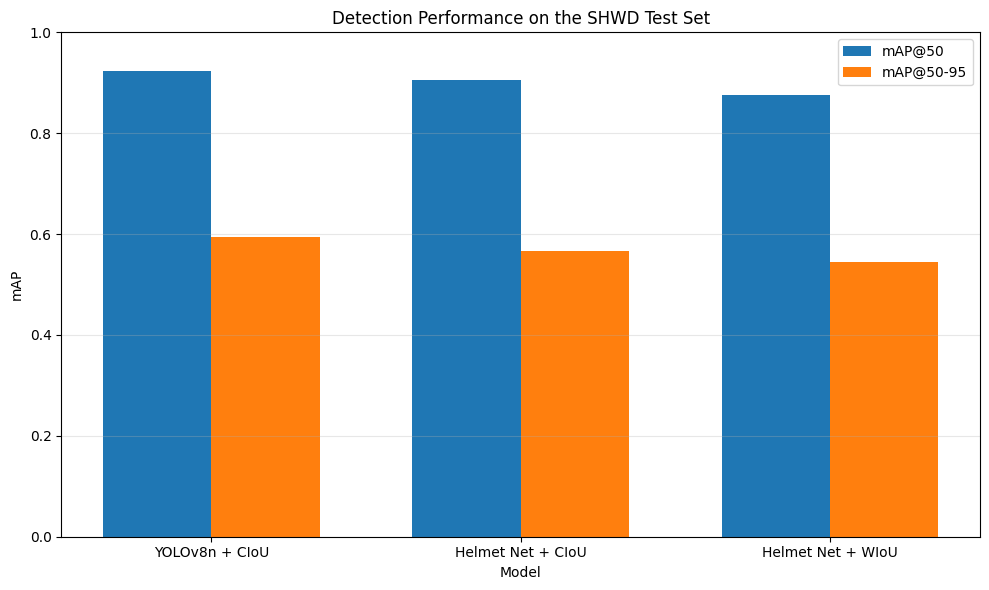

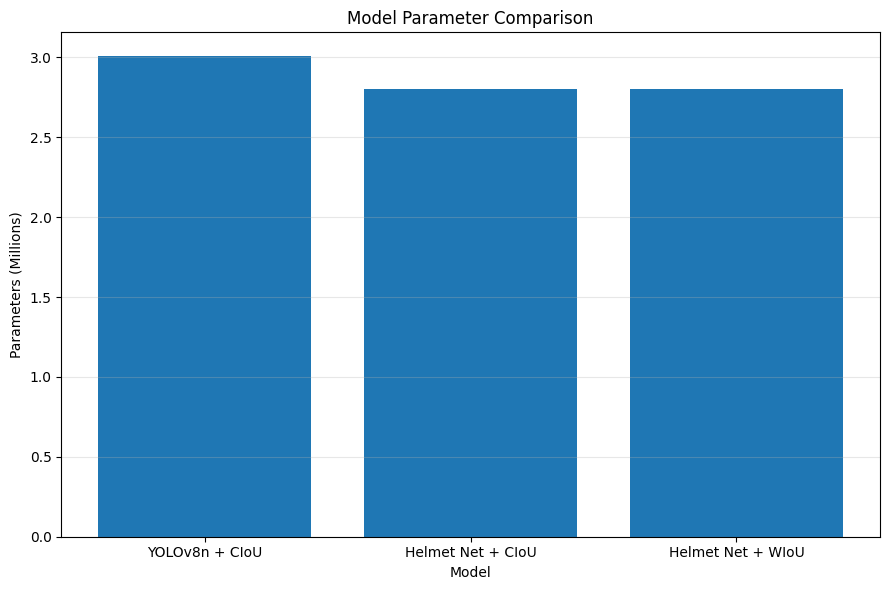

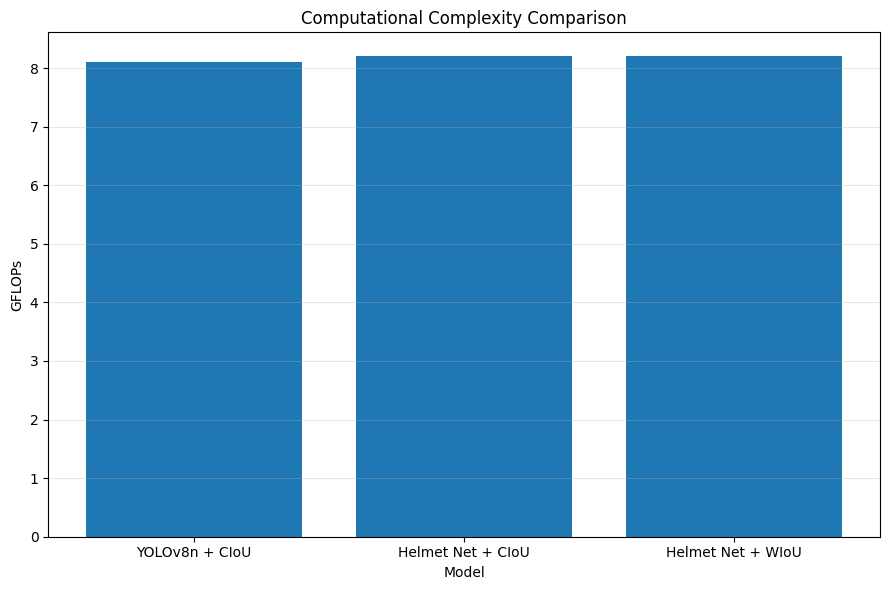

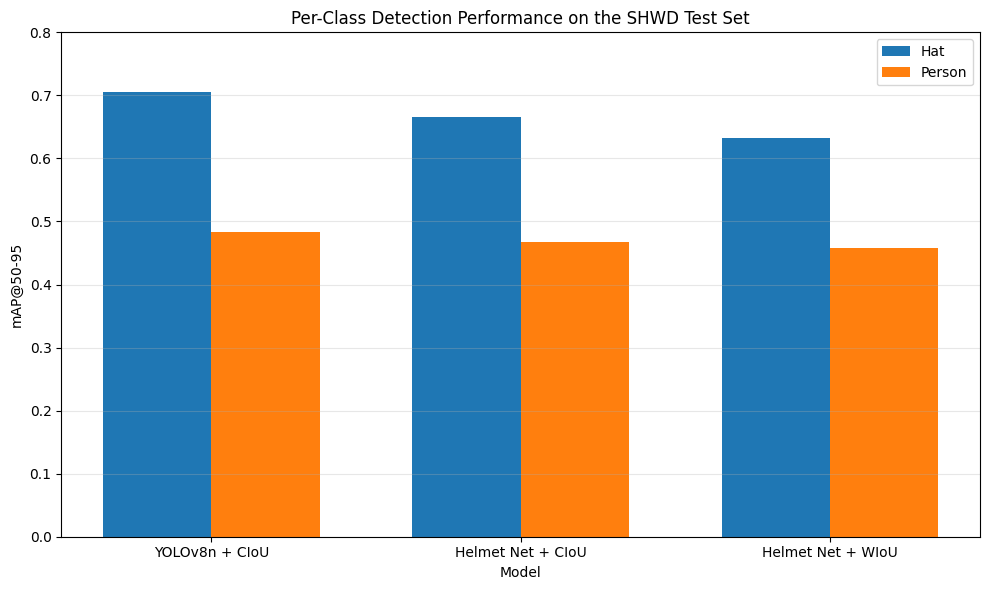

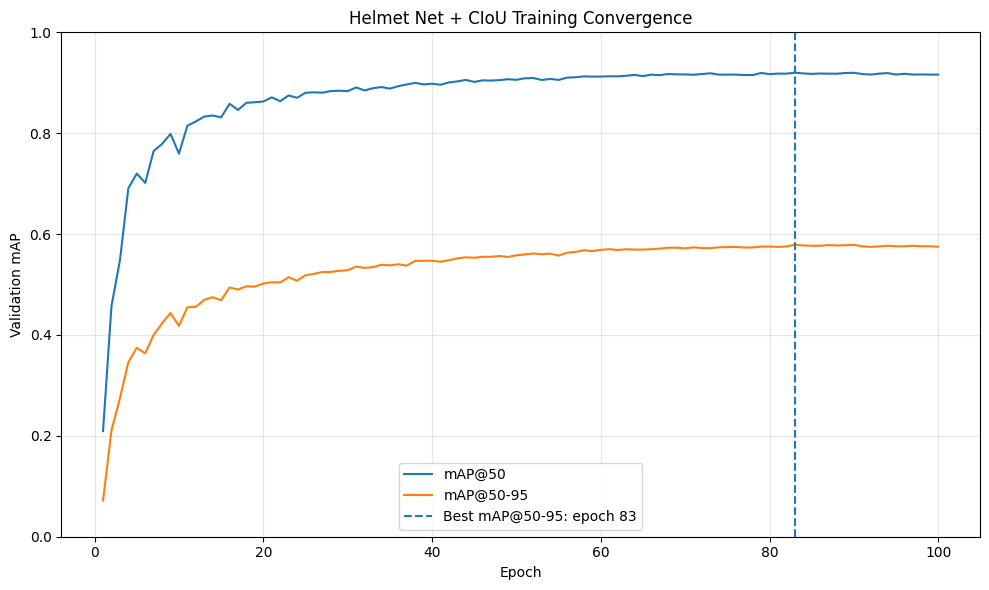


FIGURES CREATED SUCCESSFULLY
✅ figure4_ciou_training_convergence.png
✅ figure2b_gflops_comparison.png
✅ figure3_per_class_performance.png
✅ figure2_parameter_comparison.png
✅ figure1_detection_performance.png

Best CIoU validation epoch:
Epoch       : 83
mAP@50      : 0.92005
mAP@50-95   : 0.57904

Figure directory:
/kaggle/working/Helmet_Project/figures


In [11]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# PATHS
# ============================================================

BASE = Path("/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip")
CSV = BASE / "training_ciou_final" / "results.csv"

FIG_DIR = Path("/kaggle/working/Helmet_Project/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("CREATING HELMET DETECTION RESEARCH FIGURES")
print("=" * 70)

# ============================================================
# LOAD CIoU TRAINING HISTORY
# ============================================================

df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()

print(f"CIoU training history loaded: {len(df)} epochs")

# ============================================================
# FIGURE 1 — MODEL ACCURACY COMPARISON
# ============================================================

models = [
    "YOLOv8n + CIoU",
    "Helmet Net + CIoU",
    "Helmet Net + WIoU"
]

map50 = [0.9240, 0.9048, 0.8760]
map5095 = [0.5940, 0.5671, 0.5452]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, map50, width, label="mAP@50")
plt.bar(x + width/2, map5095, width, label="mAP@50-95")

plt.xticks(x, models)
plt.ylabel("mAP")
plt.xlabel("Model")
plt.title("Detection Performance on the SHWD Test Set")
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig1 = FIG_DIR / "figure1_detection_performance.png"
plt.savefig(fig1, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE 2 — MODEL COMPLEXITY
# ============================================================

params = [3.006038, 2.803670, 2.803670]
gflops = [8.1, 8.2, 8.2]

# Parameters
plt.figure(figsize=(9, 6))

plt.bar(models, params)

plt.ylabel("Parameters (Millions)")
plt.xlabel("Model")
plt.title("Model Parameter Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig2 = FIG_DIR / "figure2_parameter_comparison.png"
plt.savefig(fig2, dpi=300, bbox_inches="tight")
plt.show()

# GFLOPs
plt.figure(figsize=(9, 6))

plt.bar(models, gflops)

plt.ylabel("GFLOPs")
plt.xlabel("Model")
plt.title("Computational Complexity Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig2b = FIG_DIR / "figure2b_gflops_comparison.png"
plt.savefig(fig2b, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE 3 — PER-CLASS mAP@50-95
# ============================================================

hat_map = [0.7050, 0.6665, 0.6326]
person_map = [0.4830, 0.4677, 0.4578]

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, hat_map, width, label="Hat")
plt.bar(x + width/2, person_map, width, label="Person")

plt.xticks(x, models)
plt.ylabel("mAP@50-95")
plt.xlabel("Model")
plt.title("Per-Class Detection Performance on the SHWD Test Set")
plt.ylim(0, 0.8)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

fig3 = FIG_DIR / "figure3_per_class_performance.png"
plt.savefig(fig3, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE 4 — CIoU TRAINING CONVERGENCE
# ============================================================

best_idx = df["metrics/mAP50-95(B)"].idxmax()
best_epoch = int(df.loc[best_idx, "epoch"])
best_map95 = df.loc[best_idx, "metrics/mAP50-95(B)"]

plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["metrics/mAP50(B)"],
    label="mAP@50"
)

plt.plot(
    df["epoch"],
    df["metrics/mAP50-95(B)"],
    label="mAP@50-95"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best mAP@50-95: epoch {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation mAP")
plt.title("Helmet Net + CIoU Training Convergence")
plt.ylim(0, 1.0)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig4 = FIG_DIR / "figure4_ciou_training_convergence.png"
plt.savefig(fig4, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FIGURES CREATED SUCCESSFULLY")
print("=" * 70)

for p in FIG_DIR.iterdir():
    if p.is_file():
        print(f"✅ {p.name}")

print("\nBest CIoU validation epoch:")
print(f"Epoch       : {best_epoch}")
print(f"mAP@50      : {df.loc[best_idx, 'metrics/mAP50(B)']:.5f}")
print(f"mAP@50-95   : {best_map95:.5f}")

print("\nFigure directory:")
print(FIG_DIR)

print("=" * 70)

Figure exists: True
Path: /kaggle/working/Helmet_Project/figures/figure1_detection_performance.png


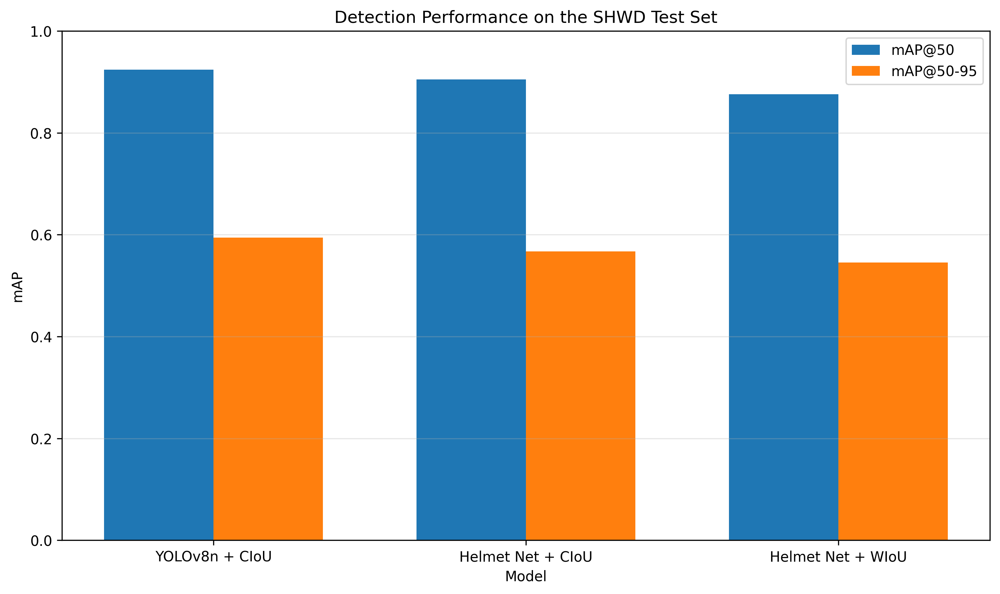

In [12]:
from IPython.display import Image, display
from pathlib import Path

fig = Path("/kaggle/working/Helmet_Project/figures/figure1_detection_performance.png")

print("Figure exists:", fig.exists())
print("Path:", fig)

display(Image(filename=str(fig)))

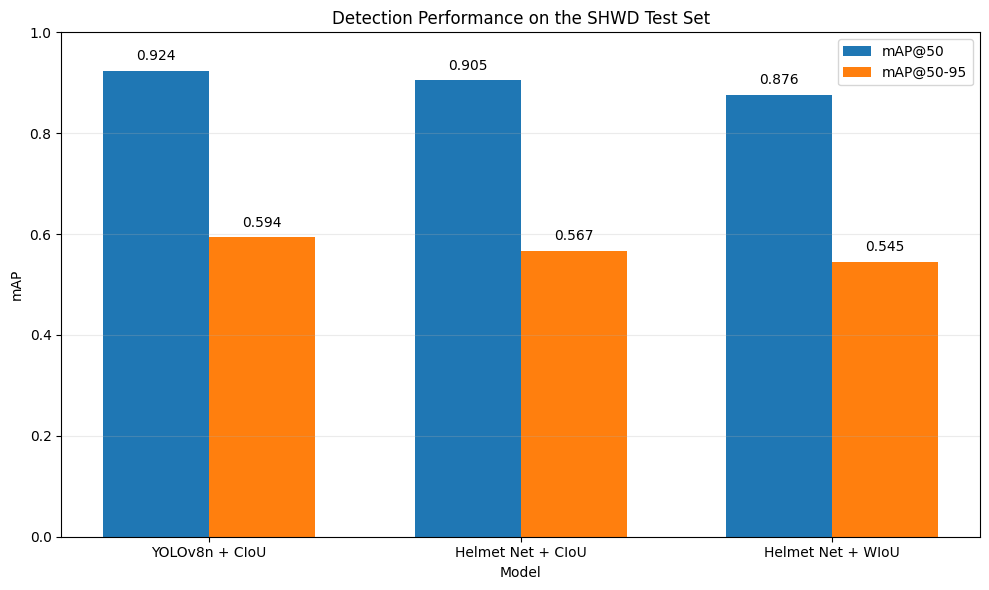

✅ Updated Figure 1:
/kaggle/working/Helmet_Project/figures/figure1_detection_performance.png


In [13]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = Path("/kaggle/working/Helmet_Project/figures")

models = [
    "YOLOv8n + CIoU",
    "Helmet Net + CIoU",
    "Helmet Net + WIoU"
]

map50 = [0.9240, 0.9048, 0.8760]
map5095 = [0.5940, 0.5671, 0.5452]

x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2,
    map50,
    width,
    label="mAP@50"
)

bars2 = ax.bar(
    x + width/2,
    map5095,
    width,
    label="mAP@50-95"
)

# Add numerical values
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

ax.set_ylabel("mAP")
ax.set_xlabel("Model")
ax.set_title("Detection Performance on the SHWD Test Set")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.0)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIG_DIR / "figure1_detection_performance.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Updated Figure 1:")
print(output)

Figure exists: True


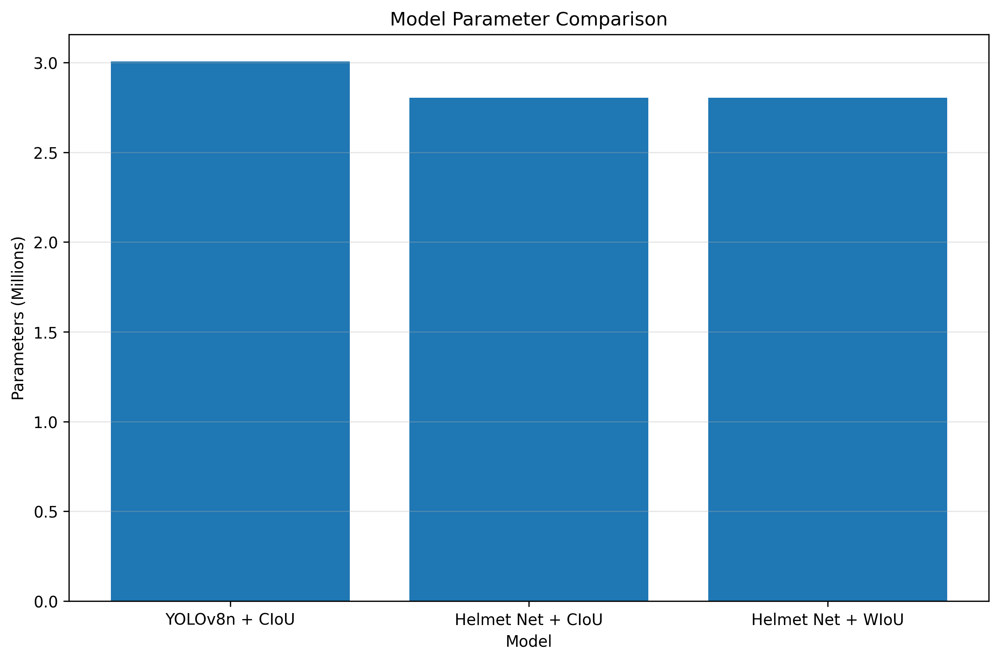

In [14]:
from IPython.display import Image, display
from pathlib import Path

fig = Path("/kaggle/working/Helmet_Project/figures/figure2_parameter_comparison.png")

print("Figure exists:", fig.exists())
display(Image(filename=str(fig)))

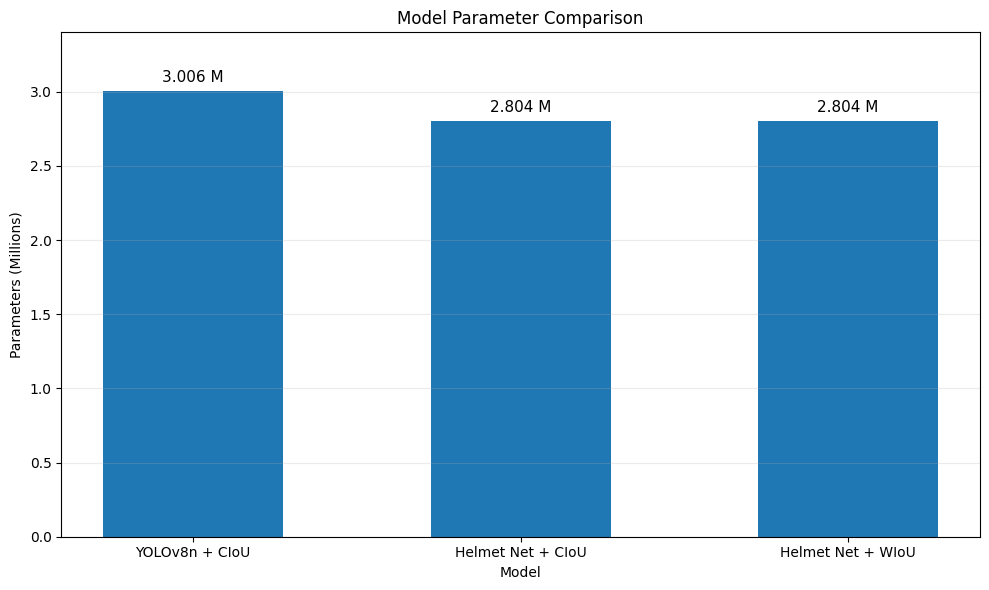

✅ Updated Figure 2:
/kaggle/working/Helmet_Project/figures/figure2_parameter_comparison.png

Parameter reduction:
YOLOv8n → Helmet Net: 6.73%


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("/kaggle/working/Helmet_Project/figures")

models = [
    "YOLOv8n + CIoU",
    "Helmet Net + CIoU",
    "Helmet Net + WIoU"
]

params = [3.006038, 2.803670, 2.803670]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(models, params, width=0.55)

# Add exact values
for bar, value in zip(bars, params):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.04,
        f"{value:.3f} M",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylabel("Parameters (Millions)")
ax.set_xlabel("Model")
ax.set_title("Model Parameter Comparison")
ax.set_ylim(0, 3.4)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIG_DIR / "figure2_parameter_comparison.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Updated Figure 2:")
print(output)

print("\nParameter reduction:")
reduction = (params[0] - params[1]) / params[0] * 100
print(f"YOLOv8n → Helmet Net: {reduction:.2f}%")

Figure exists: True


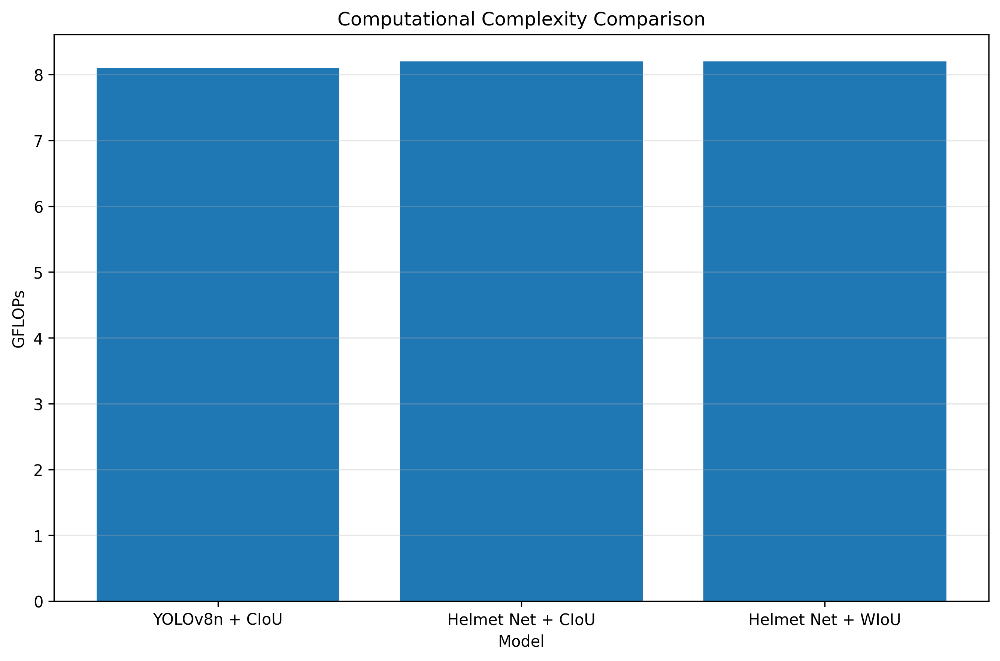

In [16]:
from IPython.display import Image, display
from pathlib import Path

fig = Path("/kaggle/working/Helmet_Project/figures/figure2b_gflops_comparison.png")

print("Figure exists:", fig.exists())
display(Image(filename=str(fig)))

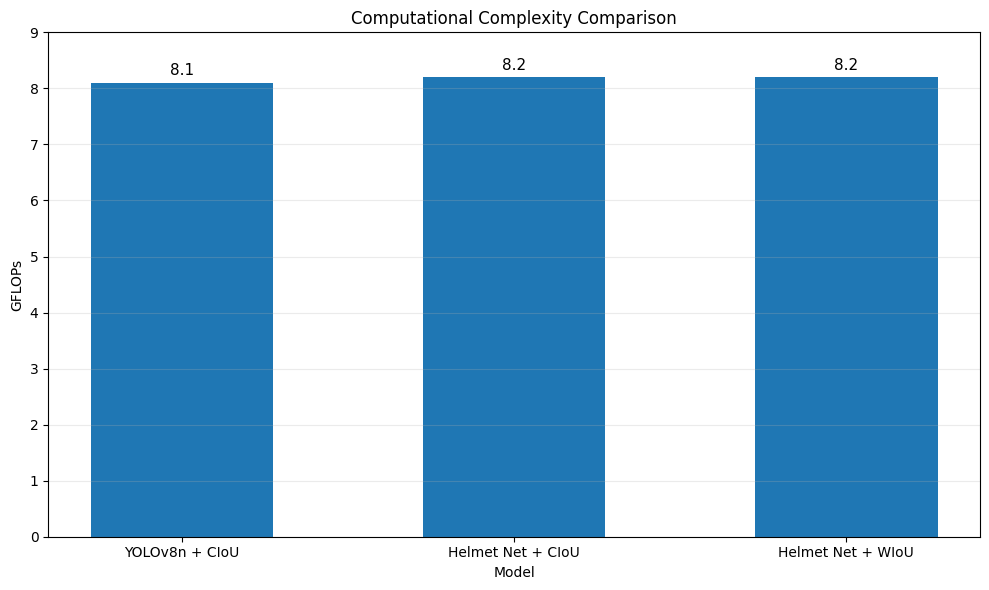

✅ Updated Figure 2b:
/kaggle/working/Helmet_Project/figures/figure2b_gflops_comparison.png


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("/kaggle/working/Helmet_Project/figures")

models = [
    "YOLOv8n + CIoU",
    "Helmet Net + CIoU",
    "Helmet Net + WIoU"
]

gflops = [8.1, 8.2, 8.2]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(models, gflops, width=0.55)

# Add exact GFLOPs values
for bar, value in zip(bars, gflops):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.08,
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylabel("GFLOPs")
ax.set_xlabel("Model")
ax.set_title("Computational Complexity Comparison")
ax.set_ylim(0, 9)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIG_DIR / "figure2b_gflops_comparison.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Updated Figure 2b:")
print(output)

Figure exists: True


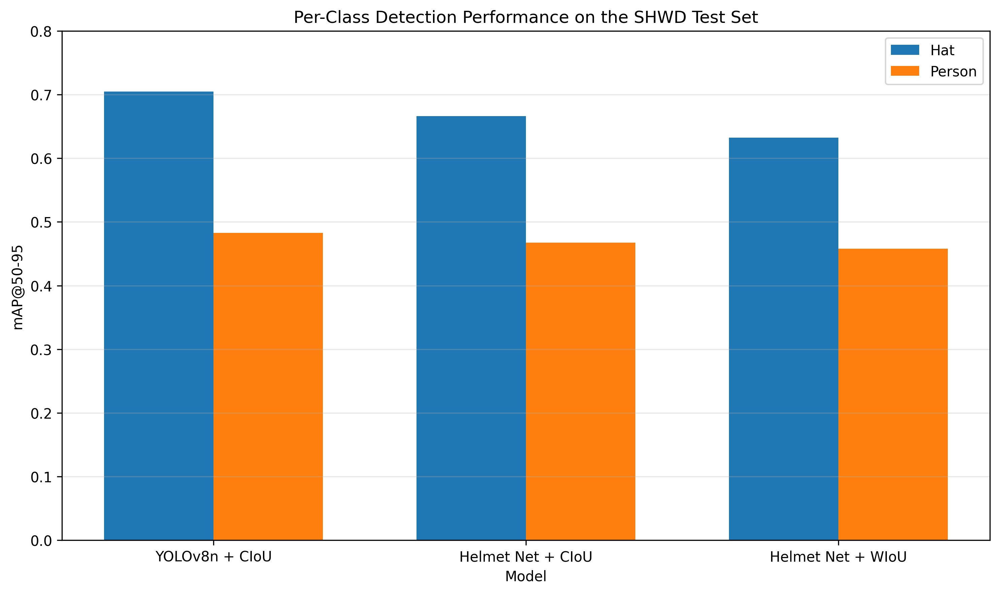

In [18]:
from IPython.display import Image, display
from pathlib import Path

fig = Path("/kaggle/working/Helmet_Project/figures/figure3_per_class_performance.png")

print("Figure exists:", fig.exists())
display(Image(filename=str(fig)))

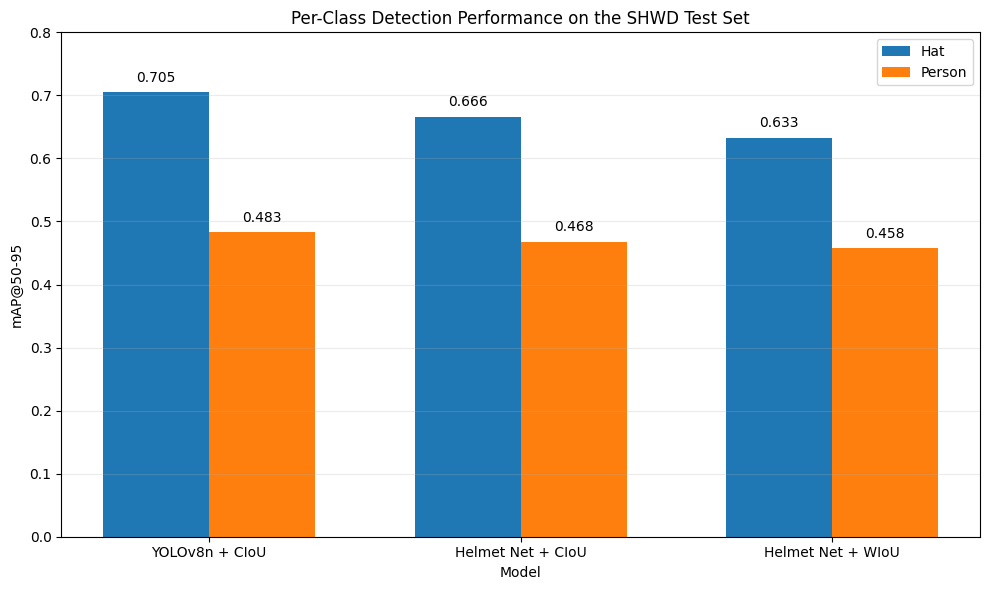

✅ Updated Figure 3:
/kaggle/working/Helmet_Project/figures/figure3_per_class_performance.png


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("/kaggle/working/Helmet_Project/figures")

models = [
    "YOLOv8n + CIoU",
    "Helmet Net + CIoU",
    "Helmet Net + WIoU"
]

hat_map = [0.7050, 0.6665, 0.6326]
person_map = [0.4830, 0.4677, 0.4578]

x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2,
    hat_map,
    width,
    label="Hat"
)

bars2 = ax.bar(
    x + width/2,
    person_map,
    width,
    label="Person"
)

# Add exact values
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.012,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

ax.set_ylabel("mAP@50-95")
ax.set_xlabel("Model")
ax.set_title("Per-Class Detection Performance on the SHWD Test Set")

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 0.8)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

output = FIG_DIR / "figure3_per_class_performance.png"
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("✅ Updated Figure 3:")
print(output)

Figure exists: True


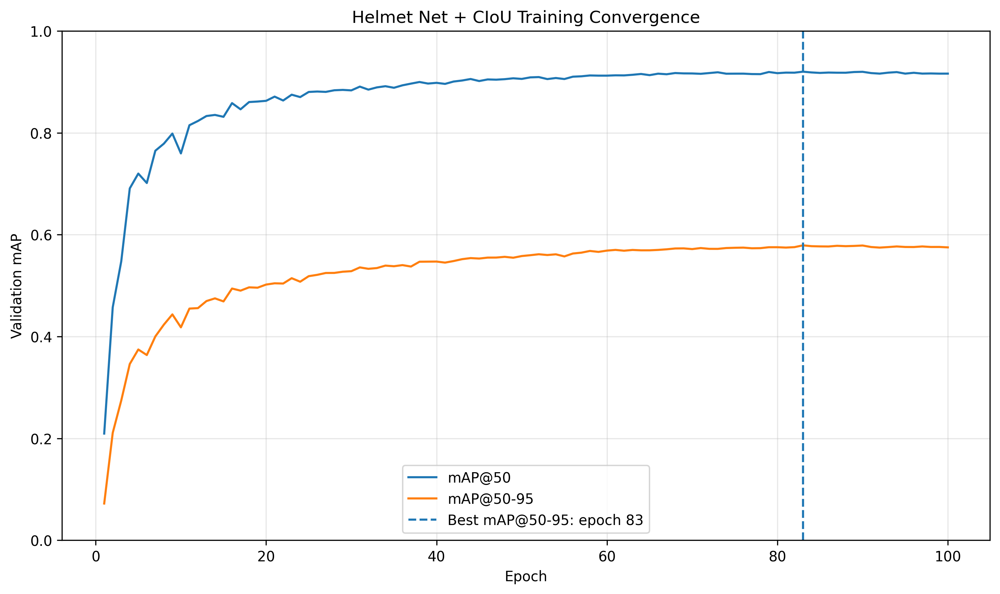

In [20]:
from IPython.display import Image, display
from pathlib import Path

fig = Path("/kaggle/working/Helmet_Project/figures/figure4_ciou_training_convergence.png")

print("Figure exists:", fig.exists())
display(Image(filename=str(fig)))

In [21]:
import pandas as pd
from pathlib import Path

# ============================================================
# FINAL SHWD TEST-SET RESULTS
# ============================================================

results = pd.DataFrame({
    "Model": [
        "YOLOv8n + CIoU",
        "Helmet Net + CIoU",
        "Helmet Net + WIoU"
    ],

    "Parameters (M)": [
        3.006038,
        2.803670,
        2.803670
    ],

    "GFLOPs": [
        8.1,
        8.2,
        8.2
    ],

    "Precision": [
        0.9200,
        0.9134,
        0.8886
    ],

    "Recall": [
        0.8700,
        0.8419,
        0.8135
    ],

    "mAP@50": [
        0.9240,
        0.9048,
        0.8760
    ],

    "mAP@50-95": [
        0.5940,
        0.5671,
        0.5452
    ],

    "Hat mAP@50-95": [
        0.7050,
        0.6665,
        0.6326
    ],

    "Person mAP@50-95": [
        0.4830,
        0.4677,
        0.4578
    ]
})

# Display
display(
    results.style
    .format({
        "Parameters (M)": "{:.3f}",
        "GFLOPs": "{:.1f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "mAP@50": "{:.4f}",
        "mAP@50-95": "{:.4f}",
        "Hat mAP@50-95": "{:.4f}",
        "Person mAP@50-95": "{:.4f}"
    })
)

# Save CSV
OUT_DIR = Path("/kaggle/working/Helmet_Project/final_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUT_DIR / "final_shwd_results.csv"
results.to_csv(csv_path, index=False)

print("\n" + "=" * 70)
print("FINAL RESULTS TABLE SAVED")
print("=" * 70)
print(csv_path)

,Model,Parameters (M),GFLOPs,Precision,Recall,mAP@50,mAP@50-95,Hat mAP@50-95,Person mAP@50-95
0,YOLOv8n + CIoU,3.006,8.1,0.9200,0.8700,0.9240,0.5940,0.7050,0.4830
1,Helmet Net + CIoU,2.804,8.2,0.9134,0.8419,0.9048,0.5671,0.6665,0.4677
2,Helmet Net + WIoU,2.804,8.2,0.8886,0.8135,0.8760,0.5452,0.6326,0.4578



FINAL RESULTS TABLE SAVED
/kaggle/working/Helmet_Project/final_results/final_shwd_results.csv


In [22]:
import pandas as pd
from pathlib import Path

CSV = Path(
    "/kaggle/working/Helmet_Project/final_results/final_shwd_results.csv"
)

df = pd.read_csv(CSV)

baseline = df.iloc[0]
helmet_ciou = df.iloc[1]
helmet_wiou = df.iloc[2]

def pct_change(new, old):
    return (new - old) / old * 100

print("=" * 75)
print("FINAL EXPERIMENTAL ANALYSIS")
print("=" * 75)

# ============================================================
# 1. YOLOv8n → Helmet Net + CIoU
# ============================================================

print("\n1. YOLOv8n + CIoU  →  Helmet Net + CIoU")
print("-" * 75)

for metric in [
    "Parameters (M)",
    "GFLOPs",
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@50-95",
    "Hat mAP@50-95",
    "Person mAP@50-95"
]:
    change = pct_change(helmet_ciou[metric], baseline[metric])
    print(f"{metric:22s}: {change:+.2f}%")

# ============================================================
# 2. Helmet Net + CIoU → Helmet Net + WIoU
# ============================================================

print("\n2. Helmet Net + CIoU  →  Helmet Net + WIoU")
print("-" * 75)

for metric in [
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@50-95",
    "Hat mAP@50-95",
    "Person mAP@50-95"
]:
    change = pct_change(helmet_wiou[metric], helmet_ciou[metric])
    print(f"{metric:22s}: {change:+.2f}%")

# ============================================================
# 3. Absolute differences in percentage points
# ============================================================

print("\n3. Absolute Metric Differences")
print("-" * 75)

for metric in [
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@50-95"
]:
    diff = helmet_ciou[metric] - baseline[metric]
    print(
        f"{metric:22s}: "
        f"{diff:+.4f} "
        f"({diff*100:+.2f} percentage points)"
    )

print("\n" + "=" * 75)
print("KEY FINDINGS")
print("=" * 75)

param_reduction = (
    (baseline["Parameters (M)"] - helmet_ciou["Parameters (M)"])
    / baseline["Parameters (M)"]
    * 100
)

map50_drop = (
    (helmet_ciou["mAP@50"] - baseline["mAP@50"])
    * 100
)

map5095_drop = (
    (helmet_ciou["mAP@50-95"] - baseline["mAP@50-95"])
    * 100
)

wiou_map50_drop = (
    (helmet_wiou["mAP@50"] - helmet_ciou["mAP@50"])
    * 100
)

wiou_map5095_drop = (
    (helmet_wiou["mAP@50-95"] - helmet_ciou["mAP@50-95"])
    * 100
)

print(f"\nParameter reduction: {param_reduction:.2f}%")
print(f"Helmet Net mAP@50 change: {map50_drop:+.2f} percentage points")
print(f"Helmet Net mAP@50-95 change: {map5095_drop:+.2f} percentage points")
print(f"WIoU mAP@50 change vs CIoU: {wiou_map50_drop:+.2f} percentage points")
print(f"WIoU mAP@50-95 change vs CIoU: {wiou_map5095_drop:+.2f} percentage points")

print("=" * 75)

FINAL EXPERIMENTAL ANALYSIS

1. YOLOv8n + CIoU  →  Helmet Net + CIoU
---------------------------------------------------------------------------
Parameters (M)        : -6.73%
GFLOPs                : +1.23%
Precision             : -0.72%
Recall                : -3.23%
mAP@50                : -2.08%
mAP@50-95             : -4.53%
Hat mAP@50-95         : -5.46%
Person mAP@50-95      : -3.17%

2. Helmet Net + CIoU  →  Helmet Net + WIoU
---------------------------------------------------------------------------
Precision             : -2.72%
Recall                : -3.37%
mAP@50                : -3.18%
mAP@50-95             : -3.86%
Hat mAP@50-95         : -5.09%
Person mAP@50-95      : -2.12%

3. Absolute Metric Differences
---------------------------------------------------------------------------
Precision             : -0.0066 (-0.66 percentage points)
Recall                : -0.0281 (-2.81 percentage points)
mAP@50                : -0.0192 (-1.92 percentage points)
mAP@50-95          

In [23]:
from pathlib import Path

print("=" * 70)
print("SEARCHING FOR SHWD TEST IMAGES")
print("=" * 70)

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

found = []

for root in roots:
    if root.exists():
        for p in root.rglob("test"):
            if p.is_dir():
                jpgs = list(p.glob("*.jpg")) + list(p.glob("*.jpeg")) + list(p.glob("*.JPG"))
                if len(jpgs) > 0:
                    found.append((p, len(jpgs)))

if found:
    print("\nPossible test-image directories:\n")
    for path, count in found:
        print(f"✅ {path}")
        print(f"   Images: {count}")
else:
    print("❌ No test-image directory found")

print("=" * 70)

SEARCHING FOR SHWD TEST IMAGES
❌ No test-image directory found


In [24]:
from pathlib import Path

print("=" * 70)
print("SEARCHING FOR SHWD DATASET")
print("=" * 70)

targets = [
    "SHWD_YOLO_FINAL",
    "VOC2028",
    "JPEGImages"
]

found = []

for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
    if root.exists():
        for target in targets:
            for p in root.rglob(target):
                if p.is_dir():
                    found.append(p)

found = list(dict.fromkeys(found))

if found:
    print("\nFound directories:\n")
    for p in found:
        print("✅", p)
else:
    print("❌ SHWD dataset directories not found")

print("=" * 70)

SEARCHING FOR SHWD DATASET

Found directories:

✅ /kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/data/SHWD_YOLO_FINAL
✅ /kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028
✅ /kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages


In [25]:
from pathlib import Path

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

MODEL = BASE / "training_ciou_final" / "weights" / "best.pt"
DATASET = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"
)

print("=" * 70)
print("QUALITATIVE EVALUATION SETUP")
print("=" * 70)

print("Model:")
print(MODEL)
print("Exists:", MODEL.exists())

print("\nSHWD images:")
IMG_DIR = DATASET / "JPEGImages"
print(IMG_DIR)
print("Exists:", IMG_DIR.exists())

if IMG_DIR.exists():
    images = list(IMG_DIR.glob("*.jpg"))
    print("Number of images:", len(images))

print("=" * 70)

QUALITATIVE EVALUATION SETUP
Model:
/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/training_ciou_final/weights/best.pt
Exists: True

SHWD images:
/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages
Exists: True
Number of images: 7571


In [26]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

MODEL_PATH = BASE / "training_ciou_final" / "weights" / "best.pt"

IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

OUT_DIR = Path("/kaggle/working/Helmet_Project/qualitative_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD MODEL
# ============================================================

print("=" * 70)
print("LOADING HELMET NET + CIOU")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("✅ Model loaded")
print("Classes:", model.names)

# ============================================================
# SELECT 6 IMAGES
# ============================================================

images = sorted(
    list(IMG_DIR.glob("*.jpg")) +
    list(IMG_DIR.glob("*.jpeg")) +
    list(IMG_DIR.glob("*.JPG"))
)

random.seed(42)
selected = random.sample(images, 6)

print("\nSelected images:")
for img in selected:
    print(img.name)

# ============================================================
# RUN INFERENCE
# ============================================================

results = model.predict(
    source=[str(x) for x in selected],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

# ============================================================
# SAVE INDIVIDUAL PREDICTIONS
# ============================================================

for img_path, result in zip(selected, results):
    plotted = result.plot()

    output_path = OUT_DIR / f"pred_{img_path.stem}.jpg"

    import cv2
    cv2.imwrite(str(output_path), plotted)

print("\n✅ Individual prediction images saved.")

# ============================================================
# CREATE 2 × 3 QUALITATIVE FIGURE
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, img_path, result in zip(axes.flat, selected, results):

    plotted = result.plot()

    # Convert BGR → RGB
    plotted = plotted[:, :, ::-1]

    ax.imshow(plotted)
    ax.set_title(img_path.name, fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Qualitative Detection Results of Helmet Net + CIoU on SHWD",
    fontsize=16
)

plt.tight_layout()

figure_path = OUT_DIR / "qualitative_detection_results.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("QUALITATIVE FIGURE CREATED")
print("=" * 70)
print(figure_path)
print("=" * 70)

ModuleNotFoundError: No module named 'ultralytics'

In [27]:
!pip -q install ultralytics==8.4.167

import ultralytics
print("Ultralytics version:", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 3.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.167


In [28]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO
import cv2

# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

MODEL_PATH = BASE / "training_ciou_final" / "weights" / "best.pt"

IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

OUT_DIR = Path("/kaggle/working/Helmet_Project/qualitative_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD MODEL
# ============================================================

print("=" * 70)
print("LOADING HELMET NET + CIoU")
print("=" * 70)

model = YOLO(str(MODEL_PATH))

print("✅ Model loaded")
print("Classes:", model.names)

# ============================================================
# SELECT 6 IMAGES
# ============================================================

images = sorted(
    list(IMG_DIR.glob("*.jpg")) +
    list(IMG_DIR.glob("*.jpeg")) +
    list(IMG_DIR.glob("*.JPG"))
)

random.seed(42)
selected = random.sample(images, 6)

print("\nSelected images:")
for img in selected:
    print(img.name)

# ============================================================
# RUN INFERENCE
# ============================================================

results = model.predict(
    source=[str(x) for x in selected],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

# ============================================================
# SAVE INDIVIDUAL PREDICTIONS
# ============================================================

for img_path, result in zip(selected, results):
    plotted = result.plot()

    output_path = OUT_DIR / f"pred_{img_path.stem}.jpg"
    cv2.imwrite(str(output_path), plotted)

print("\n✅ Individual prediction images saved.")

# ============================================================
# CREATE 2 × 3 QUALITATIVE FIGURE
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, img_path, result in zip(axes.flat, selected, results):

    plotted = result.plot()
    plotted = plotted[:, :, ::-1]

    ax.imshow(plotted)
    ax.set_title(img_path.name, fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Qualitative Detection Results of Helmet Net + CIoU on SHWD",
    fontsize=16
)

plt.tight_layout()

figure_path = OUT_DIR / "qualitative_detection_results.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("QUALITATIVE FIGURE CREATED")
print("=" * 70)
print(figure_path)
print("=" * 70)

LOADING HELMET NET + CIoU
WARNING ⚠️ /kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/training_ciou_final/weights/best.pt appears to require 'custom_modules', which is not in Ultralytics requirements.
AutoInstall will run now for 'custom_modules' but this feature will be removed in the future.
Recommended fixes are to train a new model using the latest 'ultralytics' package or to run a command with an official Ultralytics model, i.e. 'yolo predict model=yolo26n.pt'
requirements: Ultralytics requirement ['custom_modules'] not found, attempting AutoUpdate...
WARNING ⚠️ Retry 1/2 failed: Command '['uv', 'pip', 'install', '--no-cache-dir', '--python', '/usr/bin/python3', 'custom_modules', '--index-strategy=unsafe-best-match', '--break-system-packages']' returned non-zero exit status 1.
WARNING ⚠️ Retry 2/2 failed: Command '['uv', 'pip', 'install', '--no-cache-dir', '--python', '/usr/bin/python3', 'custom_modules', '--index-strategy=unsafe-best-match', '--break-syste

ModuleNotFoundError: No module named 'custom_modules'

In [29]:
from pathlib import Path
import sys
import ultralytics.nn.tasks as tasks

# ============================================================
# RESTORE THE EXACT CUSTOM MODULES USED DURING TRAINING
# ============================================================

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

CODE_DIR = BASE / "code"
CUSTOM_MODULES = CODE_DIR / "custom_modules.py"

print("=" * 70)
print("RESTORING CUSTOM MODULES")
print("=" * 70)

print("custom_modules.py:")
print(CUSTOM_MODULES)
print("Exists:", CUSTOM_MODULES.exists())

# Add artifact code directory to Python path
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Import exact saved classes
from custom_modules import LC_CBS, SE_C2f

# Register them with Ultralytics parser
tasks.LC_CBS = LC_CBS
tasks.SE_C2f = SE_C2f

print("\n✅ LC_CBS registered:", tasks.LC_CBS)
print("✅ SE_C2f registered:", tasks.SE_C2f)

print("=" * 70)

RESTORING CUSTOM MODULES
custom_modules.py:
/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/code/custom_modules.py
Exists: True

✅ LC_CBS registered: <class 'custom_modules.LC_CBS'>
✅ SE_C2f registered: <class 'custom_modules.SE_C2f'>


In [30]:
from pathlib import Path
import inspect
import ultralytics.nn.tasks as tasks

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

PATCH_FILE = BASE / "code" / "parser_patch.py"

print("=" * 70)
print("RESTORING ULTRALYTICS PARSER PATCH")
print("=" * 70)

print("Patch file:")
print(PATCH_FILE)
print("Exists:", PATCH_FILE.exists())

# Read the exact saved parser patch
source = PATCH_FILE.read_text()

print("\nPatch file size:", len(source), "characters")

# Execute the saved patch exactly
exec(
    compile(
        source,
        str(PATCH_FILE),
        "exec"
    ),
    globals(),
    globals()
)

print("\n✅ Parser patch executed")

# Verify the custom classes are available to parse_model
parse_globals = tasks.parse_model.__globals__

print("LC_CBS in parser globals:", "LC_CBS" in parse_globals)
print("SE_C2f in parser globals:", "SE_C2f" in parse_globals)

print("=" * 70)

RESTORING ULTRALYTICS PARSER PATCH
Patch file:
/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/code/parser_patch.py
Exists: True

Patch file size: 1046 characters

✅ Parser patch executed
LC_CBS in parser globals: True
SE_C2f in parser globals: True


In [31]:
from pathlib import Path
from ultralytics import YOLO

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

MODEL_PATH = (
    BASE
    / "training_ciou_final"
    / "weights"
    / "best.pt"
)

print("=" * 70)
print("LOADING TRAINED HELMET NET + CIoU")
print("=" * 70)

print("Model:", MODEL_PATH)
print("Exists:", MODEL_PATH.exists())

model = YOLO(str(MODEL_PATH))

print("\n✅ MODEL LOADED SUCCESSFULLY")
print("Model classes:", model.names)

print("=" * 70)

LOADING TRAINED HELMET NET + CIoU
Model: /kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip/training_ciou_final/weights/best.pt
Exists: True

✅ MODEL LOADED SUCCESSFULLY
Model classes: {0: 'hat', 1: 'person'}


SELECTED QUALITATIVE TEST IMAGES
PartB_01682.jpg
000960.jpg
000222.jpg
part2_000183.jpg
PartA_00646.jpg
PartA_00398.jpg

✅ Inference completed
PartB_01682.jpg: 13 detections
000960.jpg: 7 detections
000222.jpg: 19 detections
part2_000183.jpg: 2 detections
PartA_00646.jpg: 86 detections
PartA_00398.jpg: 4 detections


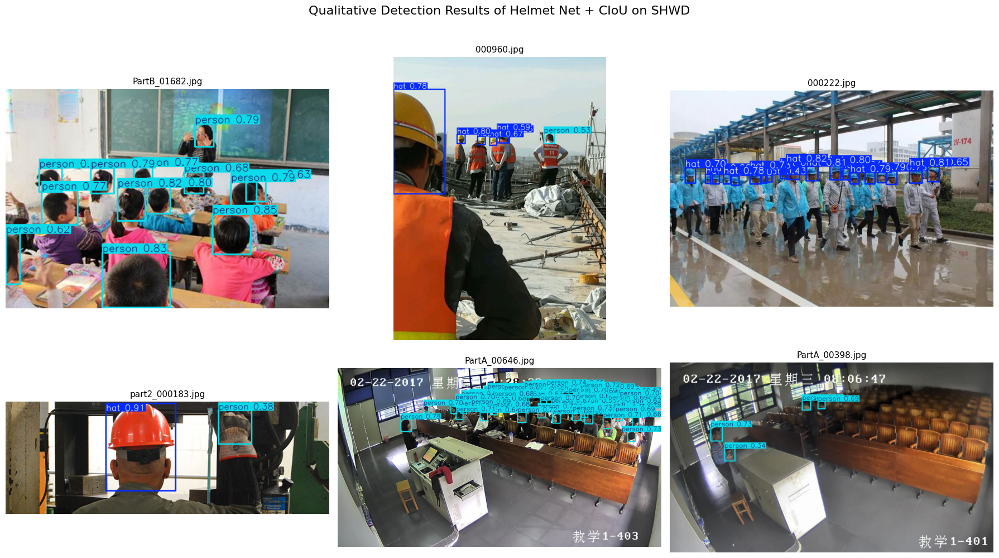


QUALITATIVE FIGURE CREATED
/kaggle/working/Helmet_Project/qualitative_results/qualitative_detection_results.png


In [32]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import cv2

# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/kaggle/input/datasets/srijathodenga/helmet-net-ciou-final-artifacts-zip"
)

IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

OUT_DIR = Path(
    "/kaggle/working/Helmet_Project/qualitative_results"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# SELECT 6 FIXED IMAGES
# ============================================================

images = sorted(
    list(IMG_DIR.glob("*.jpg")) +
    list(IMG_DIR.glob("*.jpeg")) +
    list(IMG_DIR.glob("*.JPG"))
)

random.seed(42)
selected = random.sample(images, 6)

print("=" * 70)
print("SELECTED QUALITATIVE TEST IMAGES")
print("=" * 70)

for img in selected:
    print(img.name)

# ============================================================
# RUN INFERENCE
# ============================================================

results = model.predict(
    source=[str(x) for x in selected],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

print("\n✅ Inference completed")

# ============================================================
# CREATE 2 × 3 FIGURE
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, img_path, result in zip(axes.flat, selected, results):

    plotted = result.plot()

    # OpenCV BGR → Matplotlib RGB
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    ax.imshow(plotted)
    ax.set_title(img_path.name, fontsize=11)
    ax.axis("off")

    # Print detections
    if result.boxes is not None:
        print(
            f"{img_path.name}: "
            f"{len(result.boxes)} detections"
        )

plt.suptitle(
    "Qualitative Detection Results of Helmet Net + CIoU on SHWD",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = OUT_DIR / "qualitative_detection_results.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("QUALITATIVE FIGURE CREATED")
print("=" * 70)
print(figure_path)
print("=" * 70)

Figure exists: True


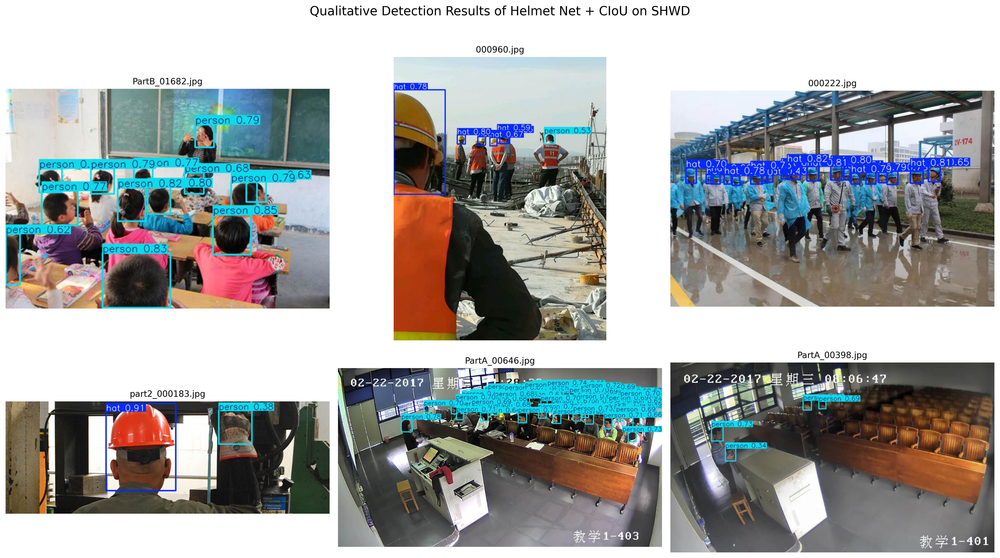

In [33]:
from IPython.display import Image, display
from pathlib import Path

fig = Path(
    "/kaggle/working/Helmet_Project/qualitative_results/qualitative_detection_results.png"
)

print("Figure exists:", fig.exists())
display(Image(filename=str(fig)))

In [34]:
from pathlib import Path
import random

# Use the already loaded `model`
IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

images = sorted(
    list(IMG_DIR.glob("*.jpg")) +
    list(IMG_DIR.glob("*.jpeg")) +
    list(IMG_DIR.glob("*.JPG"))
)

random.seed(123)
candidates = random.sample(images, 40)

print("=" * 70)
print("SEARCHING FOR CLEAN QUALITATIVE EXAMPLE")
print("=" * 70)

candidate_results = []

for img in candidates:
    result = model.predict(
        source=str(img),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    n = len(result.boxes)

    # Count predicted classes
    hat_count = 0
    person_count = 0

    if result.boxes is not None and len(result.boxes) > 0:
        classes = result.boxes.cls.cpu().numpy().astype(int)

        hat_count = int((classes == 0).sum())
        person_count = int((classes == 1).sum())

    # Prefer moderate number of detections and both classes
    if 3 <= n <= 20:
        candidate_results.append(
            (img, n, hat_count, person_count)
        )

print("\nSuitable candidates:\n")

for img, n, hats, persons in candidate_results[:15]:
    print(
        f"{img.name:25s} "
        f"detections={n:2d} | "
        f"hat={hats:2d} | "
        f"person={persons:2d}"
    )

print("\n" + "=" * 70)
print(f"Found {len(candidate_results)} suitable candidates")
print("=" * 70)

SEARCHING FOR CLEAN QUALITATIVE EXAMPLE

Suitable candidates:

PartA_00584.jpg           detections=11 | hat= 0 | person=11
part2_000526.jpg          detections= 9 | hat= 7 | person= 2
part2_002086.jpg          detections=10 | hat=10 | person= 0
part2_001783.jpg          detections= 3 | hat= 3 | person= 0
000332.jpg                detections=11 | hat=11 | person= 0
PartA_01498.jpg           detections= 6 | hat= 0 | person= 6
PartB_00814.jpg           detections= 8 | hat= 0 | person= 8
PartB_01034.jpg           detections= 7 | hat= 0 | person= 7
PartA_01114.jpg           detections= 4 | hat= 0 | person= 4
PartA_01184.jpg           detections=10 | hat= 0 | person=10
001363.jpg                detections=16 | hat=16 | person= 0
PartA_01155.jpg           detections= 6 | hat= 0 | person= 6
PartB_01022.jpg           detections= 8 | hat= 0 | person= 8
PartA_01127.jpg           detections= 6 | hat= 0 | person= 6
PartA_01966.jpg           detections=12 | hat= 0 | person=12

Found 18 suitable can

In [35]:
from pathlib import Path

DATASET = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028"
)

TEST_FILE = DATASET / "ImageSets" / "Main" / "test.txt"

candidates = [
    "part2_000526.jpg",
    "part2_002086.jpg",
    "000332.jpg",
    "part2_001783.jpg",
    "001363.jpg",
]

print("=" * 70)
print("CHECKING QUALITATIVE CANDIDATES AGAINST OFFICIAL TEST SPLIT")
print("=" * 70)

print("Test split file:", TEST_FILE)
print("Exists:", TEST_FILE.exists())

test_ids = set()

if TEST_FILE.exists():
    for line in TEST_FILE.read_text().splitlines():
        line = line.strip()
        if line:
            test_ids.add(Path(line).stem)

print("Official test images:", len(test_ids))

print("\nCandidate membership:\n")

for name in candidates:
    stem = Path(name).stem
    status = stem in test_ids
    print(f"{name:25s} -> {'✅ TEST SET' if status else '❌ NOT TEST SET'}")

print("=" * 70)

CHECKING QUALITATIVE CANDIDATES AGAINST OFFICIAL TEST SPLIT
Test split file: /kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/ImageSets/Main/test.txt
Exists: True
Official test images: 1517

Candidate membership:

part2_000526.jpg          -> ❌ NOT TEST SET
part2_002086.jpg          -> ❌ NOT TEST SET
000332.jpg                -> ✅ TEST SET
part2_001783.jpg          -> ✅ TEST SET
001363.jpg                -> ✅ TEST SET


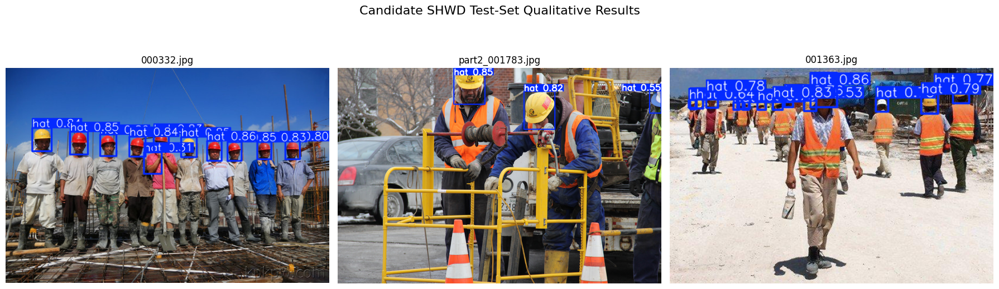

In [36]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

candidates = [
    "000332.jpg",
    "part2_001783.jpg",
    "001363.jpg"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, name in zip(axes, candidates):

    img_path = IMG_DIR / name

    result = model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    plotted = result.plot()
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    ax.imshow(plotted)
    ax.set_title(name, fontsize=12)
    ax.axis("off")

plt.suptitle(
    "Candidate SHWD Test-Set Qualitative Results",
    fontsize=16
)

plt.tight_layout()
plt.show()

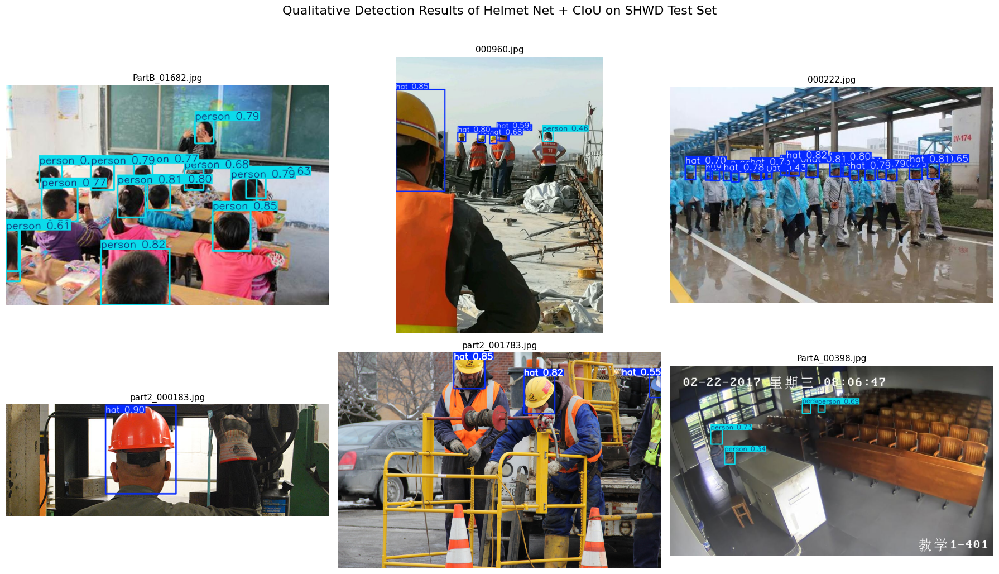

FINAL QUALITATIVE FIGURE
Saved: /kaggle/working/Helmet_Project/qualitative_results/qualitative_detection_results.png


In [37]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

IMG_DIR = Path(
    "/kaggle/input/datasets/srijathodenga/shwd-official-helmet-dataset/VOC2028/JPEGImages"
)

OUT_DIR = Path(
    "/kaggle/working/Helmet_Project/qualitative_results"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Final six test-set examples
selected_names = [
    "PartB_01682.jpg",
    "000960.jpg",
    "000222.jpg",
    "part2_000183.jpg",
    "part2_001783.jpg",
    "PartA_00398.jpg"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, name in zip(axes.flat, selected_names):

    img_path = IMG_DIR / name

    result = model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    plotted = result.plot()
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    ax.imshow(plotted)
    ax.set_title(name, fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Qualitative Detection Results of Helmet Net + CIoU on SHWD Test Set",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = OUT_DIR / "qualitative_detection_results.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("FINAL QUALITATIVE FIGURE")
print("=" * 70)
print("Saved:", figure_path)
print("=" * 70)